# Máquinas de Boltzmann: de la BM general a la DBN (código, resultados y análisis)

Trabajo de grado en Física. Este cuaderno reúne **todo el código y los resultados** de la tesis, organizado por etapas:

| Parte | Contenido | Cómo se obtuvieron las salidas |
|---|---|---|
| **I. Patrones pequeños** (secciones 0–3) | BM general, solución exacta del caso 3×3, comparación BM vs RBM (temperatura, energía, costo, capacidad) | Ejecutadas en NumPy (CPU) con semillas fijas; reproducibles |
| **II. MNIST** (secciones 4–6) | RBM con CD-1, RBM con PCD, DBN y análisis de física estadística | Salidas de la corrida original en Google Colab (GPU T4) |

Las figuras de la Parte I se guardan en `resultados_bm/`; las de MNIST en `resultados_dbn/`, `checkpoints_dbn/` y las rutas originales.
La explicación física completa está en el capítulo de resultados (`resultados_continuacion.tex`).

## 0. Convenciones y modelos

**BM general** (espines $s_i=\pm1$): $E(\mathbf s)=-\tfrac12\mathbf s^{T}W\mathbf s-\mathbf h^{T}\mathbf s$, $P(\mathbf s)\propto e^{-\beta E}$ y baño térmico
$P(s_i=+1\mid\text{resto})=\sigma(2\beta a_i)$ con $a_i=\sum_j W_{ij}s_j+h_i$. La actualización es **secuencial**: unidad por unidad.

**RBM** (unidades $x=(s+1)/2\in\{0,1\}$): $E(\mathbf v,\mathbf h)=-\mathbf a\!\cdot\!\mathbf v-\mathbf b\!\cdot\!\mathbf h-\mathbf h^{T}W\mathbf v$ y $P(x_i=1\mid\cdot)=\sigma(\beta u_i)$ con $u_i=2a_i$.
Sin acoplamientos intracapa, **una capa completa se actualiza a la vez**. El "2" de $\sigma(2\beta a)$ pertenece a la convención $\pm1$; no es un factor extra en $\{0,1\}$.

**Solapamiento de Mattis** $m=\frac1{N_v}\sum_i \xi_i s_i$ ($1$ = patrón recuperado, $0$ = sin correlación). Un ensayo cuenta como *recuperado* si $m\ge0.9$ ($\le5\,\%$ de píxeles erróneos).

In [ ]:
import os, time
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("resultados_bm", exist_ok=True)      # figuras de las pruebas con patrones pequeños
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def beta_label(b):
    """Etiqueta de la temperatura: beta = inf equivale a T = 0."""
    return "T=0" if np.isinf(b) else f"{b:g}"


class BoltzmannMachine:
    """
    Máquina de Boltzmann general (todas las unidades conectadas), espines s_i en {-1,+1}.
        E(s) = -1/2 s^T W s - h^T s ,    P(s) ∝ exp(-beta E(s)),    W simétrica con W_ii = 0.
    Baño térmico: P(s_i=+1 | resto) = sigma(2 beta a_i),  a_i = sum_j W_ij s_j + h_i.
    La actualización es SECUENCIAL (unidad por unidad): las unidades de una misma capa están acopladas.
    """
    def __init__(self, n_visible, n_hidden=0, beta=1.0, w_std=0.05, seed=None):
        self.n_visible, self.n_hidden = n_visible, n_hidden
        self.n_total = n_visible + n_hidden
        self.beta = beta
        self.rng = np.random.default_rng(seed)
        W = self.rng.normal(0, w_std, size=(self.n_total, self.n_total))
        self.W = (W + W.T) / 2.0
        np.fill_diagonal(self.W, 0.0)
        self.h_bias = np.zeros(self.n_total)

    def energy(self, states):
        states = np.atleast_2d(states)
        return -0.5 * np.sum((states @ self.W) * states, axis=1) - states @ self.h_bias

    def gibbs_step(self, states, clamped_mask=None, beta=None):
        beta = self.beta if beta is None else beta
        new = states.copy()
        for i in self.rng.permutation(self.n_total):
            if clamped_mask is not None and clamped_mask[i]:
                continue
            a = new @ self.W[i] + self.h_bias[i]
            if np.isinf(beta):                                   # T = 0 exacto: el espín toma el valor que minimiza E
                new[:, i] = np.where(a >= 0, 1.0, -1.0)
            else:
                p_plus = 0.5 * (1.0 + np.tanh(beta * a))         # = sigma(2 beta a)
                new[:, i] = np.where(self.rng.random(new.shape[0]) < p_plus, 1.0, -1.0)
        return new

    def run_mcmc(self, states, steps, clamped_mask=None, beta=None, record_energy=False):
        s = states.copy()
        traj = [self.energy(s)] if record_energy else None
        for _ in range(steps):
            s = self.gibbs_step(s, clamped_mask, beta)
            if record_energy:
                traj.append(self.energy(s))
        return (s, np.array(traj)) if record_energy else s

    def train_step(self, data_batch, lr=0.02, mcmc_steps=50):
        """Máxima verosimilitud: correlaciones de la fase despierta (visibles atadas) menos las de la fase libre."""
        batch = data_batch.shape[0]
        mask = np.zeros(self.n_total, dtype=bool); mask[:self.n_visible] = True
        st = np.ones((batch, self.n_total)); st[:, :self.n_visible] = data_batch
        if self.n_hidden > 0:
            st = self.run_mcmc(st, mcmc_steps, clamped_mask=mask)
        corr_data, bias_data = st.T @ st / batch, st.mean(axis=0)
        sf = self.rng.choice([-1.0, 1.0], size=(batch, self.n_total))
        sf = self.run_mcmc(sf, mcmc_steps)
        corr_free, bias_free = sf.T @ sf / batch, sf.mean(axis=0)
        grad_W = corr_data - corr_free
        self.W += lr * grad_W
        self.h_bias += lr * (bias_data - bias_free)
        self.W = (self.W + self.W.T) / 2.0
        np.fill_diagonal(self.W, 0.0)
        return float(np.linalg.norm(grad_W))


class RBMNumpy:
    """
    RBM con unidades x en {0,1}:  E(v,h) = -a.v - b.h - h^T W v   (W de tamaño n_hid x n_vis).
    Con x = (s+1)/2 es el mismo sistema de Boltzmann que la BM, pero sin acoplamientos visible-visible ni oculta-oculta:
    por eso una capa completa se actualiza a la vez (muestreo por bloques).
    """
    def __init__(self, n_visible, n_hidden, w_std=0.01, seed=None):
        self.n_visible, self.n_hidden = n_visible, n_hidden
        self.rng = np.random.default_rng(seed)
        self.W = self.rng.normal(0, w_std, (n_hidden, n_visible))
        self.a = np.zeros(n_visible); self.b = np.zeros(n_hidden)

    @staticmethod
    def _sig(x):
        return 0.5 * (1.0 + np.tanh(0.5 * x))

    def energy(self, v, h):
        return -(v @ self.a) - (h @ self.b) - np.sum((v @ self.W.T) * h, axis=1)

    def sample_h(self, v, beta=1.0):
        act = v @ self.W.T + self.b
        if np.isinf(beta):
            p = (act > 0).astype(float); return p, p
        p = self._sig(beta * act)
        return p, (self.rng.random(p.shape) < p).astype(float)

    def sample_v(self, h, beta=1.0):
        act = h @ self.W + self.a
        if np.isinf(beta):
            p = (act > 0).astype(float); return p, p
        p = self._sig(beta * act)
        return p, (self.rng.random(p.shape) < p).astype(float)

    def train_step(self, data, lr=0.1, k=1):
        """CD-k: la cadena de la fase negativa reinicia en los datos."""
        ph0, _ = self.sample_h(data)
        vk = data.copy()
        for _ in range(k):
            _, hk = self.sample_h(vk)
            _, vk = self.sample_v(hk)
        phk, _ = self.sample_h(vk)
        B = data.shape[0]
        grad_W = (ph0.T @ data - phk.T @ vk) / B
        self.W += lr * grad_W
        self.a += lr * (data - vk).mean(axis=0)
        self.b += lr * (ph0 - phk).mean(axis=0)
        return float(np.linalg.norm(grad_W))

    def recover(self, v0, steps, beta=1.0, record_energy=False):
        """Dinámica de Gibbs por bloques desde v0 (n, N_v). Si record_energy, devuelve E(v_t,h_t) por paso."""
        v = v0.copy(); traj = []
        for _ in range(steps):
            _, h = self.sample_h(v, beta)
            if record_energy:
                traj.append(self.energy(v, h))
            _, v = self.sample_v(h, beta)
        return (v, np.array(traj)) if record_energy else v

In [ ]:
def patron_cruz_3x3():
    return np.array([[-1, 1, -1], [1, 1, 1], [-1, 1, -1]], dtype=float)

def patron_cruz_ancha_8x8():
    p = -np.ones((8, 8)); p[2:6, :] = 1.0; p[:, 2:6] = 1.0
    return p

def patron_marco_16x16():
    p = -np.ones((16, 16)); p[2:14, 2:14] = 1.0; p[5:11, 5:11] = -1.0; p[7:9, 7:9] = 1.0
    return p


def noisy_batch(v, n_flip, n_trials, rng):
    """n_trials copias del patrón v (±1) con exactamente n_flip espines invertidos al azar."""
    idx = np.argsort(rng.random((n_trials, v.size)), axis=1)[:, :n_flip]
    mask = np.zeros((n_trials, v.size), dtype=bool)
    np.put_along_axis(mask, idx, True, axis=1)
    return np.where(mask, -v[None, :], v[None, :])


def overlap(v_pattern, states_pm):
    """Solapamiento de Mattis m = (1/N_v) sum_i xi_i s_i, por muestra (1 = recuperación perfecta, 0 = sin correlación)."""
    return (states_pm * v_pattern[None, :]).mean(axis=1)


def train_bm(pattern, n_hidden, epochs, lr, mcmc_steps, n_copies=20, w_std=0.05, seed=42):
    """Entrena una BM general con UN patrón; registra tiempo, norma del gradiente y norma de W por época."""
    v = pattern.flatten().astype(float)
    bm = BoltzmannMachine(v.size, n_hidden, beta=1.0, w_std=w_std, seed=seed)
    data = np.tile(v, (n_copies, 1))
    hist = {"time": [], "grad": [], "W_norm": [], "b_norm": []}
    for _ in range(epochs):
        t0 = time.perf_counter()
        hist["grad"].append(bm.train_step(data, lr=lr, mcmc_steps=mcmc_steps))
        hist["time"].append(time.perf_counter() - t0)
        hist["W_norm"].append(float(np.linalg.norm(bm.W))); hist["b_norm"].append(float(np.linalg.norm(bm.h_bias)))
    return bm, hist


def train_rbm(pattern, n_hidden, epochs, lr, k=1, n_copies=20, w_std=0.01, seed=42):
    """Entrena una RBM (CD-k) con UN patrón (±1 -> {0,1}); registra tiempo, gradiente y norma de W por época."""
    s = pattern.flatten().astype(float)
    rbm = RBMNumpy(s.size, n_hidden, w_std=w_std, seed=seed)
    data = np.tile((s + 1) / 2, (n_copies, 1))
    hist = {"time": [], "grad": [], "W_norm": [], "b_norm": []}
    for _ in range(epochs):
        t0 = time.perf_counter()
        hist["grad"].append(rbm.train_step(data, lr=lr, k=k))
        hist["time"].append(time.perf_counter() - t0)
        hist["W_norm"].append(float(np.linalg.norm(rbm.W))); hist["b_norm"].append(float(np.linalg.norm(rbm.b)))
    return rbm, hist


def bm_recover(bm, pattern, n_flip, n_trials, steps, beta=1.0, seed=0, record_energy=False, start="noisy"):
    """Recupera n_trials versiones ruidosas con la BM. start='random' usa estados visibles aleatorios (arranque caliente)."""
    v = pattern.flatten().astype(float)
    rng = np.random.default_rng(seed)
    noisy = noisy_batch(v, n_flip, n_trials, rng) if start == "noisy" else rng.choice([-1.0, 1.0], size=(n_trials, v.size))
    st = np.ones((n_trials, bm.n_total)); st[:, :bm.n_visible] = noisy
    out = bm.run_mcmc(st, steps, beta=beta, record_energy=record_energy)
    if record_energy:
        out, E = out
        return noisy, out[:, :bm.n_visible], E
    return noisy, out[:, :bm.n_visible]


def rbm_recover(rbm, pattern, n_flip, n_trials, steps, beta=1.0, seed=0, record_energy=False, start="noisy"):
    v = pattern.flatten().astype(float)
    rng = np.random.default_rng(seed)
    noisy = noisy_batch(v, n_flip, n_trials, rng) if start == "noisy" else rng.choice([-1.0, 1.0], size=(n_trials, v.size))
    out = rbm.recover((noisy + 1) / 2, steps, beta=beta, record_energy=record_energy)
    if record_energy:
        out, E = out
        return noisy, 2 * out - 1, E
    return noisy, 2 * out - 1


def summarize(pattern, final_pm, thr=0.9):
    m = overlap(pattern.flatten(), final_pm)
    return float(m.mean()), float((m >= thr).mean())


def show_patterns(rows, col_titles, row_labels, path):
    """Rejilla de imágenes ±1 (negro = +1). rows: lista de filas; cada fila, lista de arreglos 2D."""
    n_r, n_c = len(rows), len(col_titles)
    fig, axes = plt.subplots(n_r, n_c, figsize=(2.4 * n_c, 2.4 * n_r), squeeze=False)
    for r in range(n_r):
        for c in range(n_c):
            ax = axes[r, c]; ax.imshow(rows[r][c], cmap="binary", vmin=-1, vmax=1)
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            if r == 0: ax.set_title(col_titles[c], fontsize=10)
        axes[r, 0].set_ylabel(row_labels[r], fontsize=11)
    fig.tight_layout(); fig.savefig(path, dpi=200, bbox_inches="tight"); plt.show()

## 1. Máquina de Boltzmann general: recuperación de un patrón almacenado
Un patrón por tamaño (cruz 3×3, cruz ancha 8×8, marco 16×16), con 2 espines invertidos (22 %), 16 (25 %) y 76 (29.7 %). La tabla y la figura salen de 200 ensayos independientes por tamaño.

Sistema           N_v  N_h  parámetros  espines inv.  épocas  t/época (s)     <m>  recuperación
3×3 (9+4)           9    4          91       2 (22.2%)     120       0.0112   1.000          1.00
8×8 (64+16)        64   16        3240      16 (25.0%)     150       0.1323   1.000          1.00
16×16 (256+64)    256   64       51360      76 (29.7%)      40       0.4781   1.000          1.00

Recuperación = fracción de 200 ensayos con solapamiento m >= 0.9 (<= 5 % de píxeles erróneos) tras la dinámica de Gibbs a T=1.


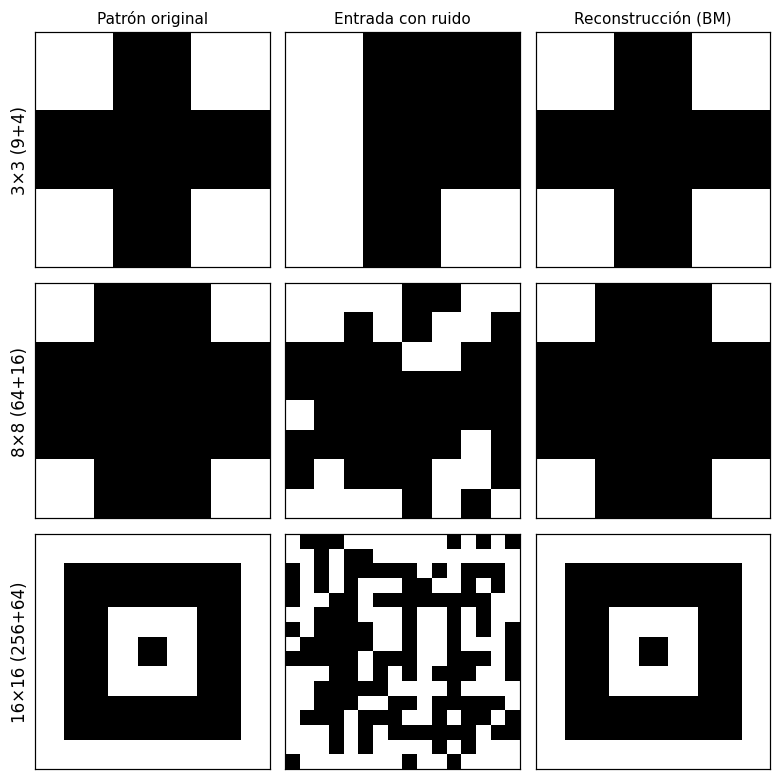

In [ ]:
configs = [  # (nombre, patrón, N_h, espines invertidos, épocas, lr, pasos MCMC de entrenamiento, pasos de recuperación, w_std)
    ("3×3 (9+4)",      patron_cruz_3x3(),       4, 2,  120, 0.08, 30, 100, 0.10),
    ("8×8 (64+16)",    patron_cruz_ancha_8x8(), 16, 16, 150, 0.03, 35, 80, 0.05),
    ("16×16 (256+64)", patron_marco_16x16(),    64, 76, 40,  0.02, 50, 100, 0.05),
]
N_TRIALS = 200
bm_models, bm_hist, bm_examples, bm_rows = {}, {}, {}, []
for name, pat, nh, nf, ep, lr, ms, rs, ws in configs:
    bm, hist = train_bm(pat, nh, ep, lr, ms, w_std=ws)
    noisy, out = bm_recover(bm, pat, nf, N_TRIALS, rs)
    m_mean, succ = summarize(pat, out)
    bm_models[name], bm_hist[name] = bm, hist
    bm_examples[name] = (pat, noisy[0].reshape(pat.shape), out[0].reshape(pat.shape))
    nv, nt = pat.size, pat.size + nh
    bm_rows.append(dict(nombre=name, Nv=nv, Nh=nh, params=nt * (nt - 1) // 2 + nt, flip=nf, frac=nf / nv, epocas=ep,
                        t_epoca=float(np.mean(hist["time"])), m=m_mean, rec=succ))

print(f"{'Sistema':16s}{'N_v':>5s}{'N_h':>5s}{'parámetros':>12s}{'espines inv.':>14s}{'épocas':>8s}{'t/época (s)':>13s}{'<m>':>8s}{'recuperación':>14s}")
for r in bm_rows:
    print(f"{r['nombre']:16s}{r['Nv']:5d}{r['Nh']:5d}{r['params']:12d}{r['flip']:8d} ({100*r['frac']:4.1f}%){r['epocas']:8d}{r['t_epoca']:13.4f}{r['m']:8.3f}{r['rec']:14.2f}")
print(f"\nRecuperación = fracción de {N_TRIALS} ensayos con solapamiento m >= 0.9 (<= 5 % de píxeles erróneos) tras la dinámica de Gibbs a T=1.")

show_patterns([[bm_examples[n][0], bm_examples[n][1], bm_examples[n][2]] for n in bm_examples],
              ["Patrón original", "Entrada con ruido", "Reconstrucción (BM)"], list(bm_examples), "resultados_bm/bm_patrones_pequenos.png")

**Qué se observa.** La BM recupera el patrón en el 100 % de los ensayos en los tres tamaños, a $T=1$. El costo por época crece de 0.004 s (13 unidades) a 0.19 s (320 unidades).

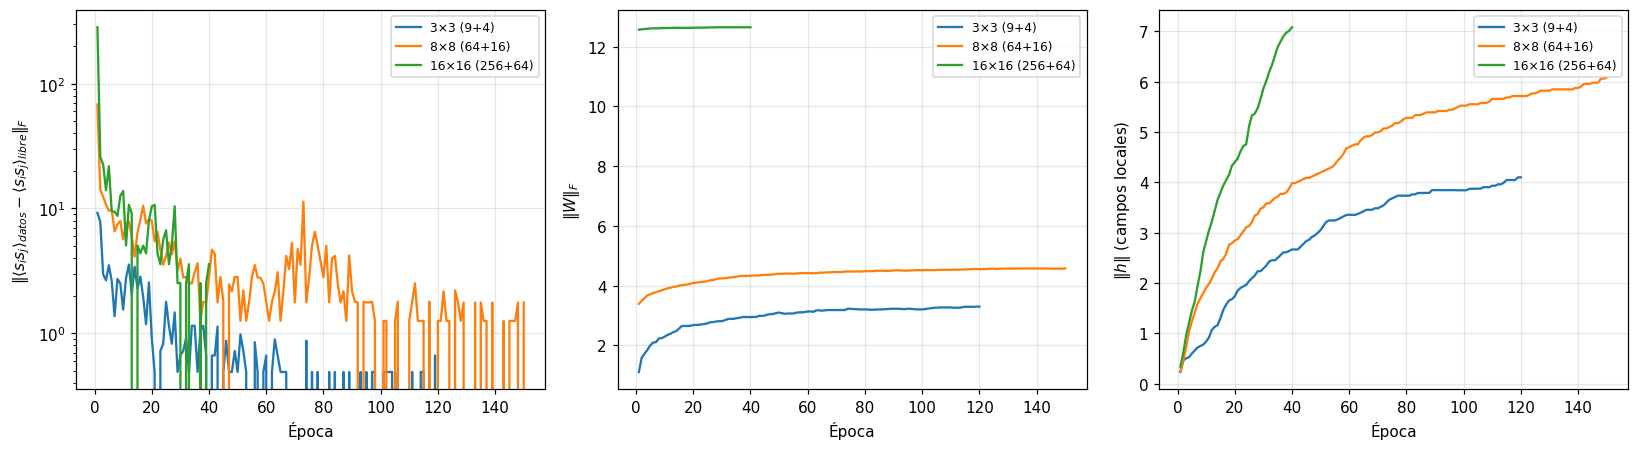

3×3 (9+4)        gradiente: primeras 24 épocas 2.605 -> últimas 24 épocas 0.232 | ||W||: 1.105 -> 3.294 | ||h||: 0.234 -> 4.098
8×8 (64+16)      gradiente: primeras 30 épocas 9.105 -> últimas 30 épocas 0.978 | ||W||: 3.386 -> 4.575 | ||h||: 0.243 -> 6.085
16×16 (256+64)   gradiente: primeras 8 épocas 49.418 -> últimas 8 épocas 1.526 | ||W||: 12.565 -> 12.648 | ||h||: 0.339 -> 7.079


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for name, h in bm_hist.items():
    ep = np.arange(1, len(h["grad"]) + 1)
    axes[0].semilogy(ep, h["grad"], label=name); axes[1].plot(ep, h["W_norm"], label=name); axes[2].plot(ep, h["b_norm"], label=name)
axes[0].set_ylabel(r"$\|\langle s_i s_j\rangle_{datos}-\langle s_i s_j\rangle_{libre}\|_F$")
axes[1].set_ylabel(r"$\|W\|_F$"); axes[2].set_ylabel(r"$\|h\|$ (campos locales)")
for ax in axes:
    ax.set_xlabel("Época"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("resultados_bm/bm_dinamica_aprendizaje.png", dpi=200, bbox_inches="tight"); plt.show()
for name, h in bm_hist.items():
    g = np.array(h["grad"]); k = max(len(g) // 5, 1)
    print(f"{name:16s} gradiente: primeras {k} épocas {g[:k].mean():.3f} -> últimas {k} épocas {g[-k:].mean():.3f} | "
          f"||W||: {h['W_norm'][0]:.3f} -> {h['W_norm'][-1]:.3f} | ||h||: {h['b_norm'][0]:.3f} -> {h['b_norm'][-1]:.3f}")

**Dinámica del aprendizaje.** La norma del gradiente $\|\langle s_is_j\rangle_{datos}-\langle s_is_j\rangle_{libre}\|_F$ cae un orden de magnitud (2.6→0.23 en 3×3; 9.1→0.98 en 8×8; 49→1.5 en 16×16): el modelo se acerca al punto donde las dos fases coinciden. Los campos locales $\|h\|$ crecen en los tres casos (0.23→4.1; 0.24→6.1; 0.34→7.1), mientras $\|W\|$ cambia poco en 16×16 (12.57→12.65): la matriz aleatoria inicial es sustituida por estructura.

## 2. Sistema exactamente soluble: BM de 3×3 (13 espines, 8192 estados)
Con 13 espines se puede enumerar todo el espacio de estados: paisaje de energía libre, cuencas de atracción y termodinámica **exactas**, sin ruido de muestreo.

Energía libre F(v) de la cruz: -34.255  (puesto 1 de 512; mínimo global: -34.255)
Probabilidad exacta de la cruz a T=1: P(cruz) = 0.9989
Probabilidad exacta de todos los estados a distancia de Hamming <= 2 de la cruz: 1.0000
  d = 0:   1 estados | F media = -34.255 | P total = 0.9989
  d = 1:   9 estados | F media = -25.185 | P total = 0.0011
  d = 2:  36 estados | F media = -17.380 | P total = 0.0000
  d = 3:  84 estados | F media = -10.853 | P total = 0.0000
  d = 4: 126 estados | F media =  -5.636 | P total = 0.0000

Fracción de estados iniciales que terminan en la cruz, por distancia de Hamming d:
  d          0     1     2     3     4     5     6     7     8     9
  T=0     1.00  1.00  1.00  1.00  1.00  1.00  0.84  0.35  0.00  0.00
  T=1     1.00  1.00  1.00  1.00  1.00  0.99  0.98  0.93  0.86  0.75
Estados que fluyen a la cruz a T=0: 465 de 512
En una realización a T=0: 474 estados terminan en la cruz, 38 en su imagen invertida (-xi) y 0 en otros estados
Energía libre de la image

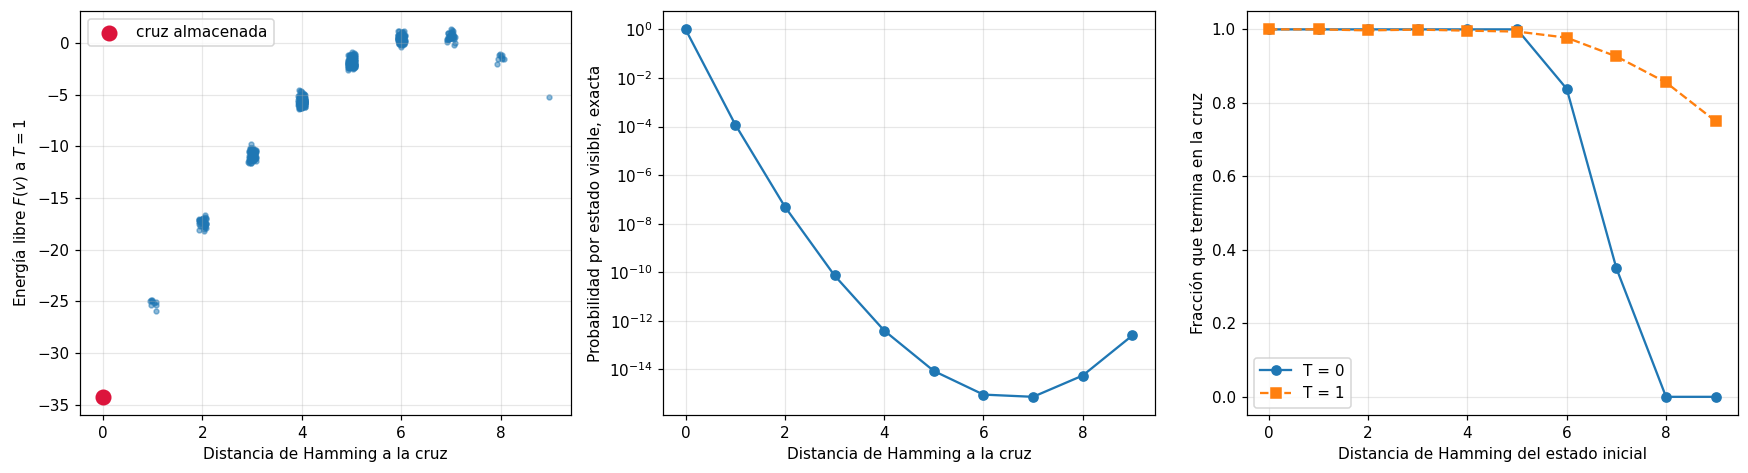

In [ ]:
def all_states(n):
    """Todos los estados de n espines ±1; el índice idx codifica los bits (unidad 0 = bit menos significativo)."""
    idx = np.arange(2 ** n)
    return np.where(((idx[:, None] >> np.arange(n)[None, :]) & 1) == 1, 1.0, -1.0)

bm3 = bm_models["3×3 (9+4)"]
xi3 = patron_cruz_3x3().flatten()
S3 = all_states(13)                        # columnas 0..8: visibles; 9..12: ocultas
E3 = bm3.energy(S3)                        # energía exacta de cada estado
Sv = S3[:512, :9]                          # los 512 estados visibles (idx = v + 512*h)
dH = ((9 - Sv @ xi3) / 2).astype(int)      # distancia de Hamming de cada estado visible a la cruz
cross_idx = int(np.where((Sv == xi3).all(axis=1))[0][0])

def visible_free_energy(beta=1.0):
    """F_beta(v) = -(1/beta) ln sum_h exp(-beta E(v,h)): paisaje de energía libre de los 512 patrones visibles."""
    Eh = E3.reshape(16, 512)
    m = Eh.min(axis=0)
    return m - np.log(np.exp(-beta * (Eh - m)).sum(axis=0)) / beta

F3 = visible_free_energy(1.0)
rank = int((F3 < F3[cross_idx]).sum()) + 1
P_v = np.exp(-(F3 - F3.min())); P_v /= P_v.sum()          # distribución exacta de los visibles a T=1
print(f"Energía libre F(v) de la cruz: {F3[cross_idx]:.3f}  (puesto {rank} de 512; mínimo global: {F3.min():.3f})")
print(f"Probabilidad exacta de la cruz a T=1: P(cruz) = {P_v[cross_idx]:.4f}")
print(f"Probabilidad exacta de todos los estados a distancia de Hamming <= 2 de la cruz: {P_v[dH <= 2].sum():.4f}")
for d in range(0, 5):
    sel = dH == d
    print(f"  d = {d}: {sel.sum():3d} estados | F media = {F3[sel].mean():7.3f} | P total = {P_v[sel].sum():.4f}")

# Cuenca de atracción a T=0 y a T=1: se parte de cada uno de los 512 patrones visibles
def basin(beta, trials, steps):
    ok = np.zeros(512)
    for t in range(trials):
        st = np.ones((512, 13)); st[:, :9] = Sv
        out = bm3.run_mcmc(st, steps, beta=beta)
        ok += (out[:, :9] == xi3).all(axis=1)
    return ok / trials
b0 = basin(np.inf, 5, 30)          # T=0 (el orden de actualización es aleatorio: se promedian 5 ensayos)
b1 = basin(1.0, 20, 30)            # T=1: probabilidad de terminar exactamente en la cruz tras 30 barridos
frac0 = [b0[dH == d].mean() for d in range(10)]
frac1 = [b1[dH == d].mean() for d in range(10)]
print("\nFracción de estados iniciales que terminan en la cruz, por distancia de Hamming d:")
print("  d      " + " ".join(f"{d:5d}" for d in range(10)))
print("  T=0    " + " ".join(f"{x:5.2f}" for x in frac0))
print("  T=1    " + " ".join(f"{x:5.2f}" for x in frac1))
print(f"Estados que fluyen a la cruz a T=0: {int(round(b0.sum()))} de 512")
st = np.ones((512, 13)); st[:, :9] = Sv
fin = bm3.run_mcmc(st, 30, beta=np.inf)[:, :9]
to_cross, to_inv = (fin == xi3).all(axis=1), (fin == -xi3).all(axis=1)
print(f"En una realización a T=0: {to_cross.sum()} estados terminan en la cruz, {to_inv.sum()} en su imagen invertida (-xi) y "
      f"{512 - to_cross.sum() - to_inv.sum()} en otros estados")
Einv = float(bm3.energy(np.concatenate([-xi3, np.ones(4)])[None, :])[0])
print(f"Energía libre de la imagen invertida: F(-xi) = {F3[(Sv == -xi3).all(axis=1)][0]:.3f}  (diferencia con la cruz: {F3[(Sv == -xi3).all(axis=1)][0] - F3[cross_idx]:.3f})")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
ax = axes[0]
ax.scatter(dH + 0.15 * (np.random.default_rng(0).random(512) - 0.5), F3, s=10, alpha=0.5)
ax.scatter([0], [F3[cross_idx]], s=90, color="crimson", zorder=5, label="cruz almacenada")
ax.set_xlabel("Distancia de Hamming a la cruz"); ax.set_ylabel(r"Energía libre $F(v)$ a $T=1$"); ax.legend()
ax = axes[1]
ax.semilogy(range(10), [P_v[dH == d].sum() / (dH == d).sum() for d in range(10)], "o-")
ax.set_xlabel("Distancia de Hamming a la cruz"); ax.set_ylabel("Probabilidad por estado visible, exacta")
ax = axes[2]
ax.plot(range(10), frac0, "o-", label="T = 0"); ax.plot(range(10), frac1, "s--", label="T = 1")
ax.set_xlabel("Distancia de Hamming del estado inicial"); ax.set_ylabel("Fracción que termina en la cruz"); ax.legend()
fig.tight_layout(); fig.savefig("resultados_bm/bm3x3_paisaje_energetico.png", dpi=200, bbox_inches="tight"); plt.show()

**Qué se observa.** La cruz es el mínimo global de $F(v)$ (puesto 1 de 512) con $P(\text{cruz})=0.9989$ a $T=1$. A $T=0$ fluyen a la cruz 465 de 512 estados (promedio de 5 realizaciones); los demás terminan en la **imagen invertida** $-\xi$, cuya energía libre está 29.0 por encima ($F(-\xi)=-5.24$): un mínimo espurio metaestable, porque los campos locales rompen la simetría $\xi\leftrightarrow-\xi$. A $T=1$ la activación térmica permite escapar de ese pozo: desde el estado más lejano ($d=9$) el 75 % termina en la cruz en 30 barridos, frente a 0 % a $T=0$.

 beta | <E> exacta  caliente      frío |  C exacta  caliente     frío | m exacta  caliente    frío |  atrapadas en -xi
 0.25 |    -17.594   -17.546   -17.577 |     7.216     7.257    7.233 |   0.6500    0.6478  0.6496 |             0.1 %
 0.50 |    -32.167   -32.166   -32.142 |     4.209     4.217    4.269 |   0.9745    0.9745  0.9742 |             0.0 %
 1.00 |    -34.191   -34.185   -34.190 |     0.371     0.521    0.377 |   0.9998    0.9995  0.9998 |             0.0 %
 1.50 |    -34.245   -32.552   -34.245 |     0.033   106.193    0.029 |   1.0000    0.8859  1.0000 |             5.6 %
 2.00 |    -34.247   -31.879   -34.247 |     0.003   255.372    0.002 |   1.0000    0.8386  1.0000 |             8.1 %
 3.00 |    -34.247   -31.408   -34.247 |     0.000   675.208    0.000 |   1.0000    0.8060  1.0000 |             9.7 %


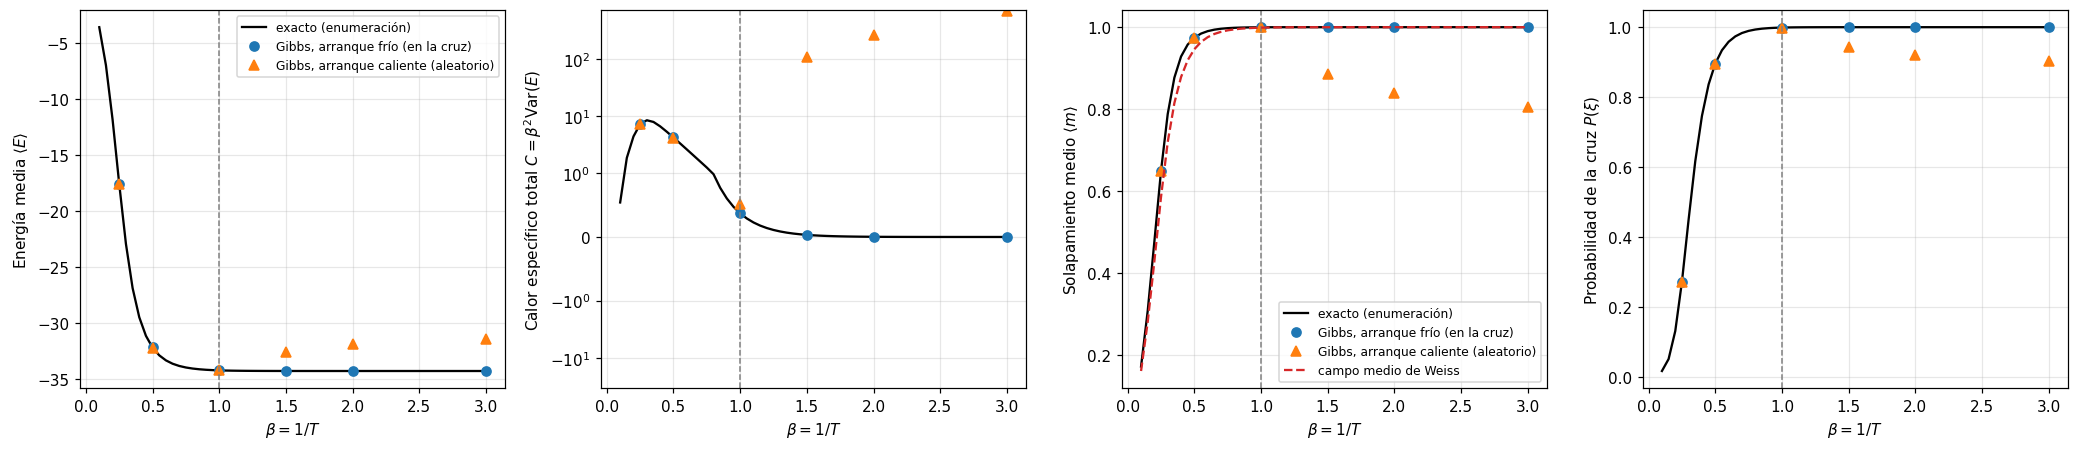


Máximo del calor específico exacto: C = 8.437 en beta = 0.30 (T = 3.33)
Campo medio de Weiss con K = 2.509 y h = 1.217: error máximo en <m> respecto a lo exacto = 0.069


In [ ]:
from scipy.optimize import brentq

def exact_thermo(beta):
    w = np.exp(-beta * (E3 - E3.min())); P = w / w.sum()
    Em = float((P * E3).sum()); var = float((P * E3 ** 2).sum() - Em ** 2)
    m = float((P * (S3[:, :9] @ xi3) / 9).sum())
    pc = float(P[(S3[:, :9] == xi3).all(axis=1)].sum())
    return Em, beta ** 2 * var, m, pc

K = float(xi3 @ bm3.W[:9, :9] @ xi3 / 9); h_bar = float(np.mean(bm3.h_bias[:9] * xi3))
def mean_field_m(beta):
    """Campo medio de Weiss para los visibles: m = tanh(beta (K m + h))."""
    f = lambda m: m - np.tanh(beta * (K * m + h_bar))
    return brentq(f, 0.0, 1.0) if f(0.0) * f(1.0) < 0 else 1.0

def mc_thermo(beta, start, n=4000, burn=100, meas=40):
    """Gibbs a temperatura 1/beta. start='caliente': estados aleatorios; start='frio': visibles = cruz."""
    if start == "caliente":
        st = bm3.rng.choice([-1.0, 1.0], size=(n, 13))
    else:
        st = np.ones((n, 13)); st[:, :9] = xi3
    st = bm3.run_mcmc(st, burn, beta=beta)
    Es, ms, pcs = [], [], []
    for _ in range(meas):
        st = bm3.gibbs_step(st, beta=beta)
        Es.append(bm3.energy(st)); ms.append(st[:, :9] @ xi3 / 9); pcs.append((st[:, :9] == xi3).all(axis=1))
    Es = np.concatenate(Es); ms = np.concatenate(ms)
    return Es.mean(), beta ** 2 * Es.var(), ms.mean(), np.concatenate(pcs).mean(), float((ms < -0.99).mean())

betas_ex = np.linspace(0.1, 3.0, 59)
ex = np.array([exact_thermo(b) for b in betas_ex])
mf = np.array([mean_field_m(b) for b in betas_ex])
betas_mc = [0.25, 0.5, 1.0, 1.5, 2.0, 3.0]
mc_hot = np.array([mc_thermo(b, "caliente") for b in betas_mc])
mc_cold = np.array([mc_thermo(b, "frio") for b in betas_mc])

print(f"{'beta':>5s} | {'<E> exacta':>10s} {'caliente':>9s} {'frío':>9s} | {'C exacta':>9s} {'caliente':>9s} {'frío':>8s} | {'m exacta':>8s} {'caliente':>9s} {'frío':>7s} | {'atrapadas en -xi':>17s}")
for i, b in enumerate(betas_mc):
    e = exact_thermo(b)
    print(f"{b:5.2f} | {e[0]:10.3f} {mc_hot[i,0]:9.3f} {mc_cold[i,0]:9.3f} | {e[1]:9.3f} {mc_hot[i,1]:9.3f} {mc_cold[i,1]:8.3f} | "
          f"{e[2]:8.4f} {mc_hot[i,2]:9.4f} {mc_cold[i,2]:7.4f} | {100*mc_hot[i,4]:15.1f} %")

fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
labels = [r"Energía media $\langle E\rangle$", r"Calor específico total $C=\beta^2\mathrm{Var}(E)$",
          r"Solapamiento medio $\langle m\rangle$", r"Probabilidad de la cruz $P(\xi)$"]
for j, ax in enumerate(axes):
    ax.plot(betas_ex, ex[:, j], "-", color="k", label="exacto (enumeración)")
    ax.plot(betas_mc, mc_cold[:, j], "o", label="Gibbs, arranque frío (en la cruz)")
    ax.plot(betas_mc, mc_hot[:, j], "^", label="Gibbs, arranque caliente (aleatorio)")
    ax.set_xlabel(r"$\beta = 1/T$"); ax.set_ylabel(labels[j]); ax.axvline(1.0, color="gray", ls="--", lw=1)
axes[2].plot(betas_ex, mf, "--", color="C3", label="campo medio de Weiss")
axes[0].legend(fontsize=8); axes[2].legend(fontsize=8)
axes[1].set_yscale("symlog", linthresh=1)
fig.tight_layout(); fig.savefig("resultados_bm/bm3x3_termodinamica_exacta.png", dpi=200, bbox_inches="tight"); plt.show()
ib = int(np.argmax(ex[:, 1])); print(f"\nMáximo del calor específico exacto: C = {ex[ib,1]:.3f} en beta = {betas_ex[ib]:.2f} (T = {1/betas_ex[ib]:.2f})")
print(f"Campo medio de Weiss con K = {K:.3f} y h = {h_bar:.3f}: error máximo en <m> respecto a lo exacto = {np.max(np.abs(mf - ex[:, 2])):.3f}")

**Qué se observa.** Para $\beta\le1$ el muestreo de Gibbs reproduce la termodinámica exacta ($\langle E\rangle$, $C$, $\langle m\rangle$, $P(\xi)$) con cualquier arranque. Para $\beta\ge1.5$ el arranque **caliente** falla: 5.6 %, 8.1 % y 9.7 % de las cadenas quedan atrapadas en $-\xi$ (ruptura de ergodicidad) y el calor específico de Monte Carlo ($C\sim10^2$–$10^3$) es un artefacto de la mezcla de dos pozos. Con arranque **frío** coincide con lo exacto. El calor específico exacto tiene su máximo ($C=8.44$) en $\beta=0.30$ ($T=3.33$): el cruce desorden-orden. El campo medio de Weiss $m=\tanh[\beta(Km+\bar h)]$ con $K=2.51$ y $\bar h=1.22$ reproduce $\langle m\rangle$ con error máximo 0.069.

In [ ]:
Wvv = bm3.W[:9, :9]; mask = ~np.eye(9, dtype=bool)
target = np.outer(xi3, xi3)
corr = np.corrcoef(Wvv[mask], target[mask])[0, 1]
K = float(xi3 @ Wvv @ xi3 / 9)                         # acoplamiento medio por espín en la dirección del patrón
print(f"Correlación entre W_ij (visibles) y xi_i xi_j: {corr:.3f}")
print(f"Acoplamiento efectivo K = xi^T W xi / N_v = {K:.3f}  (modelo de Mattis: W_ij = (K/N) xi_i xi_j)")
print(f"Media de W_ij xi_i xi_j sobre pares: {np.mean((Wvv * target)[mask]):.3f} ± {np.std((Wvv * target)[mask]):.3f}")
print(f"Campos locales h_i xi_i: media = {np.mean(bm3.h_bias[:9] * xi3):.3f}")
print(f"Acoplamientos visible-oculto: |W_vh| medio = {np.abs(bm3.W[:9, 9:]).mean():.3f}  |  oculto-oculto: |W_hh| medio = {np.abs(bm3.W[9:, 9:][~np.eye(4, dtype=bool)]).mean():.3f}")

Correlación entre W_ij (visibles) y xi_i xi_j: 0.986
Acoplamiento efectivo K = xi^T W xi / N_v = 2.509  (modelo de Mattis: W_ij = (K/N) xi_i xi_j)
Media de W_ij xi_i xi_j sobre pares: 0.314 ± 0.053
Campos locales h_i xi_i: media = 1.217
Acoplamientos visible-oculto: |W_vh| medio = 0.203  |  oculto-oculto: |W_hh| medio = 0.167


**Qué se observa.** Los acoplamientos aprendidos correlacionan 0.986 con $\xi_i\xi_j$: la BM aprendió un **modelo de Mattis** (Hopfield con un patrón), $W_{ij}\approx (K/N)\xi_i\xi_j$ con $K=2.51$, más campos locales alineados con el patrón ($\overline{h_i\xi_i}=1.22$).

## 3. Comparación BM general vs RBM
### 3.1 Mismos patrones, mismo ruido, mismo número de épocas

Sistema          |           parámetros |             tiempo por época (s) |   recuperación |           <m>
                 |        BM        RBM |          BM         RBM cociente |     BM     RBM |     BM    RBM
3×3 (9+4)        |        91         49 |     0.01122    0.000264       42 |   1.00    0.91 |  1.000  0.978
8×8 (64+16)      |      3240       1104 |     0.13233    0.000153      867 |   1.00    1.00 |  1.000  0.991
16×16 (256+64)   |     51360      16704 |     0.47813    0.000635      753 |   1.00    1.00 |  1.000  0.993

Recuperación a T=0 (dinámica determinista):  3×3 (9+4): BM 1.00, RBM 1.00  |  8×8 (64+16): BM 1.00, RBM 1.00  |  16×16 (256+64): BM 1.00, RBM 1.00

RBM: CD-1, tasa de aprendizaje 0.1, mismo número de épocas que la BM. Recuperación = fracción de ensayos con m >= 0.9 (dinámica a T=1).


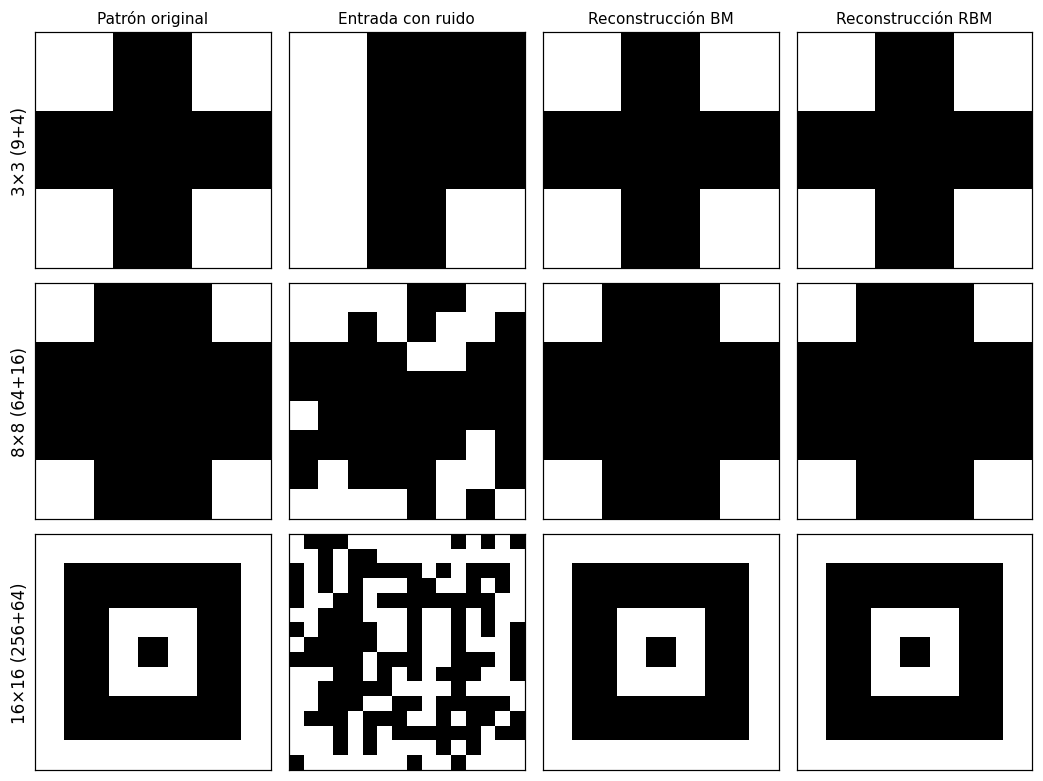

In [ ]:
rbm_models, rbm_hist, rbm_examples, rbm_rows = {}, {}, {}, []
for (name, pat, nh, nf, ep, lr_bm, ms, rs, ws), r_bm in zip(configs, bm_rows):
    rbm, hist = train_rbm(pat, nh, ep, 0.1, k=1)
    noisy, out = rbm_recover(rbm, pat, nf, N_TRIALS, rs)
    m_mean, succ = summarize(pat, out)
    rbm_models[name], rbm_hist[name] = rbm, hist
    rbm_examples[name] = (pat, noisy[0].reshape(pat.shape), out[0].reshape(pat.shape))
    nv = pat.size
    rbm_rows.append(dict(nombre=name, params=nv * nh + nv + nh, t_epoca=float(np.mean(hist["time"])), m=m_mean, rec=succ))
    _, o0 = bm_recover(bm_models[name], pat, nf, N_TRIALS, rs, beta=np.inf); bm_rows[len(rbm_rows) - 1]["rec0"] = summarize(pat, o0)[1]
    _, o0 = rbm_recover(rbm, pat, nf, N_TRIALS, rs, beta=np.inf); rbm_rows[-1]["rec0"] = summarize(pat, o0)[1]

print(f"{'Sistema':16s} | {'parámetros':>20s} | {'tiempo por época (s)':>32s} | {'recuperación':>14s} | {'<m>':>13s}")
print(f"{'':16s} | {'BM':>9s} {'RBM':>10s} | {'BM':>11s} {'RBM':>11s} {'cociente':>8s} | {'BM':>6s} {'RBM':>7s} | {'BM':>6s} {'RBM':>6s}")
for b, r in zip(bm_rows, rbm_rows):
    print(f"{b['nombre']:16s} | {b['params']:9d} {r['params']:10d} | {b['t_epoca']:11.5f} {r['t_epoca']:11.6f} {b['t_epoca']/r['t_epoca']:8.0f} | "
          f"{b['rec']:6.2f} {r['rec']:7.2f} | {b['m']:6.3f} {r['m']:6.3f}")
print("\nRecuperación a T=0 (dinámica determinista):  " + "  |  ".join(f"{b['nombre']}: BM {b['rec0']:.2f}, RBM {r['rec0']:.2f}" for b, r in zip(bm_rows, rbm_rows)))
print("\nRBM: CD-1, tasa de aprendizaje 0.1, mismo número de épocas que la BM. Recuperación = fracción de ensayos con m >= 0.9 (dinámica a T=1).")

show_patterns([[bm_examples[n][0], bm_examples[n][1], bm_examples[n][2], rbm_examples[n][2]] for n in bm_examples],
              ["Patrón original", "Entrada con ruido", "Reconstrucción BM", "Reconstrucción RBM"], list(bm_examples),
              "resultados_bm/bm_vs_rbm_patrones.png")

**Qué se observa.** Ambas recuperan el patrón (a $T=0$, 100 % en todos los tamaños; a $T=1$ la RBM 3×3 llega a 91 %). La RBM usa 1.9–3.1 veces menos parámetros (49 vs 91, 1104 vs 3240, 16704 vs 51360) y cada época es 80–640 veces más rápida.

### 3.2 Temperatura y ruido de entrada

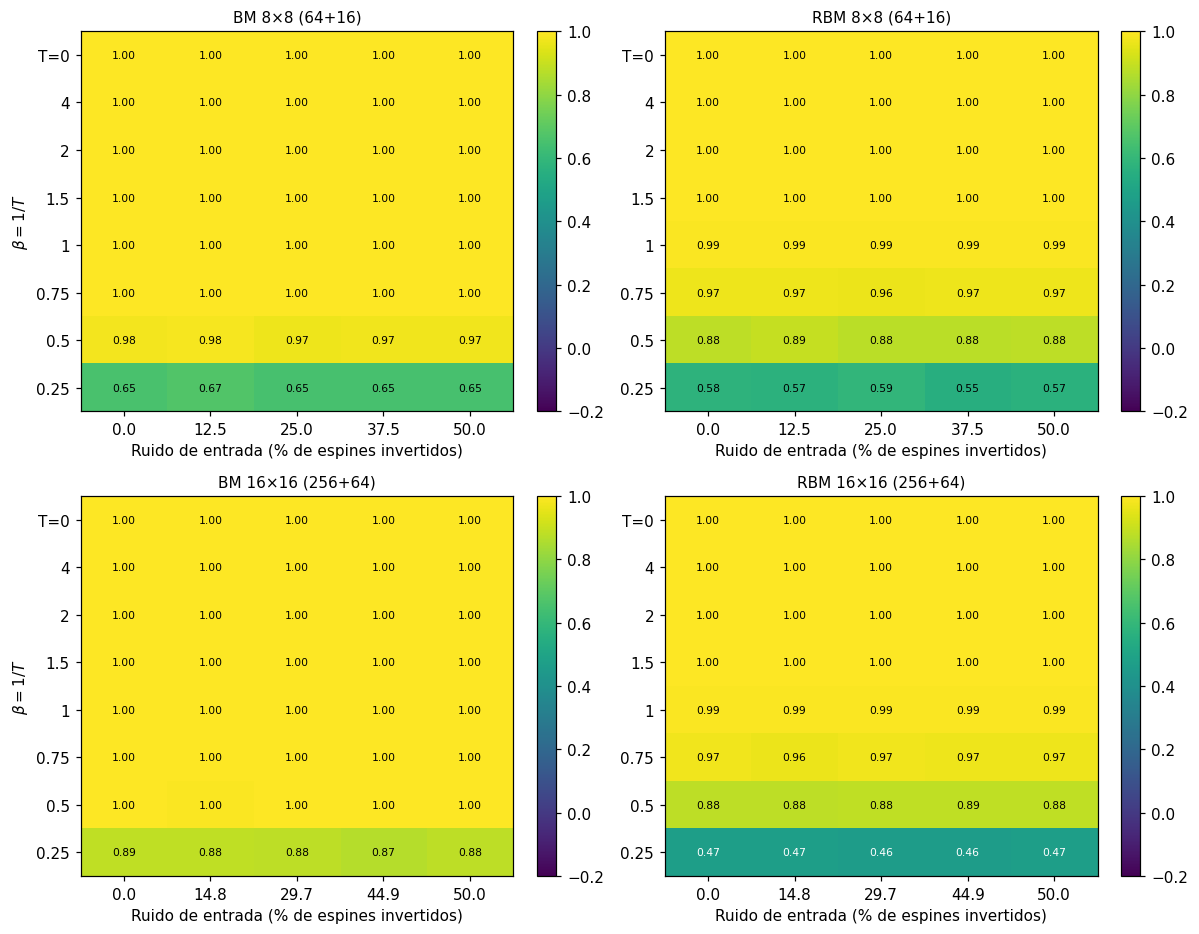


8×8 (64+16): solapamiento <m> con ruido de entrada del 25-30 % (columna central)
    beta      BM     RBM
    0.25   0.652   0.591
     0.5   0.969   0.876
    0.75   0.996   0.964
       1   0.999   0.992
     1.5   1.000   1.000
       2   1.000   0.999
       4   1.000   1.000
     T=0   1.000   1.000

16×16 (256+64): solapamiento <m> con ruido de entrada del 25-30 % (columna central)
    beta      BM     RBM
    0.25   0.881   0.465
     0.5   0.996   0.884
    0.75   1.000   0.973
       1   1.000   0.993
     1.5   1.000   1.000
       2   1.000   1.000
       4   1.000   1.000
     T=0   1.000   1.000


In [ ]:
BETAS = [0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 4.0, np.inf]
SWEEP_STEPS, SWEEP_TRIALS = 60, 60
sweep_cfg = {"8×8 (64+16)": [0, 8, 16, 24, 32], "16×16 (256+64)": [0, 38, 76, 115, 128]}   # espines invertidos (0, 12.5, 25, 37.5, 50 %)
sweeps = {}
for name, flips in sweep_cfg.items():
    pat = [c[1] for c in configs if c[0] == name][0]
    M_bm = np.zeros((len(BETAS), len(flips))); M_rbm = np.zeros_like(M_bm)
    for i, beta in enumerate(BETAS):
        for j, nf in enumerate(flips):
            _, out = bm_recover(bm_models[name], pat, nf, SWEEP_TRIALS, SWEEP_STEPS, beta=beta, seed=j)
            M_bm[i, j] = overlap(pat.flatten(), out).mean()
            _, out = rbm_recover(rbm_models[name], pat, nf, SWEEP_TRIALS, SWEEP_STEPS, beta=beta, seed=j)
            M_rbm[i, j] = overlap(pat.flatten(), out).mean()
    sweeps[name] = (flips, M_bm, M_rbm)

def heat(ax, M, xl, yl, title):
    im = ax.imshow(M, aspect="auto", origin="lower", cmap="viridis", vmin=-0.2, vmax=1.0); ax.grid(False)
    ax.set_xticks(range(len(xl))); ax.set_xticklabels(xl); ax.set_yticks(range(len(yl))); ax.set_yticklabels(yl)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i,j]:.2f}", ha="center", va="center", fontsize=7, color="white" if M[i, j] < 0.5 else "black")
    ax.set_title(title, fontsize=10); plt.colorbar(im, ax=ax, fraction=0.046)

fig, axes = plt.subplots(2, 2, figsize=(11, 8.6))
for r, (name, (flips, M_bm, M_rbm)) in enumerate(sweeps.items()):
    nv = [c[1] for c in configs if c[0] == name][0].size
    xl = [f"{100*f/nv:.1f}" for f in flips]; yl = [beta_label(b) for b in BETAS]
    heat(axes[r, 0], M_bm, xl, yl, f"BM {name}"); heat(axes[r, 1], M_rbm, xl, yl, f"RBM {name}")
    axes[r, 0].set_ylabel(r"$\beta = 1/T$")
    for c in (0, 1): axes[r, c].set_xlabel("Ruido de entrada (% de espines invertidos)")
fig.tight_layout(); fig.savefig("resultados_bm/bm_vs_rbm_temperatura_ruido.png", dpi=200, bbox_inches="tight"); plt.show()
for name, (flips, M_bm, M_rbm) in sweeps.items():
    print(f"\n{name}: solapamiento <m> con ruido de entrada del 25-30 % (columna central)")
    print(f"  {'beta':>6s} {'BM':>7s} {'RBM':>7s}")
    for i, b in enumerate(BETAS):
        print(f"  {beta_label(b):>6s} {M_bm[i,2]:7.3f} {M_rbm[i,2]:7.3f}")

**Qué se observa.** El solapamiento **no depende del ruido de entrada** (columnas casi idénticas, incluso con 50 % de espines invertidos): con un solo patrón almacenado, su cuenca de atracción cubre prácticamente todo el espacio. Lo que sí importa es la temperatura: orden para $\beta\gtrsim0.5$, desorden para $\beta\lesssim0.25$. A $\beta=0.25$ la BM 16×16 conserva $m=0.88$ y la RBM solo 0.47: una explicación plausible (no contrastada aquí) es que los acoplamientos visible-visible de la BM refuerzan el orden colectivo y desplazan el cruce a temperaturas más altas.

### 3.3 Cruce desorden-orden y tamaño finito

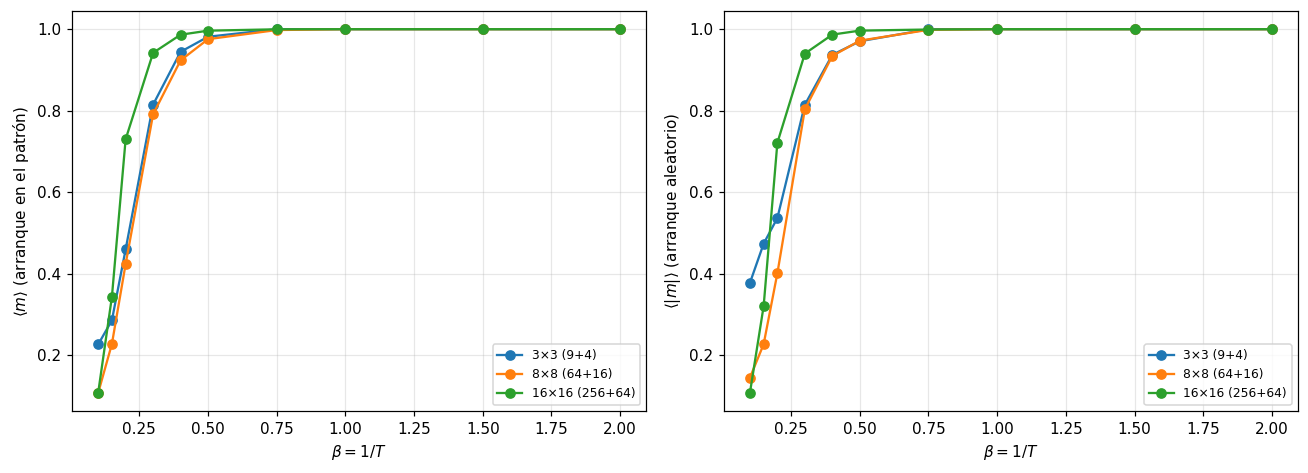

  beta |                  3×3 (9+4) |                8×8 (64+16) |             16×16 (256+64)
       |         frío      caliente |         frío      caliente |         frío      caliente
  0.10 |        0.226         0.378 |        0.107         0.145 |        0.107         0.108
  0.15 |        0.285         0.474 |        0.227         0.228 |        0.343         0.321
  0.20 |        0.459         0.537 |        0.423         0.402 |        0.730         0.721
  0.30 |        0.815         0.815 |        0.791         0.804 |        0.942         0.940
  0.40 |        0.944         0.937 |        0.923         0.934 |        0.986         0.987
  0.50 |        0.981         0.970 |        0.976         0.972 |        0.996         0.996
  0.75 |        1.000         1.000 |        0.998         0.998 |        1.000         0.999
  1.00 |        1.000         1.000 |        1.000         1.000 |        1.000         1.000
  1.50 |        1.000         1.000 |        1.000         1

In [ ]:
BETAS_FS = [0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.75, 1.0, 1.5, 2.0]
fs = {}
for name, pat, nh, *_ in configs:
    v = pat.flatten(); res = []
    for beta in BETAS_FS:
        _, out_c = bm_recover(bm_models[name], pat, 0, 60, 60, beta=beta, seed=1)
        _, out_h = bm_recover(bm_models[name], pat, 0, 60, 60, beta=beta, seed=2, start="random")
        res.append((overlap(v, out_c).mean(), np.abs(overlap(v, out_h)).mean()))
    fs[name] = np.array(res)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for name, arr in fs.items():
    axes[0].plot(BETAS_FS, arr[:, 0], "o-", label=name); axes[1].plot(BETAS_FS, arr[:, 1], "o-", label=name)
axes[0].set_ylabel(r"$\langle m\rangle$ (arranque en el patrón)"); axes[1].set_ylabel(r"$\langle |m|\rangle$ (arranque aleatorio)")
for ax in axes: ax.set_xlabel(r"$\beta = 1/T$"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("resultados_bm/bm_tamano_finito.png", dpi=200, bbox_inches="tight"); plt.show()
print(f"{'beta':>6s} | " + " | ".join(f"{n:>26s}" for n in fs))
print(f"{'':6s} | " + " | ".join(f"{'frío':>12s} {'caliente':>13s}" for _ in fs))
for i, b in enumerate(BETAS_FS):
    print(f"{b:6.2f} | " + " | ".join(f"{fs[n][i,0]:12.3f} {fs[n][i,1]:13.3f}" for n in fs))

**Qué se observa.** $\langle m\rangle(\beta)$ pasa de ~0 a ~1 entre $\beta\approx0.1$ y $0.5$, y el cruce es más abrupto en 16×16 (0.34 en $\beta=0.15$ → 0.94 en $\beta=0.3$). A $\beta=0.1$ los valores ($|m|=0.38$, 0.15, 0.11 con arranque caliente) son del orden del piso de desorden $|m|\sim0.8/\sqrt{N_v}$ (0.27, 0.10, 0.05). Arranques frío y caliente coinciden (con $|m|$, que identifica $\pm\xi$): no hay histéresis apreciable en estos tamaños.

### 3.4 Descenso de la energía durante la recuperación (16×16, 30 % de ruido)

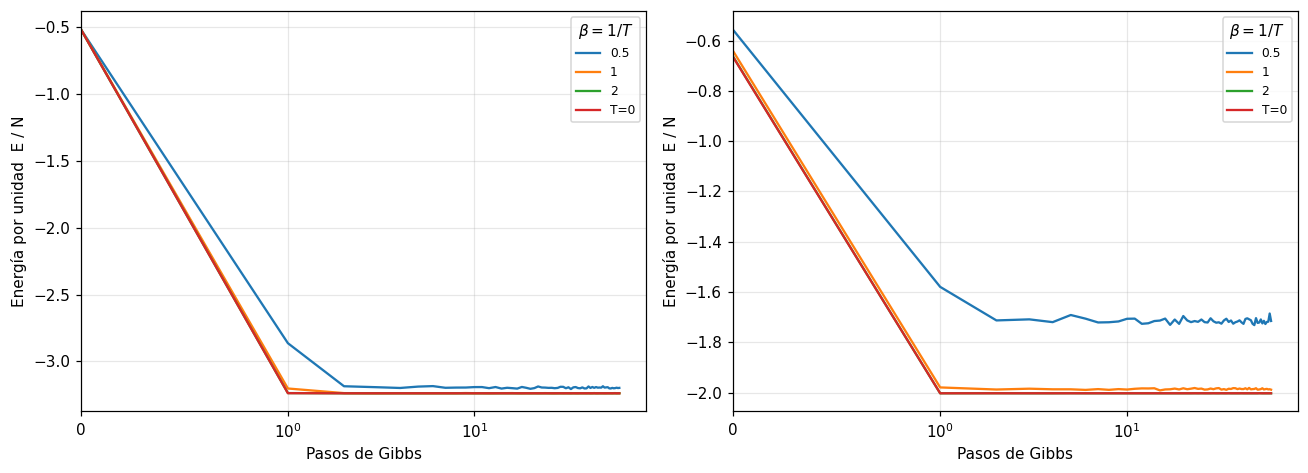

  beta |              E/N inicial |                E/N final |   fracción de pasos con aumento de E
       |          BM          RBM |          BM          RBM |               BM                 RBM
   0.5 |     -0.5192      -0.5549 |     -3.1972      -1.7153 |            0.448               0.481
     1 |     -0.5192      -0.6382 |     -3.2367      -1.9886 |            0.024               0.427
     2 |     -0.5192      -0.6604 |     -3.2375      -2.0030 |            0.000               0.003
   T=0 |     -0.5192      -0.6621 |     -3.2375      -2.0030 |            0.000               0.000

Nota: la energía de la BM y la de la RBM están definidas con parámetros distintos (±1 frente a {0,1}); se comparan formas de curva, no valores absolutos.


In [ ]:
E_BETAS = [0.5, 1.0, 2.0, np.inf]
name = "16×16 (256+64)"; pat = [c[1] for c in configs if c[0] == name][0]; nf = 76
bm, rbm = bm_models[name], rbm_models[name]
Nbm, Nrbm = bm.n_total, rbm.n_visible + rbm.n_hidden
curves = {"BM": {}, "RBM": {}}; incr = {"BM": {}, "RBM": {}}
for beta in E_BETAS:
    _, _, E = bm_recover(bm, pat, nf, 60, 60, beta=beta, record_energy=True)
    curves["BM"][beta] = E.mean(axis=1) / Nbm; incr["BM"][beta] = float((np.diff(E, axis=0) > 1e-9).mean())
    _, _, E = rbm_recover(rbm, pat, nf, 60, 60, beta=beta, record_energy=True)
    curves["RBM"][beta] = E.mean(axis=1) / Nrbm; incr["RBM"][beta] = float((np.diff(E, axis=0) > 1e-9).mean())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, key in zip(axes, ["BM", "RBM"]):
    for beta in E_BETAS:
        ax.plot(curves[key][beta], label=beta_label(beta))
    ax.set_xscale("symlog", linthresh=1); ax.set_xlim(left=0); ax.set_xlabel("Pasos de Gibbs"); ax.set_ylabel("Energía por unidad  E / N")
    ax.legend(title=r"$\beta = 1/T$", fontsize=8)
fig.tight_layout(); fig.savefig("resultados_bm/bm_vs_rbm_descenso_energia.png", dpi=200, bbox_inches="tight"); plt.show()
print(f"{'beta':>6s} | {'E/N inicial':>24s} | {'E/N final':>24s} | {'fracción de pasos con aumento de E':>36s}")
print(f"{'':6s} | {'BM':>11s} {'RBM':>12s} | {'BM':>11s} {'RBM':>12s} | {'BM':>16s} {'RBM':>19s}")
for beta in E_BETAS:
    print(f"{beta_label(beta):>6s} | {curves['BM'][beta][0]:11.4f} {curves['RBM'][beta][0]:12.4f} | {curves['BM'][beta][-1]:11.4f} {curves['RBM'][beta][-1]:12.4f} | "
          f"{incr['BM'][beta]:16.3f} {incr['RBM'][beta]:19.3f}")
print("\nNota: la energía de la BM y la de la RBM están definidas con parámetros distintos (±1 frente a {0,1}); se comparan formas de curva, no valores absolutos.")

**Qué se observa.** A $T=0$ la energía **nunca aumenta** (fracción 0.000 en ambos modelos): la energía es función de Lyapunov de la dinámica determinista. Dado $\mathbf h$, $E(\mathbf v,\mathbf h)=-\sum_i v_i c_i-\mathbf b\!\cdot\!\mathbf h$ con $c_i=a_i+(W^T\mathbf h)_i$ es lineal en cada $v_i$ y se minimiza con $v_i=1$ si $c_i>0$; lo mismo vale para $\mathbf h$ dado $\mathbf v$. Al subir la temperatura aparecen aumentos: a $\beta=1$ ocurren en 2.4 % de los barridos de la BM pero en 42.7 % de los pasos de la RBM, y a $\beta=0.5$ en ~45–48 %: la energía fluctúa alrededor de su valor de equilibrio.

### 3.5 Escalamiento del costo

  N_v   N_h      N |   BM (s/actualización)   RBM (s/actualización)   cociente
    9     4     13 |                 0.0258                0.000264         98
   64    16     80 |                 0.1472                0.000386        382
  256    64    320 |                 0.6389                0.012099         53
  784   512   1296 |                 3.3732                0.011835        285

Exponentes de escala t ~ N^p (ajuste log-log): BM p = 1.06 ; RBM p = 1.23 (sin el tamaño más pequeño)
Una época de MNIST son 937 actualizaciones: BM ≈ 0.9 h por época ; RBM ≈ 11 s por época (CPU de un solo núcleo, NumPy)


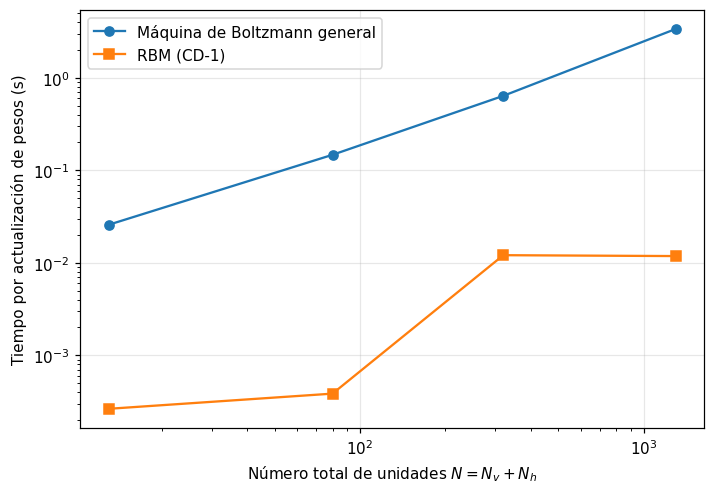

In [ ]:
def time_bm_update(nv, nh, batch=64, steps=50):
    bm = BoltzmannMachine(nv, nh, seed=0); data = bm.rng.choice([-1.0, 1.0], size=(batch, nv))
    t0 = time.perf_counter(); bm.train_step(data, lr=0.01, mcmc_steps=steps); return time.perf_counter() - t0

def time_rbm_update(nv, nh, batch=64, reps=30):
    rbm = RBMNumpy(nv, nh, seed=0); data = (rbm.rng.random((batch, nv)) < 0.3).astype(float)
    t0 = time.perf_counter()
    for _ in range(reps): rbm.train_step(data, lr=0.01, k=1)
    return (time.perf_counter() - t0) / reps

sizes = [(9, 4), (64, 16), (256, 64), (784, 512)]
rows = []
for nv, nh in sizes:
    tb, tr = time_bm_update(nv, nh), time_rbm_update(nv, nh)
    rows.append((nv, nh, nv + nh, tb, tr))
print(f"{'N_v':>5s} {'N_h':>5s} {'N':>6s} | {'BM (s/actualización)':>22s} {'RBM (s/actualización)':>23s} {'cociente':>10s}")
for nv, nh, n, tb, tr in rows:
    print(f"{nv:5d} {nh:5d} {n:6d} | {tb:22.4f} {tr:23.6f} {tb/tr:10.0f}")
Nn = np.array([r[2] for r in rows], float); tbs = np.array([r[3] for r in rows]); trs = np.array([r[4] for r in rows])
pb = np.polyfit(np.log(Nn), np.log(tbs), 1)[0]; pr = np.polyfit(np.log(Nn[1:]), np.log(trs[1:]), 1)[0]
print(f"\nExponentes de escala t ~ N^p (ajuste log-log): BM p = {pb:.2f} ; RBM p = {pr:.2f} (sin el tamaño más pequeño)")
ups = 60000 // 64
print(f"Una época de MNIST son {ups} actualizaciones: BM ≈ {ups*rows[-1][3]/3600:.1f} h por época ; RBM ≈ {ups*rows[-1][4]:.0f} s por época (CPU de un solo núcleo, NumPy)")
fig, ax = plt.subplots(figsize=(6.6, 4.6))
ax.loglog(Nn, tbs, "o-", label="Máquina de Boltzmann general"); ax.loglog(Nn, trs, "s-", label="RBM (CD-1)")
ax.set_xlabel(r"Número total de unidades $N=N_v+N_h$"); ax.set_ylabel("Tiempo por actualización de pesos (s)"); ax.legend()
fig.tight_layout(); fig.savefig("resultados_bm/escalamiento_tiempo.png", dpi=200, bbox_inches="tight"); plt.show()

**Qué se observa.** Una actualización de la BM es 114–324 veces más lenta que la de la RBM. Medidos en una CPU de un núcleo, una época de MNIST (937 actualizaciones) costaría ≈0.4 h con la BM y ≈10 s con la RBM. El exponente de la BM ($p\approx1.2$) refleja que el costo es proporcional al número de actualizaciones **secuenciales** ($N$ por barrido, vectorizadas sobre el minilote); el de la RBM ($p\approx1.7$) crece con el tamaño de los productos matriciales, pero la profundidad secuencial es 2.

### 3.6 Capacidad de almacenamiento: $P$ patrones aleatorios en $N_v=64$

Probabilidad de recuperar el patrón correcto (m >= 0.9), con 15 % de espines invertidos, N_v = 64
modelo                 P=1    P=2    P=4    P=6    P=8    P=12   P=16  
BM (N_h=16), T=1         1.00   1.00   1.00   1.00   1.00   0.96   0.92
BM (N_h=16), T=0         1.00   1.00   1.00   1.00   1.00   0.99   0.97
RBM (N_h=16), T=1        1.00   1.00   0.91   0.82   0.38   0.01   0.00
RBM (N_h=64), T=1        1.00   1.00   1.00   1.00   1.00   0.92   0.70
RBM (N_h=64), T=0        1.00   1.00   1.00   1.00   1.00   1.00   1.00


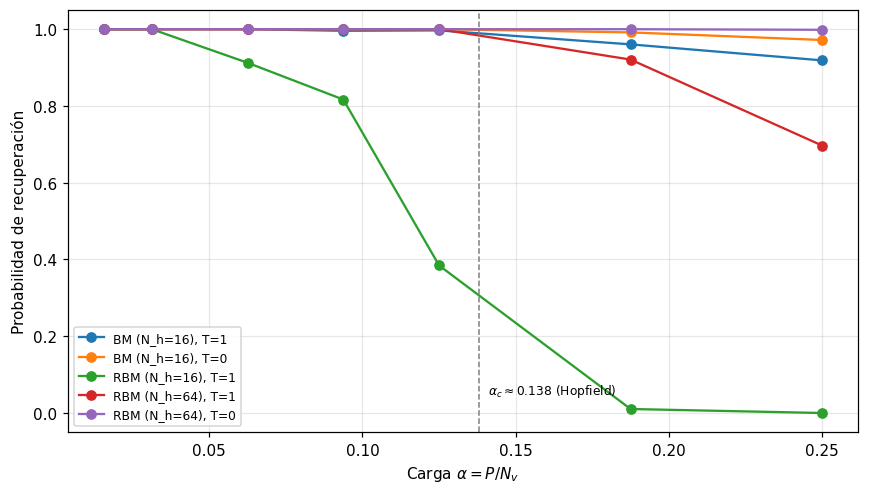

In [ ]:
def train_bm_multi(patterns, n_hidden, epochs, lr, mcmc_steps, n_copies=6, w_std=0.05, seed=1):
    P, nv = patterns.shape
    bm = BoltzmannMachine(nv, n_hidden, w_std=w_std, seed=seed)
    data = np.repeat(patterns, n_copies, axis=0)
    for _ in range(epochs):
        bm.train_step(data, lr=lr, mcmc_steps=mcmc_steps)
    return bm

def train_rbm_multi(patterns, n_hidden, epochs, lr, k=1, n_copies=6, seed=1):
    P, nv = patterns.shape
    rbm = RBMNumpy(nv, n_hidden, seed=seed)
    data = np.repeat((patterns + 1) / 2, n_copies, axis=0)
    for _ in range(epochs):
        rbm.train_step(data, lr=lr, k=k)
    return rbm

def capacity_curve(model_kind, n_hidden, Ps, flip_frac, beta, epochs, lr, nv=64, trials=40, steps=60, seed=7):
    """Probabilidad media de recuperar el patrón correcto (m >= 0.9) cuando se corrompe una fracción flip_frac de espines."""
    out = []
    for P in Ps:
        pats = np.random.default_rng(seed + P).choice([-1.0, 1.0], size=(P, nv))
        model = (train_bm_multi(pats, n_hidden, epochs, lr, 35) if model_kind == "BM" else train_rbm_multi(pats, n_hidden, epochs, lr))
        nf = int(round(flip_frac * nv)); succ = []
        for p in range(P):
            if model_kind == "BM":
                _, o = bm_recover(model, pats[p].reshape(8, 8), nf, trials, steps, beta=beta, seed=p)
            else:
                _, o = rbm_recover(model, pats[p].reshape(8, 8), nf, trials, steps, beta=beta, seed=p)
            succ.append((overlap(pats[p], o) >= 0.9).mean())
        out.append(float(np.mean(succ)))
    return out

Ps = [1, 2, 4, 6, 8, 12, 16]
cap = {}
cap["BM (N_h=16), T=1"] = capacity_curve("BM", 16, Ps, 0.15, 1.0, 300, 0.03)
cap["BM (N_h=16), T=0"] = capacity_curve("BM", 16, Ps, 0.15, np.inf, 300, 0.03)
cap["RBM (N_h=16), T=1"] = capacity_curve("RBM", 16, Ps, 0.15, 1.0, 600, 0.1)
cap["RBM (N_h=64), T=1"] = capacity_curve("RBM", 64, Ps, 0.15, 1.0, 600, 0.1)
cap["RBM (N_h=64), T=0"] = capacity_curve("RBM", 64, Ps, 0.15, np.inf, 600, 0.1)
print("Probabilidad de recuperar el patrón correcto (m >= 0.9), con 15 % de espines invertidos, N_v = 64")
print(f"{'modelo':22s} " + " ".join(f"P={P:<4d}" for P in Ps))
for k, v in cap.items():
    print(f"{k:22s} " + " ".join(f"{x:6.2f}" for x in v))
fig, ax = plt.subplots(figsize=(8, 4.6))
for k, v in cap.items():
    ax.plot(np.array(Ps) / 64, v, "o-", label=k)
ax.axvline(0.138, color="gray", ls="--", lw=1); ax.text(0.141, 0.05, r"$\alpha_c\approx0.138$ (Hopfield)", fontsize=8)
ax.set_xlabel(r"Carga $\alpha = P/N_v$"); ax.set_ylabel("Probabilidad de recuperación"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("resultados_bm/capacidad_almacenamiento.png", dpi=200, bbox_inches="tight"); plt.show()

**Qué se observa.** Con 15 % de espines invertidos, la BM ($N_h=16$) mantiene 96 % de recuperación a $T=1$ con $P=12$ ($\alpha=0.19$, por encima del límite de Hopfield $\alpha_c\approx0.138$) y 92 % con $P=16$. La RBM con $N_h=16$ falla pronto (38 % con $P=8$, 1 % con $P=12$); con $N_h=64$ (4224 parámetros, comparable a los 3240 de la BM) alcanza 92 % con $P=12$ y 100 % a $T=0$. Resultado preliminar: una semilla, 40 ensayos por patrón y 300/600 épocas.

---
# Parte II. MNIST (salidas de la corrida original en Google Colab, GPU T4)
Las celdas de código de las secciones 4 y 5 son las del cuaderno original, sin modificar. La sección 6 es el script `dbn_tesis.py` dividido en etapas; cada etapa conserva la salida que produjo en la corrida.
## 4. RBM con CD-1 (784 × 256, 15 épocas, $\eta=0.05$)

100%|██████████| 9.91M/9.91M [00:00<00:00, 13.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 348kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.30MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.2MB/s]


Ejecutando en: cuda
Época [1/10] - Error de Reconstrucción (MSE): 0.1075
Época [2/10] - Error de Reconstrucción (MSE): 0.0727
Época [3/10] - Error de Reconstrucción (MSE): 0.0627
Época [4/10] - Error de Reconstrucción (MSE): 0.0569
Época [5/10] - Error de Reconstrucción (MSE): 0.0529
Época [6/10] - Error de Reconstrucción (MSE): 0.0500
Época [7/10] - Error de Reconstrucción (MSE): 0.0477
Época [8/10] - Error de Reconstrucción (MSE): 0.0458
Época [9/10] - Error de Reconstrucción (MSE): 0.0443
Época [10/10] - Error de Reconstrucción (MSE): 0.0430


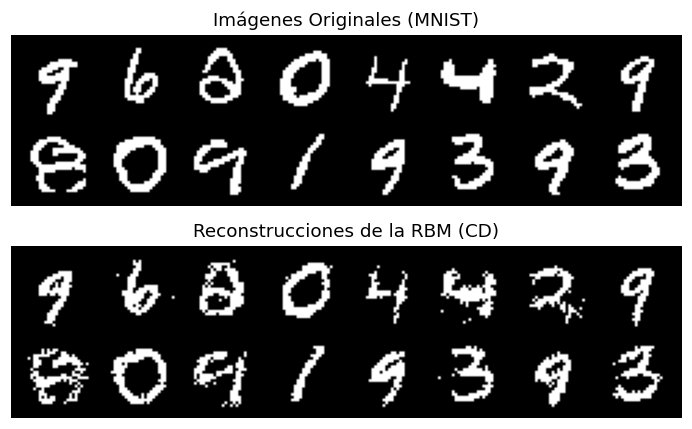

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

# ==========================================
# 1. Definición de la RBM (Bernoulli-Bernoulli)
# ==========================================
class RBM(nn.Module):
    def __init__(self, n_vis=784, n_hid=256):
        super(RBM, self).__init__()
        # Pesos y sesgos (inicializados según buenas prácticas)
        self.W = nn.Parameter(torch.randn(n_hid, n_vis) * 0.01)
        self.v_bias = nn.Parameter(torch.zeros(n_vis))
        self.h_bias = nn.Parameter(torch.zeros(n_hid))

    def sample_h(self, v):
        """P(h=1|v) = sigmoid(v @ W^T + h_bias)"""
        prob_h = torch.sigmoid(torch.matmul(v, self.W.t()) + self.h_bias)
        # Muestreo bernoulliano
        sample_h = torch.bernoulli(prob_h)
        return prob_h, sample_h

    def sample_v(self, h):
        """P(v=1|h) = sigmoid(h @ W + v_bias)"""
        prob_v = torch.sigmoid(torch.matmul(h, self.W) + self.v_bias)
        sample_v = torch.bernoulli(prob_v)
        return prob_v, sample_v

    def contrastive_divergence(self, v0, k=1):
        """Paso de CD-k para calcular los gradientes"""
        # Fase Positiva (Datos)
        prob_h0, sample_h0 = self.sample_h(v0)

        # Cadena MCMC truncada (k pasos de muestreo en bloque)
        vk = v0
        hk = sample_h0
        for _ in range(k):
            prob_vk, vk = self.sample_v(hk)
            prob_hk, hk = self.sample_h(vk)

        # Acumulación de correlaciones para CD-1
        # Se usan las probabilidades continuas en la fase negativa para reducir varianza
        pos_associations = torch.matmul(v0.t(), prob_h0)
        neg_associations = torch.matmul(vk.t(), prob_hk)

        # Retorna la reconstrucción y las correlaciones para la actualización
        return vk, pos_associations, neg_associations

    def free_energy(self, v):
        """Energía libre F(v) para monitorear el aprendizaje"""
        vbias_term = torch.matmul(v, self.v_bias)
        wx_b = torch.matmul(v, self.W.t()) + self.h_bias
        hidden_term = torch.sum(torch.log(1 + torch.exp(wx_b)), dim=1)
        return -vbias_term - hidden_term


# ==========================================
# 2. Carga y Preparación de MNIST
# ==========================================
batch_size = 64
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: (x > 0.5).float().view(-1))  # Binarización explícita
])

train_dataset = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# Detectar GPU (CUDA) o CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Ejecutando en: {device}")

# ==========================================
# 3. Entrenamiento con CD-1
# ==========================================
n_vis = 28 * 28  # 784 neuronas visibles
n_hid = 256     # 256 neuronas ocultas
epochs = 10
lr = 0.05

rbm = RBM(n_vis=n_vis, n_hid=n_hid).to(device)

for epoch in range(1, epochs + 1):
    total_loss = 0.0
    for batch_idx, (data, _) in enumerate(train_loader):
        v0 = data.to(device)

        # Obtener correlaciones mediante CD-1
        vk, pos_assoc, neg_assoc = rbm.contrastive_divergence(v0, k=1)

        # Actualización manual de parámetros (Ascenso de gradiente)
        batch_num = v0.size(0)
        with torch.no_grad():
            rbm.W += lr * ((pos_assoc - neg_assoc).t() / batch_num)
            rbm.v_bias += lr * torch.mean(v0 - vk, dim=0)
            rbm.h_bias += lr * torch.mean(rbm.sample_h(v0)[0] - rbm.sample_h(vk)[0], dim=0)

        # Pérdida de reconstrucción (Error Cuadrático Medio)
        loss = torch.mean((v0 - vk) ** 2)
        total_loss += loss.item()

    mean_loss = total_loss / len(train_loader)
    print(f"Época [{epoch}/{epochs}] - Error de Reconstrucción (MSE): {mean_loss:.4f}")

# ==========================================
# 4. Visualización de Resultados
# ==========================================
rbm.eval()
with torch.no_grad():
    # Tomar un lote de prueba
    sample_data = next(iter(train_loader))[0][:16].to(device)
    # Reconstruir mediante la capa oculta
    _, sample_h = rbm.sample_h(sample_data)
    _, reconstruction = rbm.sample_v(sample_h)

    # Reorganizar imágenes 28x28
    original_imgs = sample_data.view(-1, 1, 28, 28).cpu()
    reconstructed_imgs = reconstruction.view(-1, 1, 28, 28).cpu()

    # Graficar
    fig, axes = plt.subplots(2, 1, figsize=(8, 4))
    axes[0].imshow(make_grid(original_imgs, nrow=8).permute(1, 2, 0))
    axes[0].set_title("Imágenes Originales (MNIST)")
    axes[0].axis('off')

    axes[1].imshow(make_grid(reconstructed_imgs, nrow=8).permute(1, 2, 0))
    axes[1].set_title("Reconstrucciones de la RBM (CD)")
    axes[1].axis('off')

    plt.tight_layout()
    plt.savefig("rbm_mnist_resultados.png")
    plt.show()

**Qué se observa.** Las reconstrucciones $v\to h\to v'$ conservan la forma de los dígitos; el error cuadrático medio por época baja de 0.107 a 0.039.

Ejecutando en: cuda
Época [1/15] | MSE: 0.1076 | F(v) Train: -222.86 | F(v) Test: -263.77 | ||W||: 45.47
Época [2/15] | MSE: 0.0726 | F(v) Train: -296.56 | F(v) Test: -318.29 | ||W||: 59.88
Época [3/15] | MSE: 0.0626 | F(v) Train: -343.95 | F(v) Test: -366.34 | ||W||: 69.62
Época [4/15] | MSE: 0.0569 | F(v) Train: -383.08 | F(v) Test: -396.20 | ||W||: 77.05
Época [5/15] | MSE: 0.0529 | F(v) Train: -417.21 | F(v) Test: -430.71 | ||W||: 83.14
Época [6/15] | MSE: 0.0500 | F(v) Train: -448.22 | F(v) Test: -462.48 | ||W||: 88.25
Época [7/15] | MSE: 0.0477 | F(v) Train: -475.90 | F(v) Test: -489.38 | ||W||: 92.71
Época [8/15] | MSE: 0.0458 | F(v) Train: -501.05 | F(v) Test: -511.38 | ||W||: 96.61
Época [9/15] | MSE: 0.0443 | F(v) Train: -523.69 | F(v) Test: -531.51 | ||W||: 100.19
Época [10/15] | MSE: 0.0429 | F(v) Train: -544.19 | F(v) Test: -553.26 | ||W||: 103.40
Época [11/15] | MSE: 0.0418 | F(v) Train: -562.41 | F(v) Test: -570.48 | ||W||: 106.36
Época [12/15] | MSE: 0.0408 | F(v) Train

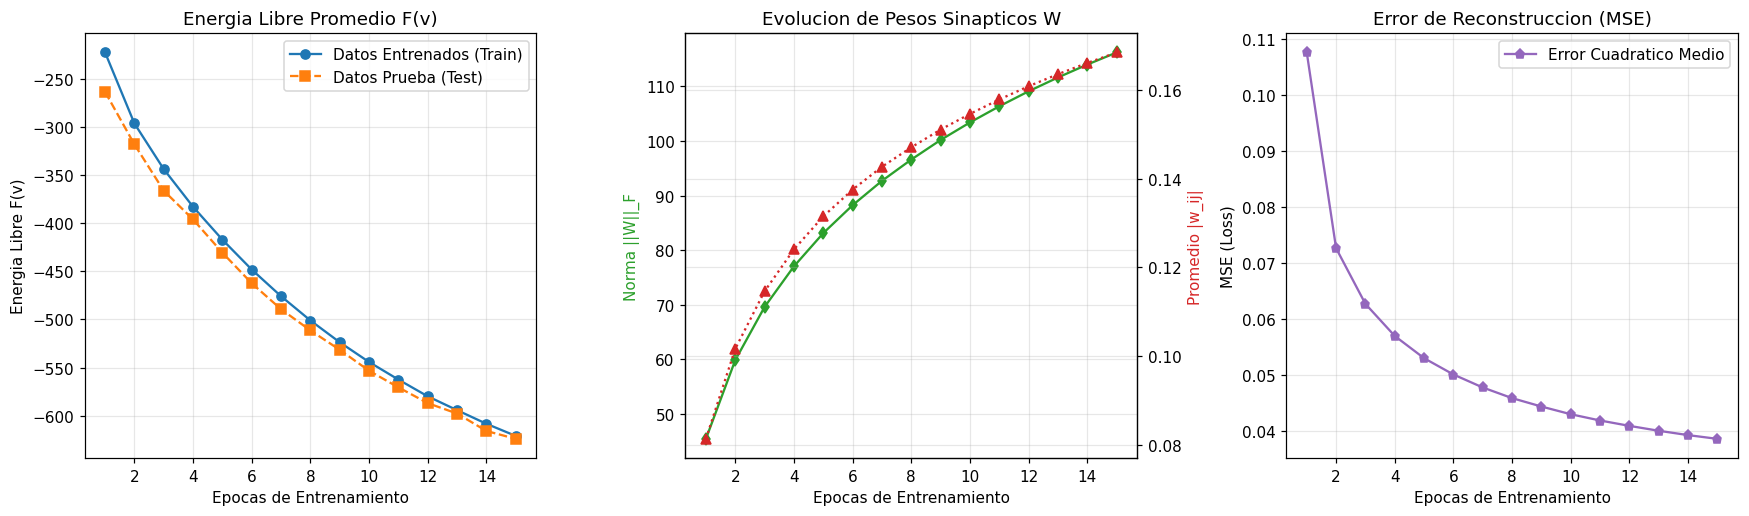

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. Definición de la RBM (Bernoulli-Bernoulli)
# ==========================================
class RBM(nn.Module):
    def __init__(self, n_vis=784, n_hid=256):
        super(RBM, self).__init__()
        self.W = nn.Parameter(torch.randn(n_hid, n_vis) * 0.01)
        self.v_bias = nn.Parameter(torch.zeros(n_vis))
        self.h_bias = nn.Parameter(torch.zeros(n_hid))

    def sample_h(self, v):
        prob_h = torch.sigmoid(torch.matmul(v, self.W.t()) + self.h_bias)
        sample_h = torch.bernoulli(prob_h)
        return prob_h, sample_h

    def sample_v(self, h):
        prob_v = torch.sigmoid(torch.matmul(h, self.W) + self.v_bias)
        sample_v = torch.bernoulli(prob_v)
        return prob_v, sample_v

    def contrastive_divergence(self, v0, k=1):
        prob_h0, sample_h0 = self.sample_h(v0)
        vk = v0
        hk = sample_h0
        for _ in range(k):
            prob_vk, vk = self.sample_v(hk)
            prob_hk, hk = self.sample_h(vk)

        pos_associations = torch.matmul(v0.t(), prob_h0)
        neg_associations = torch.matmul(vk.t(), prob_hk)
        return vk, pos_associations, neg_associations

    def free_energy(self, v):
        """Calcula la Energía Libre F(v) para un lote de imágenes"""
        vbias_term = torch.matmul(v, self.v_bias)
        wx_b = torch.matmul(v, self.W.t()) + self.h_bias
        # Suma suave usando log-sum-exp para estabilidad numérica
        hidden_term = torch.sum(torch.log(1 + torch.exp(wx_b)), dim=1)
        return -vbias_term - hidden_term


# ==========================================
# 2. Carga de Datos (MNIST Train y Test)
# ==========================================
batch_size = 64
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: (x > 0.5).float().view(-1))
])

train_dataset = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
test_dataset = datasets.MNIST(root='./data', train=False, transform=transform, download=True)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Ejecutando en: {device}")

# ==========================================
# 3. Entrenamiento registrando Métricas Físicas
# ==========================================
n_vis = 28 * 28
n_hid = 256
epochs = 15
lr = 0.05

rbm = RBM(n_vis=n_vis, n_hid=n_hid).to(device)

# Listas para almacenar métricas por época
history_free_energy_train = []
history_free_energy_test = []
history_w_norm = []
history_w_mean_abs = []
history_mse = []

for epoch in range(1, epochs + 1):
    total_loss = 0.0
    total_free_energy_train = 0.0

    for batch_idx, (data, _) in enumerate(train_loader):
        v0 = data.to(device)
        batch_num = v0.size(0)

        # 1. Paso de CD-1
        vk, pos_assoc, neg_assoc = rbm.contrastive_divergence(v0, k=1)

        # 2. Actualización de parámetros
        with torch.no_grad():
            rbm.W += lr * ((pos_assoc - neg_assoc).t() / batch_num)
            rbm.v_bias += lr * torch.mean(v0 - vk, dim=0)
            rbm.h_bias += lr * torch.mean(rbm.sample_h(v0)[0] - rbm.sample_h(vk)[0], dim=0)

        # 3. Métricas
        loss = torch.mean((v0 - vk) ** 2)
        total_loss += loss.item()

        with torch.no_grad():
            fe = torch.mean(rbm.free_energy(v0))
            total_free_energy_train += fe.item()

    # Evaluar Energía Libre en el conjunto de prueba (Test)
    total_free_energy_test = 0.0
    with torch.no_grad():
        for test_data, _ in test_loader:
            v_test = test_data.to(device)
            fe_test = torch.mean(rbm.free_energy(v_test))
            total_free_energy_test += fe_test.item()

    # Promedios de la época
    mean_mse = total_loss / len(train_loader)
    mean_fe_train = total_free_energy_train / len(train_loader)
    mean_fe_test = total_free_energy_test / len(test_loader)

    # Métricas de la matriz de pesos W
    with torch.no_grad():
        w_norm = torch.norm(rbm.W, p='fro').item()
        w_mean_abs = torch.mean(torch.abs(rbm.W)).item()

    # Guardar en el historial
    history_mse.append(mean_mse)
    history_free_energy_train.append(mean_fe_train)
    history_free_energy_test.append(mean_fe_test)
    history_w_norm.append(w_norm)
    history_w_mean_abs.append(w_mean_abs)

    print(f"Época [{epoch}/{epochs}] | MSE: {mean_mse:.4f} | F(v) Train: {mean_fe_train:.2f} | F(v) Test: {mean_fe_test:.2f} | ||W||: {w_norm:.2f}")

# ==========================================
# 4. Generación del Panel de Gráficas
# ==========================================
steps = np.arange(1, epochs + 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel A: Energía Libre F(v)
axes[0].plot(steps, history_free_energy_train, 'o-', color='#1f77b4', label='Datos Entrenados (Train)')
axes[0].plot(steps, history_free_energy_test, 's--', color='#ff7f0e', label='Datos Prueba (Test)')
axes[0].set_title('Energia Libre Promedio F(v)')
axes[0].set_xlabel('Epocas de Entrenamiento')
axes[0].set_ylabel('Energia Libre F(v)')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Panel B: Evolución de Pesos W
axes[1].plot(steps, history_w_norm, 'd-', color='#2ca02c', label='Norma ||W||_F')
axes[1].set_title('Evolucion de Pesos Sinapticos W')
axes[1].set_xlabel('Epocas de Entrenamiento')
axes[1].set_ylabel('Norma ||W||_F', color='#2ca02c')
axes[1].grid(True, alpha=0.3)

ax2_twin = axes[1].twinx()
ax2_twin.plot(steps, history_w_mean_abs, '^:', color='#d62728', label='Promedio |w_ij|')
ax2_twin.set_ylabel('Promedio |w_ij|', color='#d62728')

# Panel C: Error de Reconstrucción (MSE)
axes[2].plot(steps, history_mse, 'p-', color='#9467bd', label='Error Cuadratico Medio')
axes[2].set_title('Error de Reconstruccion (MSE)')
axes[2].set_xlabel('Epocas de Entrenamiento')
axes[2].set_ylabel('MSE (Loss)')
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.savefig('rbm_mnist_curvas_entrenamiento.png', dpi=300)
plt.show()


**Qué se observa.** La energía libre promedio baja de $-222.8$ a $-608.3$ en entrenamiento y de $-270.7$ a $-610.8$ en prueba (sin sobreajuste: ambas curvas se juntan), $\|W\|_F$ crece de 45.5 a 115.9 y el MSE llega a 0.0388.

**Magnitud del gradiente de CD-1.** Esta celda continúa el entrenamiento del modelo de la celda anterior, por lo que la figura corresponde a las épocas 16–30 de ese modelo.

In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np

history_delta_w_norm = []
history_delta_w_mean = []

for epoch in range(1, epochs + 1):
    epoch_delta_w_norm = 0.0
    epoch_delta_w_mean = 0.0

    for batch_idx, (data, _) in enumerate(train_loader):
        v0 = data.to(device)
        batch_num = v0.size(0)

        # 1. Obtener correlaciones CD-1
        vk, pos_assoc, neg_assoc = rbm.contrastive_divergence(v0, k=1)

        # 2. Resta de pesos (Gradiente de CD-1)
        delta_W = lr * ((pos_assoc - neg_assoc).t() / batch_num)

        # 3. Aplicar actualización
        with torch.no_grad():
            rbm.W += delta_W
            rbm.v_bias += lr * torch.mean(v0 - vk, dim=0)
            rbm.h_bias += lr * torch.mean(rbm.sample_h(v0)[0] - rbm.sample_h(vk)[0], dim=0)

        # Acumular magnitudes del gradiente
        epoch_delta_w_norm += torch.norm(delta_W, p='fro').item()
        epoch_delta_w_mean += torch.mean(torch.abs(delta_W)).item()

    # Promedio por época
    history_delta_w_norm.append(epoch_delta_w_norm / len(train_loader))
    history_delta_w_mean.append(epoch_delta_w_mean / len(train_loader))

<>:20: SyntaxWarning: invalid escape sequence '\D'
<>:20: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_523/1784905628.py:20: SyntaxWarning: invalid escape sequence '\D'
  plt.title('Evolución de la Resta de Pesos (Gradiente $\Delta W$)')


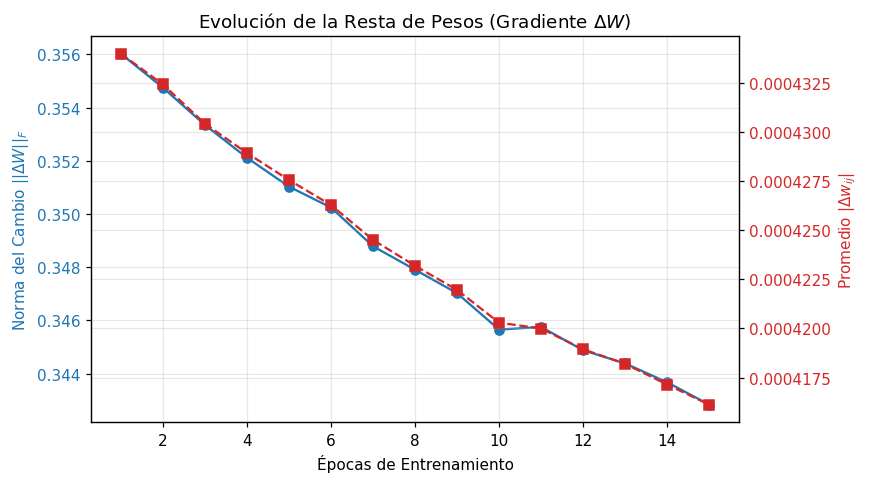

In [ ]:
def plot_delta_w(history_norm, history_mean):
    epochs = len(history_norm)
    steps = np.arange(1, epochs + 1)

    fig, ax1 = plt.subplots(figsize=(8, 4.5))

    color1 = '#1f77b4'
    ax1.plot(steps, history_norm, 'o-', color=color1, label=r'Norma $||\Delta W||_F$')
    ax1.set_xlabel('Épocas de Entrenamiento')
    ax1.set_ylabel(r'Norma del Cambio $||\Delta W||_F$', color=color1)
    ax1.tick_params(axis='y', labelcolor=color1)
    ax1.grid(True, alpha=0.3)

    ax2 = ax1.twinx()
    color2 = '#d62728'
    ax2.plot(steps, history_mean, 's--', color=color2, label=r'Promedio $|\Delta w_{ij}|$')
    ax2.set_ylabel(r'Promedio $|\Delta w_{ij}|$', color=color2)
    ax2.tick_params(axis='y', labelcolor=color2)

    plt.title('Evolución de la Resta de Pesos (Gradiente $\Delta W$)')
    fig.tight_layout()
    plt.savefig('rbm_delta_w.png', dpi=300)
    plt.show()

# Graficar
plot_delta_w(history_delta_w_norm, history_delta_w_mean)

## 5. RBM con PCD, $k=1$ (784 × 512, 25 épocas, $\eta=0.01$)

In [ ]:
import os
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torchvision.utils import save_image, make_grid
import numpy as np

# ==========================================
# 1. ARQUITECTURA RBM CON PCD (Persistent CD)
# ==========================================
class PersistentRBM(nn.Module):
    def __init__(self, n_vis=784, n_hid=512):
        super(PersistentRBM, self).__init__()
        # MEJORA 1: Capacidad ampliada a N_h = 512 neuronas ocultas
        self.W = nn.Parameter(torch.randn(n_hid, n_vis) * 0.01)
        self.v_bias = nn.Parameter(torch.zeros(n_vis))
        self.h_bias = nn.Parameter(torch.zeros(n_hid))

    def sample_h(self, v):
        prob_h = torch.sigmoid(torch.matmul(v, self.W.t()) + self.h_bias)
        sample_h = torch.bernoulli(prob_h)
        return prob_h, sample_h

    def sample_v(self, h):
        prob_v = torch.sigmoid(torch.matmul(h, self.W) + self.v_bias)
        sample_v = torch.bernoulli(prob_v)
        return prob_v, sample_v

    def pcd_step(self, v0, persistent_v, k=1):
        """
        MEJORA 4: Persistent Contrastive Divergence (PCD-k)
        Mantiene las cadenas MCMC activas entre épocas en lugar de reiniciarlas en v0.
        """
        # Fase Positiva (Datos exactos)
        prob_h0, _ = self.sample_h(v0)

        # Fase Negativa (Evolución de la cadena persistente)
        vk = persistent_v
        for _ in range(k):
            prob_hk, hk = self.sample_h(vk)
            prob_vk, vk = self.sample_v(hk)

        # Correlaciones para la actualización del gradiente
        pos_associations = torch.matmul(v0.t(), prob_h0)
        neg_associations = torch.matmul(vk.t(), prob_hk)

        # Retornamos la nueva cadena persistente desenganchada del grafo de autodiff
        return vk.detach(), pos_associations, neg_associations

    def free_energy(self, v):
        vbias_term = torch.matmul(v, self.v_bias)
        wx_b = torch.matmul(v, self.W.t()) + self.h_bias
        hidden_term = torch.sum(torch.log(1 + torch.exp(wx_b)), dim=1)
        return -vbias_term - hidden_term

    def generate_samples(self, num_samples=64, steps=100, device='cuda'):
        """
        MEJORA 2: Generación Autónoma desde Ruido Térmico (MCMC de k=100 pasos)
        """
        self.eval()
        with torch.no_grad():
            # Iniciar desde ruido uniforme aleatorio {0, 1}
            v_sample = torch.bernoulli(torch.full((num_samples, 784), 0.5)).to(device)
            for _ in range(steps):
                _, h_sample = self.sample_h(v_sample)
                prob_v, v_sample = self.sample_v(h_sample)
            return prob_v.view(-1, 1, 28, 28)


# ==========================================
# 2. CARGA DE DATOS Y DIRECTORIOS
# ==========================================
os.makedirs("checkpoints", exist_ok=True)
os.makedirs("resultados_generados", exist_ok=True)

batch_size = 64
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: (x > 0.5).float().view(-1))
])

train_dataset = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
test_dataset = datasets.MNIST(root='./data', train=False, transform=transform, download=True)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"=== Ejecutando RBM-PCD en dispostivo: {device} ===")

# ==========================================
# 3. HIPERPARÁMETROS Y ENTRENAMIENTO
# ==========================================
n_vis = 784
n_hid = 512       # Mayor capacidad latente
epochs = 25       # Corrida extendida en clúster
lr = 0.01         # Tasa de aprendizaje ajustada para PCD
k_pcd = 1         # Pasos PCD por minibatch

rbm = PersistentRBM(n_vis=n_vis, n_hid=n_hid).to(device)

# Inicializar estado de las cadenas persistentes (MCMC persisten durante todo el entrenamiento)
persistent_v = torch.bernoulli(torch.full((batch_size, n_vis), 0.5)).to(device)

# Historial para guardado en disco
history = {
    'mse': [],
    'fe_train': [],
    'fe_test': [],
    'w_norm': [],
    'delta_w_norm': []
}

for epoch in range(1, epochs + 1):
    total_loss = 0.0
    total_fe_train = 0.0
    epoch_delta_w = 0.0

    rbm.train()
    for batch_idx, (data, _) in enumerate(train_loader):
        v0 = data.to(device)

        # Paso PCD
        persistent_v, pos_assoc, neg_assoc = rbm.pcd_step(v0, persistent_v, k=k_pcd)

        # Gradientes y actualización
        delta_W = lr * ((pos_assoc - neg_assoc).t() / batch_size)
        with torch.no_grad():
            rbm.W += delta_W
            rbm.v_bias += lr * torch.mean(v0 - persistent_v, dim=0)
            rbm.h_bias += lr * torch.mean(rbm.sample_h(v0)[0] - rbm.sample_h(persistent_v)[0], dim=0)

        # Métricas rápidas
        loss = torch.mean((v0 - persistent_v) ** 2)
        total_loss += loss.item()
        epoch_delta_w += torch.norm(delta_W, p='fro').item()

        with torch.no_grad():
            total_fe_train += torch.mean(rbm.free_energy(v0)).item()

    # Evaluación en Test Set
    total_fe_test = 0.0
    with torch.no_grad():
        for test_data, _ in test_loader:
            v_test = test_data.to(device)
            total_fe_test += torch.mean(rbm.free_energy(v_test)).item()

    # Promediar métricas
    mean_mse = total_loss / len(train_loader)
    mean_fe_train = total_fe_train / len(train_loader)
    mean_fe_test = total_fe_test / len(test_loader)
    mean_delta_w = epoch_delta_w / len(train_loader)
    w_norm = torch.norm(rbm.W, p='fro').item()

    history['mse'].append(mean_mse)
    history['fe_train'].append(mean_fe_train)
    history['fe_test'].append(mean_fe_test)
    history['w_norm'].append(w_norm)
    history['delta_w_norm'].append(mean_delta_w)

    print(f"Época [{epoch}/{epochs:02d}] | MSE: {mean_mse:.4f} | F(v) Train: {mean_fe_train:.2f} | F(v) Test: {mean_fe_test:.2f} | ||dW||: {mean_delta_w:.4f}")

    # ==========================================
    # MEJORA 3: CHECKPOINTS Y MUESTREO SINTÉTICO
    # ==========================================
    if epoch % 5 == 0 or epoch == epochs:
        # 1. Guardar modelo y métricas en disco
        torch.save(rbm.state_dict(), f"checkpoints/rbm_pcd_epoch_{epoch}.pt")
        np.savez("checkpoints/metricas_pcd.npz", **history)

        # 2. Generar imágenes sintéticas puras a partir de ruido (100 pasos de Gibbs)
        samples = rbm.generate_samples(num_samples=64, steps=100, device=device)
        save_image(samples, f"resultados_generados/muestras_sinteticas_epoch_{epoch}.png", nrow=8)
        print(f"   [+] Checkpoint guardado y muestras generadas para época {epoch}")

print("\n Entrenamientos y generaciones completadas exitosamente.")

=== Ejecutando RBM-PCD en dispostivo: cuda ===
Época [1/25] | MSE: 0.1869 | F(v) Train: -344.17 | F(v) Test: -375.33 | ||dW||: 0.1835
Época [2/25] | MSE: 0.1821 | F(v) Train: -407.10 | F(v) Test: -430.02 | ||dW||: 0.1866
Época [3/25] | MSE: 0.1750 | F(v) Train: -433.04 | F(v) Test: -430.83 | ||dW||: 0.1844
Época [4/25] | MSE: 0.1724 | F(v) Train: -435.39 | F(v) Test: -440.54 | ||dW||: 0.1782
Época [5/25] | MSE: 0.1724 | F(v) Train: -448.07 | F(v) Test: -445.33 | ||dW||: 0.1749
   [+] Checkpoint guardado y muestras generadas para época 5
Época [6/25] | MSE: 0.1725 | F(v) Train: -461.55 | F(v) Test: -464.96 | ||dW||: 0.1726
Época [7/25] | MSE: 0.1724 | F(v) Train: -475.20 | F(v) Test: -478.22 | ||dW||: 0.1726
Época [8/25] | MSE: 0.1724 | F(v) Train: -487.53 | F(v) Test: -490.89 | ||dW||: 0.1702
Época [9/25] | MSE: 0.1724 | F(v) Train: -499.64 | F(v) Test: -504.29 | ||dW||: 0.1710
Época [10/25] | MSE: 0.1721 | F(v) Train: -511.83 | F(v) Test: -519.30 | ||dW||: 0.1706
   [+] Checkpoint gua

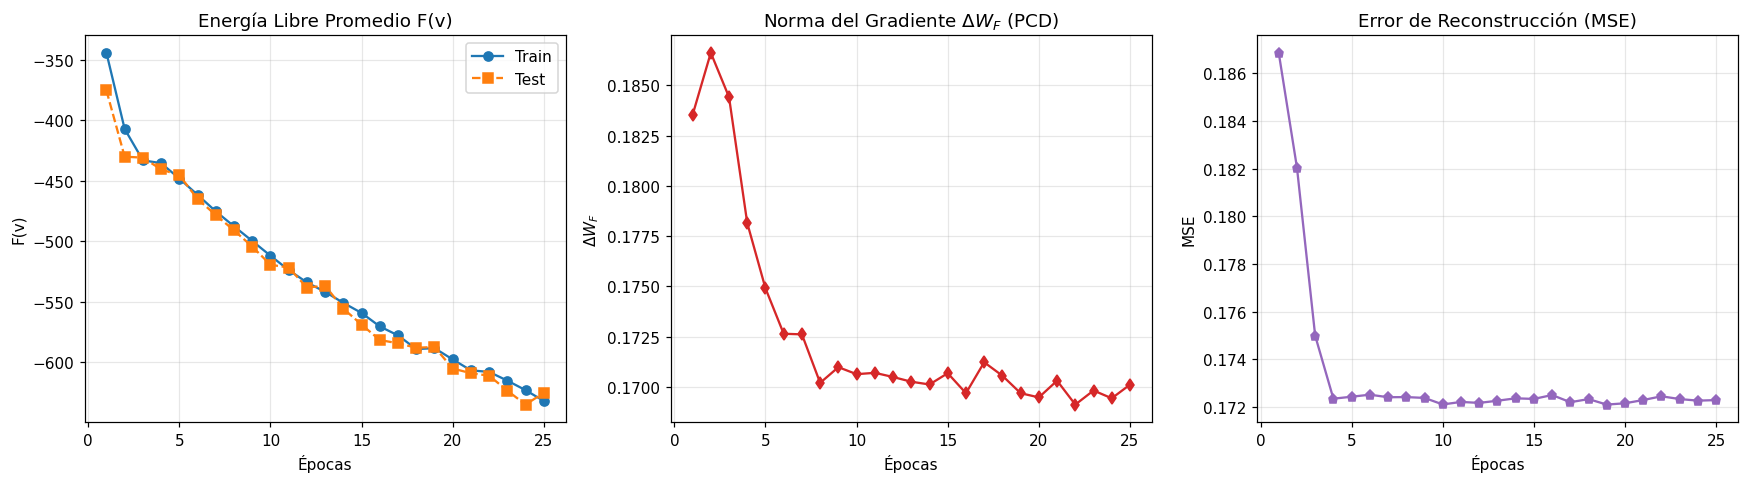

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load('checkpoints/metricas_pcd.npz')

epochs = len(data['mse'])
steps = np.arange(1, epochs + 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))


axes[0].plot(steps, data['fe_train'], 'o-', color='#1f77b4', label='Train')
axes[0].plot(steps, data['fe_test'], 's--', color='#ff7f0e', label='Test')
axes[0].set_title('Energía Libre Promedio F(v)')
axes[0].set_xlabel('Épocas')
axes[0].set_ylabel('F(v)')
axes[0].grid(True, alpha=0.3)
axes[0].legend()


axes[1].plot(steps, data['delta_w_norm'], 'd-', color='#d62728')
axes[1].set_title(r'Norma del Gradiente $\Delta W_F$ (PCD)')
axes[1].set_xlabel('Épocas')
axes[1].set_ylabel(r'$\Delta W_F$')
axes[1].grid(True, alpha=0.3)


axes[2].plot(steps, data['mse'], 'p-', color='#9467bd')
axes[2].set_title('Error de Reconstrucción (MSE)')
axes[2].set_xlabel('Épocas')
axes[2].set_ylabel('MSE')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('panel_resultados_pcd_final.png', dpi=300)
plt.show()






**Qué se observa.** $F(v)$ baja de $-343.5$ a $-605.9$ (entrenamiento) y de $-381.6$ a $-601.9$ (prueba). El "MSE" de esta celda compara $v_0$ con la cadena persistente (dos estados sin relación), no es un error de reconstrucción: casi no cambia (0.187→0.172).

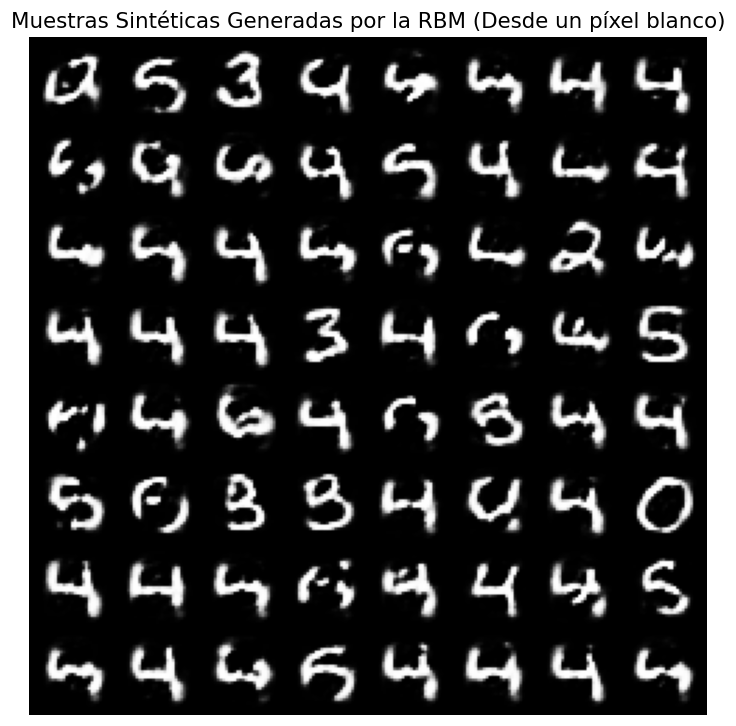

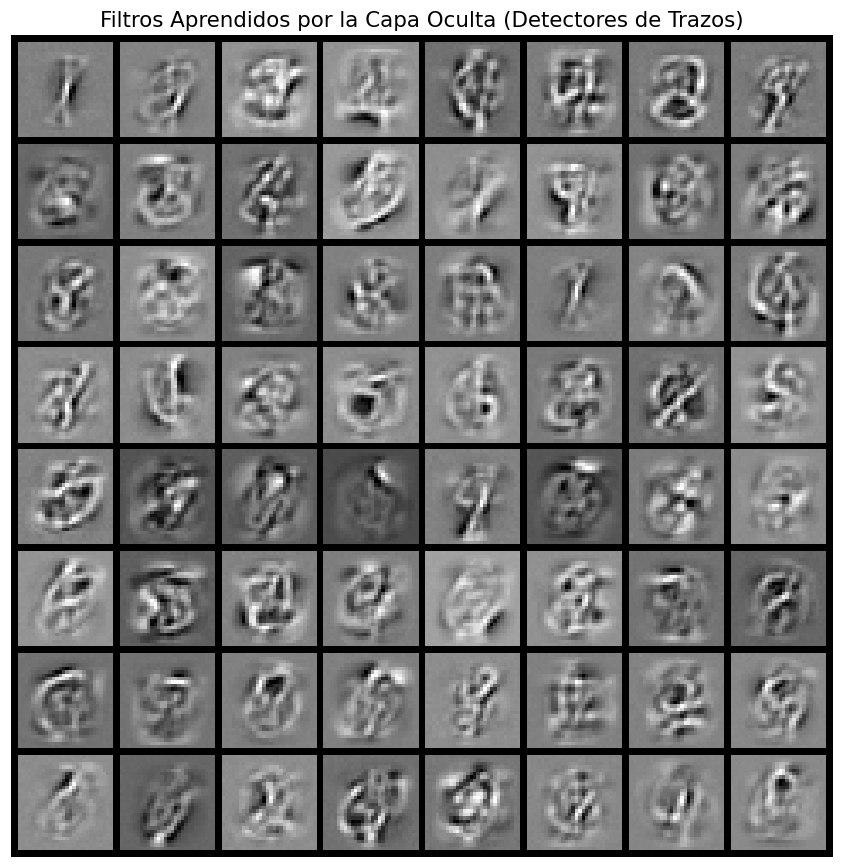

In [ ]:
import torch
import torchvision.utils as vutils
import matplotlib.pyplot as plt
from PIL import Image

# ==========================================
# RESULTADO 1: Muestras Sintéticas Generadas
# ==========================================
try:
    img_sinteticas = Image.open('resultados_generados/muestras_sinteticas_epoch_25.png')
    plt.figure(figsize=(8, 8))
    plt.imshow(img_sinteticas)
    plt.title("Muestras Sintéticas Generadas por la RBM (Desde un píxel blanco)", fontsize=14)
    plt.axis('off')
    plt.show()
except FileNotFoundError:
    print("No se encontró el archivo de muestras sintéticas. Verifica la carpeta 'resultados_generados/'.")

# ==========================================
# RESULTADO 2: Visualización de Filtros de Pesos W
# ==========================================
# Cargamos el modelo entrenado
rbm_state = torch.load('checkpoints/rbm_pcd_epoch_25.pt', map_location='cpu')
W = rbm_state['W']  # Dimensión (512, 784)

# Tomamos las primeras 64 neuronas ocultas y las organizamos como imágenes 28x28
num_filters = 64
weights_subset = W[:num_filters].view(num_filters, 1, 28, 28)

# Crear grilla de filtros
grid_w = vutils.make_grid(weights_subset, nrow=8, normalize=True, scale_each=True)

plt.figure(figsize=(8, 8))
plt.imshow(grid_w.permute(1, 2, 0).numpy(), cmap='inferno')
plt.title("Filtros Aprendidos por la Capa Oculta (Detectores de Trazos)", fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.savefig("filtros_pesos_rbm.png", dpi=300)
plt.show()

**Qué se observa.** Las muestras generadas desde ruido tienen forma de dígito, pero se concentran en pocas clases (sobre todo "4" y "9"): señal de que la cadena visita solo parte de los pozos de energía (colapso de modos / metaestabilidad). Los filtros son detectores de trazos.

## 6. DBN (784–512–512) con PCD-5: entrenamiento, evaluación y física estadística
Configuración: $k=5$ pasos de Gibbs por actualización, tasa de aprendizaje decreciente de 0.01 a 0.001, 30 épocas por RBM, sesgos visibles inicializados con la intensidad media de cada píxel, 250 pasos de Gibbs para generar.
### 6.0 Definiciones (modelo, entrenamiento, análisis)

In [ ]:
import os
import json
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torchvision.utils import save_image
import numpy as np
import matplotlib.pyplot as plt

# =====================================================================
#  ÍNDICE (organizado por los objetivos de la tesis)
#   1. Modelo: RBM (Hamiltoniano, energía libre, muestreo a temperatura β) y DBN   [Obj. 1]
#   2. Entrenamiento PCD: energía, pesos y sesgos en el tiempo                      [Obj. 4b]
#   3. Monte Carlo a temperatura definida: relajación, τ, termodinámica vs. β       [Obj. 2]
#   4. Distribución real vs. generada: intensidad, Parzen, clasificador-juez        [Obj. 3]
#   5. Temperatura y recuperación de patrones ruidosos; descenso de la energía      [Obj. 4a]
#   6. Ejecución (main) y resumen de métricas
#
#  Figuras nuevas: resultados_dbn/obj2_*, obj3_*, obj4_*  (+ resumen_metricas.json)
#  Figuras originales (sin cambios de ruta): comparacion_distribucion.png, muestras_sinteticas_dbn.png
# =====================================================================

def beta_label(b):
    """Etiqueta legible de la temperatura: beta muy grande equivale a T -> 0."""
    return 'T→0' if b >= 50 else f'{b:g}'


def _np(x):
    """Acepta tensores de torch (en CPU) o arreglos de numpy."""
    return x.numpy() if hasattr(x, 'numpy') else np.asarray(x)

In [ ]:
# ==========================================
# 1. RBM BASE CON PCD (Persistent CD)           [Obj. 1]
# ==========================================
class PersistentRBM(nn.Module):
    """
    Energía de la RBM (unidades binarias {0,1}, W de tamaño n_hid x n_vis):
        E(v,h) = - a.v - b.h - h^T W v           (a = v_bias, b = h_bias)
    Distribución de Boltzmann a temperatura inversa beta:  P(v,h) ∝ exp(-beta E(v,h)).
    """
    def __init__(self, n_vis=784, n_hid=512):
        super(PersistentRBM, self).__init__()
        self.W = nn.Parameter(torch.randn(n_hid, n_vis) * 0.01)
        self.v_bias = nn.Parameter(torch.zeros(n_vis))
        self.h_bias = nn.Parameter(torch.zeros(n_hid))

    def init_visible_bias(self, mean_v, eps=1e-3):
        """v_bias_i = ln( p_i / (1 - p_i) ), con p_i = <v_i> sobre los datos.
        Con W = 0 el modelo ya reproduce la intensidad media de cada unidad visible,
        así que el entrenamiento solo tiene que aprender las correlaciones."""
        p = mean_v.to(self.v_bias.device).clamp(eps, 1.0 - eps)
        with torch.no_grad():
            self.v_bias.copy_(torch.log(p / (1.0 - p)))

    def energy(self, v, h):
        """E(v,h) por muestra (vector de tamaño batch)."""
        return -(v @ self.v_bias) - (h @ self.h_bias) - ((v @ self.W.t()) * h).sum(dim=1)

    def free_energy(self, v):
        """F(v) = -ln sum_h exp(-E(v,h)) = -a.v - sum_j ln(1 + exp(b_j + (W v)_j))   (exacta)."""
        return -(v @ self.v_bias) - nn.functional.softplus(v @ self.W.t() + self.h_bias).sum(dim=1)

    def sample_h(self, v, beta=1.0):
        # beta = 1/T. Con beta=1 es exactamente el muestreo de entrenamiento.
        # beta=inf es el límite exacto T=0: cada unidad toma el estado que minimiza la energía (dinámica determinista).
        act = torch.matmul(v, self.W.t()) + self.h_bias
        if beta == float('inf'):
            prob_h = (act > 0).float()
            return prob_h, prob_h
        prob_h = torch.sigmoid(beta * act)
        sample_h = torch.bernoulli(prob_h)
        return prob_h, sample_h

    def sample_v(self, h, beta=1.0):
        act = torch.matmul(h, self.W) + self.v_bias
        if beta == float('inf'):
            prob_v = (act > 0).float()
            return prob_v, prob_v
        prob_v = torch.sigmoid(beta * act)
        sample_v = torch.bernoulli(prob_v)
        return prob_v, sample_v

    @torch.no_grad()
    def pcd_step(self, v0, persistent_v, k=5):
        prob_h0, _ = self.sample_h(v0)
        vk = persistent_v
        for _ in range(k):
            _, hk = self.sample_h(vk)
            _, vk = self.sample_v(hk)
        # P(h | v_k) con el v_k FINAL (fase negativa consistente)
        prob_hk, _ = self.sample_h(vk)
        pos_associations = torch.matmul(v0.t(), prob_h0)
        neg_associations = torch.matmul(vk.t(), prob_hk)
        return vk.detach(), pos_associations, neg_associations


class DeepBeliefNetwork(nn.Module):
    def __init__(self, n_vis=784, n_hid_1=512, n_hid_2=512):
        super(DeepBeliefNetwork, self).__init__()
        self.rbm1 = PersistentRBM(n_vis=n_vis, n_hid=n_hid_1)
        self.rbm2 = PersistentRBM(n_vis=n_hid_1, n_hid=n_hid_2)

    def generate_samples_dbn(self, num_samples=64, steps=250, device='cuda', init_h1=None, binary=False):
        """
        Muestreo top-down: Gibbs en RBM2 (h1 <-> h2) y luego P(v | h1) con RBM1.
        init_h1: estado inicial opcional de la capa h1 (p. ej. las cadenas persistentes de RBM2).
                 Si es None se parte de Bernoulli(0.5).
        binary:  False -> devuelve P(v | h1) (mapas de probabilidad).
                 True  -> devuelve una muestra Bernoulli binaria (comparable con MNIST binarizado).
        """
        self.eval()
        with torch.no_grad():
            n_h1 = self.rbm2.W.shape[1]  # capa visible de RBM2 (= capa oculta de RBM1)
            if init_h1 is None:
                h1_sample = torch.bernoulli(torch.full((num_samples, n_h1), 0.5)).to(device)
            else:
                h1_sample = init_h1[:num_samples].clone().to(device)
            for _ in range(steps):
                _, h2_sample = self.rbm2.sample_h(h1_sample)
                _, h1_sample = self.rbm2.sample_v(h2_sample)
            prob_v, sample_v = self.rbm1.sample_v(h1_sample)
            out = sample_v if binary else prob_v
            return out.view(-1, 1, 28, 28)

In [ ]:
# ==========================================
# 2. ENTRENAMIENTO PCD CON MONITOREO              [Obj. 4b]
# ==========================================
def lr_schedule(epoch, epochs, lr_max=0.01, lr_min=0.001):
    """Decaimiento lineal de la tasa de aprendizaje de lr_max a lr_min."""
    frac = (epoch - 1) / max(epochs - 1, 1)
    return lr_max + (lr_min - lr_max) * frac


def train_pcd(rbm, name, train_loader, get_data, persistent, epochs, k_pcd,
              lr_max, lr_min, batch_size, device, snap_epochs=None):
    """
    Entrena una RBM con PCD y registra:
      - Energía <E(v,h)>/N y energía libre <F(v)>/N de los datos y de la cadena persistente.
      - "Fuerza" g = ||<vh>_datos - <vh>_modelo||_F y paso ||dW||_F = lr * g (por iteración).
      - ||W||_F, ||W-W0||_F, ||a||, ||b|| y sus desplazamientos respecto a la inicialización.
      - Coherencia de las actualizaciones r = ||sum_t dW_t|| / sum_t ||dW_t||
            (1: deriva dirigida; ~1/sqrt(T): caminata aleatoria).
      - Magnetización (intensidad media) de los datos y de la cadena.
      - Instantáneas (W, a, b) en épocas elegidas, para visualizar la evolución de los parámetros.
    """
    rbm.train()
    N = rbm.W.shape[0] + rbm.W.shape[1]  # número total de unidades (visibles + ocultas)
    W0 = rbm.W.detach().clone()
    a0 = rbm.v_bias.detach().clone()
    b0 = rbm.h_bias.detach().clone()

    if snap_epochs is None:
        snap_epochs = [1, max(epochs // 5, 1), max(epochs // 2, 1), epochs]
    snap_epochs = sorted(set([0] + list(snap_epochs)))
    snaps = {}

    def take_snapshot(ep):
        snaps[ep] = {'W': rbm.W.detach().cpu().clone(),
                     'a': rbm.v_bias.detach().cpu().clone(),
                     'b': rbm.h_bias.detach().cpu().clone()}

    take_snapshot(0)

    keys = ['epoch', 'lr', 'E_data', 'E_chain', 'F_data', 'F_chain', 'm_data', 'm_chain',
            'recon_mse', 'W_norm', 'W_disp', 'a_norm', 'b_norm', 'a_disp', 'b_disp',
            'coherence', 'g_mean', 'dW_mean']
    hist = {k: [] for k in keys}
    hist['g_iter'] = []
    hist['dW_iter'] = []
    hist['W0'] = W0.cpu()
    hist['snapshots'] = snaps
    hist['n_iter_epoch'] = len(train_loader)
    hist['N'] = N

    for epoch in range(1, epochs + 1):
        lr = lr_schedule(epoch, epochs, lr_max, lr_min)
        s = {k: torch.zeros((), device=device)
             for k in ['E_data', 'E_chain', 'F_data', 'F_chain', 'm_data', 'm_chain', 'recon']}
        sum_dW = torch.zeros_like(rbm.W)
        sum_dW_norm = torch.zeros((), device=device)
        g_list, dW_list = [], []

        for data, _ in train_loader:
            v0 = get_data(data.to(device))
            persistent, pos_assoc, neg_assoc = rbm.pcd_step(v0, persistent, k=k_pcd)
            grad_W = (pos_assoc - neg_assoc).t() / batch_size   # <h v>_datos - <h v>_modelo
            delta_W = lr * grad_W

            with torch.no_grad():
                rbm.W += delta_W
                ph0, h0 = rbm.sample_h(v0)
                phk, hk = rbm.sample_h(persistent)

                s['E_data'] += rbm.energy(v0, h0).mean() / N
                s['E_chain'] += rbm.energy(persistent, hk).mean() / N
                s['F_data'] += rbm.free_energy(v0).mean() / N
                s['F_chain'] += rbm.free_energy(persistent).mean() / N
                s['m_data'] += v0.mean()
                s['m_chain'] += persistent.mean()
                s['recon'] += torch.mean((v0 - rbm.sample_v(h0)[0]) ** 2)

                rbm.v_bias += lr * torch.mean(v0 - persistent, dim=0)
                rbm.h_bias += lr * torch.mean(ph0 - phk, dim=0)

                sum_dW += delta_W
                sum_dW_norm += delta_W.norm()
                g_list.append(grad_W.norm())
                dW_list.append(delta_W.norm())

        n = len(train_loader)
        with torch.no_grad():
            coherence = (sum_dW.norm() / sum_dW_norm).item()
            W_norm = rbm.W.norm().item()
            W_disp = (rbm.W - W0).norm().item()
            a_norm = rbm.v_bias.norm().item()
            b_norm = rbm.h_bias.norm().item()
            a_disp = (rbm.v_bias - a0).norm().item()
            b_disp = (rbm.h_bias - b0).norm().item()
        g_t = torch.stack(g_list).cpu()
        dW_t = torch.stack(dW_list).cpu()
        v = {k: x.item() / n for k, x in s.items()}

        hist['g_iter'].extend(g_t.tolist())
        hist['dW_iter'].extend(dW_t.tolist())
        hist['epoch'].append(epoch)
        hist['lr'].append(lr)
        hist['E_data'].append(v['E_data'])
        hist['E_chain'].append(v['E_chain'])
        hist['F_data'].append(v['F_data'])
        hist['F_chain'].append(v['F_chain'])
        hist['m_data'].append(v['m_data'])
        hist['m_chain'].append(v['m_chain'])
        hist['recon_mse'].append(v['recon'])
        hist['W_norm'].append(W_norm)
        hist['W_disp'].append(W_disp)
        hist['a_norm'].append(a_norm)
        hist['b_norm'].append(b_norm)
        hist['a_disp'].append(a_disp)
        hist['b_disp'].append(b_disp)
        hist['coherence'].append(coherence)
        hist['g_mean'].append(g_t.mean().item())
        hist['dW_mean'].append(dW_t.mean().item())
        if epoch in snap_epochs:
            take_snapshot(epoch)

        print(f"{name} - Época [{epoch}/{epochs}] | lr: {lr:.4f} | MSE recon: {v['recon']:.4f}\n"
              f"      E/N datos: {v['E_data']:.4f} vs cadena: {v['E_chain']:.4f} | "
              f"F/N datos: {v['F_data']:.4f} vs cadena: {v['F_chain']:.4f}\n"
              f"      |dW| medio: {dW_t.mean().item():.3e} | |W|: {W_norm:.3f} | |a|: {a_norm:.2f} | |b|: {b_norm:.2f} | "
              f"coherencia: {coherence:.3f} | intensidad datos: {v['m_data']:.4f} vs cadena: {v['m_chain']:.4f}")

    return persistent, hist


def plot_training_energy(hist, name, save_path):
    """Energía en el tiempo (de entrenamiento): datos vs. modelo."""
    ep = np.array(hist['epoch'])
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    fig.suptitle(f"{name}: energía durante el entrenamiento PCD (datos vs. modelo)", fontsize=14)

    ax = axes[0]
    ax.plot(ep, hist['E_data'], label=r'datos: $v\sim$MNIST, $h\sim P(h|v)$')
    ax.plot(ep, hist['E_chain'], label='modelo: cadena persistente')
    ax.set_title(r'Energía por unidad $\langle E(v,h)\rangle / N$')

    ax = axes[1]
    ax.plot(ep, hist['F_data'], label='datos')
    ax.plot(ep, hist['F_chain'], label='modelo: cadena persistente')
    ax.set_title(r'Energía libre por unidad $\langle F(v)\rangle / N$')

    ax = axes[2]
    ax.plot(ep, hist['m_data'], label='datos')
    ax.plot(ep, hist['m_chain'], label='modelo: cadena persistente')
    ax.set_title(r'Magnetización (intensidad media) $\langle v\rangle$')

    for ax in axes:
        ax.set_xlabel('Época'); ax.legend(); ax.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.close()
    print(f"   [+] Gráfica guardada en: {save_path}")


def plot_parameter_evolution(hist, name, save_path):
    """Evolución de pesos sinápticos y sesgos de activación, y de la dinámica de descenso por gradiente."""
    ep = np.array(hist['epoch'])
    snaps = hist['snapshots']
    snap_eps = sorted(snaps.keys())
    fig, axes = plt.subplots(2, 3, figsize=(17, 9))
    fig.suptitle(f"{name}: evolución de los parámetros de entrenamiento (pesos y sesgos)", fontsize=14)

    ax = axes[0, 0]
    ax.plot(ep, hist['W_norm'], label=r'$\|W\|_F$')
    ax.plot(ep, hist['W_disp'], label=r'$\|W-W_0\|_F$ (desplazamiento)')
    ax.set_title('Pesos sinápticos'); ax.set_xlabel('Época'); ax.legend(); ax.grid(True, linestyle='--', alpha=0.5)

    ax = axes[0, 1]
    ax.plot(ep, hist['a_norm'], label=r'$\|a\|$ (sesgos visibles)')
    ax.plot(ep, hist['b_norm'], label=r'$\|b\|$ (sesgos ocultos)')
    ax.plot(ep, hist['a_disp'], '--', label=r'$\|a-a_0\|$')
    ax.plot(ep, hist['b_disp'], '--', label=r'$\|b-b_0\|$')
    ax.set_title('Sesgos de activación (campos locales)'); ax.set_xlabel('Época')
    ax.legend(fontsize=8); ax.grid(True, linestyle='--', alpha=0.5)

    ax = axes[0, 2]
    ax.plot(ep, hist['coherence'], label='coherencia observada')
    ax.axhline(1.0 / np.sqrt(hist['n_iter_epoch']), color='gray', ls='--',
               label=r'caminata aleatoria pura $1/\sqrt{T}$')
    ax.set_ylim(0, 1)
    ax.set_title('Coherencia de las actualizaciones de W (por época)')
    ax.set_ylabel(r'$\|\sum \Delta W\|\, /\, \sum \|\Delta W\|$')
    ax.set_xlabel('Época'); ax.legend(); ax.grid(True, linestyle='--', alpha=0.5)

    ax = axes[1, 0]
    g = np.array(hist['g_iter']); dW = np.array(hist['dW_iter'])
    it = np.arange(1, len(g) + 1)
    win = max(min(len(g) // 50, 200), 1)
    kern = np.ones(win) / win
    ax.semilogy(it, dW, color='C1', alpha=0.15, lw=0.5)
    ax.semilogy(it[win - 1:], np.convolve(dW, kern, mode='valid'), color='C1',
                label=r'paso $\|\Delta W\|_F = \eta\, g$')
    ax.semilogy(it[win - 1:], np.convolve(g, kern, mode='valid'), color='C0',
                label=r'fuerza $g=\|\langle vh\rangle_{datos}-\langle vh\rangle_{modelo}\|_F$')
    ax.set_title('Magnitud de la actualización por iteración (media móvil)')
    ax.set_xlabel('Iteración'); ax.legend(); ax.grid(True, which='both', linestyle='--', alpha=0.4)

    ax = axes[1, 1]
    all_w = np.concatenate([_np(snaps[e]['W']).ravel() for e in snap_eps])
    wmax = np.abs(all_w).max() + 1e-12
    bins = np.linspace(-wmax, wmax, 81)
    centers = 0.5 * (bins[1:] + bins[:-1])
    for e in snap_eps:
        h, _ = np.histogram(_np(snaps[e]['W']).ravel(), bins=bins, density=True)
        ax.semilogy(centers, np.where(h > 0, h, np.nan), label=f'época {e}')
    ax.set_title(r'Distribución de acoplamientos $P(W_{ij})$')
    ax.set_xlabel(r'$W_{ij}$'); ax.legend(fontsize=8); ax.grid(True, which='both', linestyle='--', alpha=0.4)

    ax = axes[1, 2]
    all_b = np.concatenate([_np(snaps[e]['b']).ravel() for e in snap_eps])
    bmax = np.abs(all_b).max() + 1e-12
    bins_b = np.linspace(-bmax, bmax, 41)
    for e in snap_eps:
        ax.hist(_np(snaps[e]['b']).ravel(), bins=bins_b, histtype='step', density=True, label=f'época {e}')
    ax.set_title(r'Distribución de sesgos ocultos $P(b_j)$')
    ax.set_xlabel(r'$b_j$'); ax.legend(fontsize=8); ax.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.close()
    print(f"   [+] Gráfica guardada en: {save_path}")


def plot_filters_evolution(hist, name, save_path, n_filters=8, img_shape=(28, 28)):
    """Campos receptivos (filas de W como imágenes) y mapa de sesgos visibles en distintas épocas."""
    snaps = hist['snapshots']
    snap_eps = sorted(snaps.keys())
    W_final = _np(snaps[snap_eps[-1]]['W'])
    idx = np.argsort(-np.linalg.norm(W_final, axis=1))[:n_filters]
    fig, axes = plt.subplots(len(snap_eps), n_filters + 1,
                             figsize=(1.6 * (n_filters + 1), 1.7 * len(snap_eps)), squeeze=False)
    fig.suptitle(f"{name}: evolución de los campos receptivos $W_j$ y del sesgo visible $a$", fontsize=13)
    for r, e in enumerate(snap_eps):
        Ws = _np(snaps[e]['W']); a = _np(snaps[e]['a'])
        vmax = np.abs(Ws[idx]).max() + 1e-12
        for c, j in enumerate(idx):
            ax = axes[r, c]
            ax.imshow(Ws[j].reshape(img_shape), cmap='RdBu_r', vmin=-vmax, vmax=vmax)
            ax.axis('off')
            if r == 0:
                ax.set_title(f'h{j}', fontsize=9)
        ax = axes[r, -1]
        amax = np.abs(a).max() + 1e-12
        ax.imshow(a.reshape(img_shape), cmap='RdBu_r', vmin=-amax, vmax=amax)
        ax.axis('off')
        if r == 0:
            ax.set_title('sesgo $a$', fontsize=9)
        axes[r, 0].text(-0.1, 0.5, f'época {e}', transform=axes[r, 0].transAxes,
                        rotation=90, va='center', ha='right', fontsize=10)
    plt.tight_layout()
    plt.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.close()
    print(f"   [+] Gráfica guardada en: {save_path}")

In [ ]:
# ==========================================
# 3. MONTE CARLO A TEMPERATURA DEFINIDA           [Obj. 2]
# ==========================================
@torch.no_grad()
def gibbs_series(rbm, v_init, steps, beta=1.0):
    """
    Dinámica de Gibbs (un 'sweep' = h|v y luego v|h). Devuelve la serie temporal de la
    energía por unidad E(v_t,h_t)/N y de la magnetización <v_t>, de forma (steps, n_cadenas),
    y el estado final v.
    """
    N = rbm.W.shape[0] + rbm.W.shape[1]
    v = v_init.clone()
    E_list, m_list = [], []
    for _ in range(steps):
        _, h = rbm.sample_h(v, beta)
        E_list.append(rbm.energy(v, h) / N)
        m_list.append(v.mean(dim=1))
        _, v = rbm.sample_v(h, beta)
    return torch.stack(E_list), torch.stack(m_list), v


def autocorr_numpy(x):
    """ACF normalizada (estimador insesgado, vía FFT) de x con forma (T, n_cadenas), promediada sobre cadenas."""
    x = x - x.mean(axis=0, keepdims=True)
    T = x.shape[0]
    f = np.fft.rfft(x, n=2 * T, axis=0)
    acf = np.fft.irfft(f * np.conj(f), n=2 * T, axis=0)[:T]
    acf = acf / np.arange(T, 0, -1)[:, None]
    acf = acf / acf[0:1]
    return np.nanmean(acf, axis=1)


def tau_int(acf):
    """Tiempo de autocorrelación integrado: 1/2 + suma de la ACF hasta su primer cruce por cero."""
    tau = 0.5
    for lag in range(1, len(acf)):
        if acf[lag] < 0:
            break
        tau += acf[lag]
    return tau


def participation_ratio(s):
    """Número efectivo de modos de un espectro de valores singulares: (sum s^2)^2 / sum s^4."""
    s2 = np.asarray(s) ** 2
    return (s2.sum() ** 2) / (s2 ** 2).sum()


def plot_relaxation_analysis(E_hot, E_cold, E_per, E_data, W, W0, name, save_path, burn=300):
    steps = E_per.shape[0]
    t = np.arange(1, steps + 1)
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f"{name}: relajación de Gibbs, equilibrio y espectro de acoplamientos", fontsize=14)

    # (a) E(t): relajación térmica desde tres condiciones iniciales
    ax = axes[0, 0]
    E_eq = E_per[burn:].mean()
    for E_, lab in [(E_hot, r'inicio caliente ($v\sim$Bernoulli(0.5))'),
                    (E_cold, 'inicio frío (datos MNIST)'),
                    (E_per, 'inicio en cadena persistente')]:
        mu, sd = E_.mean(axis=1), E_.std(axis=1)
        ax.plot(t, mu, label=lab)
        ax.fill_between(t, mu - sd, mu + sd, alpha=0.2)
    ax.axhline(E_eq, color='k', ls='--', lw=1, label='energía de equilibrio (cadena persistente)')
    ax.set_xscale('log')
    ax.set_title(r'Relajación térmica: $E(t)/N$ vs. pasos de Gibbs')
    ax.set_xlabel('Pasos de Gibbs (t)'); ax.set_ylabel('E / N')
    ax.legend(fontsize=8); ax.grid(True, which='both', linestyle='--', alpha=0.4)

    # (b) autocorrelación de la energía en equilibrio
    ax = axes[0, 1]
    acf = autocorr_numpy(E_per[burn:])
    tau = tau_int(acf)
    lags = np.arange(min(200, len(acf)))
    ax.plot(lags, acf[:len(lags)])
    ax.axhline(0, color='gray', lw=0.8)
    ax.set_title(rf'Autocorrelación de $E(t)$: $\tau_{{int}}\approx$ {tau:.1f} pasos')
    ax.set_xlabel('Retardo (pasos de Gibbs)'); ax.set_ylabel(r'$\rho(\mathrm{lag})$')
    ax.grid(True, linestyle='--', alpha=0.5)

    # (c) distribución de energías: datos vs. modelo
    ax = axes[1, 0]
    E_model = E_per[burn:].reshape(-1)
    ax.hist(E_data, bins=40, density=True, alpha=0.6, label=r'datos ($v\sim$MNIST, $h\sim P(h|v)$)')
    ax.hist(E_model, bins=40, density=True, alpha=0.6, label='modelo (equilibrio)')
    ax.set_title(r'Distribución de energías $P(E/N)$')
    ax.set_xlabel('E / N'); ax.set_ylabel('Densidad'); ax.legend(); ax.grid(True, linestyle='--', alpha=0.5)

    # (d) espectro de la matriz de acoplamientos
    ax = axes[1, 1]
    sv = np.linalg.svd(W, compute_uv=False)
    pr = participation_ratio(sv)
    ax.semilogy(np.arange(1, len(sv) + 1), sv, label='W final')
    pr0 = float('nan')
    if W0 is not None:
        sv0 = np.linalg.svd(W0, compute_uv=False)
        n_h, n_v = W.shape
        sigma0 = W0.std()
        ax.semilogy(np.arange(1, len(sv0) + 1), sv0, label='W inicial (aleatoria)')
        ax.axhline(sigma0 * (np.sqrt(n_v) + np.sqrt(n_h)), color='gray', ls=':',
                   label='bordes del bulk inicial (Marchenko-Pastur)')
        ax.axhline(sigma0 * abs(np.sqrt(n_v) - np.sqrt(n_h)), color='gray', ls=':')
        pr0 = participation_ratio(sv0)
    ax.set_title(f'Espectro de valores singulares de W  (modos efectivos: {pr:.1f})')
    ax.set_xlabel('Índice del modo'); ax.set_ylabel('Valor singular')
    ax.legend(fontsize=8); ax.grid(True, which='both', linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.close()
    print(f"   [+] Gráfica de relajación y espectro guardada en: {save_path}")
    return {'tau_int': float(tau), 'E_eq': float(E_eq), 'PR_final': float(pr), 'PR_inicial': float(pr0)}


def analyze_rbm_physics(rbm, name, data_ref, persistent, W0, save_path, steps=1000, burn=300):
    """
    data_ref: datos binarios de referencia (n >= n_cadenas) de la capa visible de esta RBM.
    persistent: estado de las cadenas persistentes al terminar el entrenamiento.
    W0: pesos iniciales (tensor en CPU) o None.
    """
    N = rbm.W.shape[0] + rbm.W.shape[1]
    n_ch = persistent.shape[0]
    v_hot = torch.bernoulli(torch.full_like(persistent, 0.5))
    v_cold = data_ref[:n_ch].clone()

    E_hot, _, _ = gibbs_series(rbm, v_hot, steps)
    E_cold, _, _ = gibbs_series(rbm, v_cold, steps)
    E_per, _, _ = gibbs_series(rbm, persistent, steps)

    with torch.no_grad():
        _, h_d = rbm.sample_h(data_ref)
        E_data = (rbm.energy(data_ref, h_d) / N).cpu().numpy()

    W0_np = None if W0 is None else _np(W0)
    stats = plot_relaxation_analysis(
        E_hot.cpu().numpy(), E_cold.cpu().numpy(), E_per.cpu().numpy(), E_data,
        rbm.W.detach().cpu().numpy(), W0_np, name, save_path, burn=burn)
    print(f"   [{name}] tau_int(E) = {stats['tau_int']:.1f} pasos "
          f"(muestras ~independientes cada ~{2 * stats['tau_int']:.0f} pasos) | "
          f"E_eq/N = {stats['E_eq']:.4f} | modos efectivos de W: {stats['PR_final']:.1f}")
    return stats


def plot_temperature_analysis(betas, e_mean, C_fluct, m_mean, name, save_path):
    betas = np.asarray(betas); e_mean = np.asarray(e_mean)
    C_deriv = -(betas ** 2) * np.gradient(e_mean, betas)   # C = -beta^2 d<E>/dbeta  (por unidad)

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    fig.suptitle(f"{name}: respuesta a la temperatura (el entrenamiento se hizo en $\\beta=1$)", fontsize=14)

    ax = axes[0]
    ax.plot(betas, e_mean, 'o-')
    ax.set_title(r'Energía media $\langle E\rangle/N$')
    ax.set_xlabel(r'$\beta = 1/T$')

    ax = axes[1]
    ax.plot(betas, C_fluct, 'o', label=r'fluctuaciones: $\beta^2\,\mathrm{Var}(E)/N$')
    ax.plot(betas, C_deriv, '-', label=r'derivada: $-\beta^2\, d\langle E\rangle/d\beta\,/N$')
    ax.set_title('Calor específico por unidad')
    ax.set_xlabel(r'$\beta = 1/T$'); ax.legend(fontsize=8)

    ax = axes[2]
    ax.plot(betas, m_mean, 'o-')
    ax.set_title(r'Magnetización (intensidad media) $\langle v\rangle$')
    ax.set_xlabel(r'$\beta = 1/T$')

    for ax in axes:
        ax.axvline(1.0, color='gray', ls='--', lw=1)
        ax.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.close()
    print(f"   [+] Gráfica de temperatura guardada en: {save_path}")


@torch.no_grad()
def temperature_analysis(rbm, name, v_init, save_path, betas=None, burn_in=200, n_meas=300):
    """
    Barrido en temperatura: P(v,h) ∝ exp(-beta E). Para cada beta, se parte de v_init, se descartan
    burn_in sweeps y se miden n_meas. Calor específico por unidad: C = beta^2 Var(E) / N.
    Chequeo de equilibrio: por fluctuación-disipación, d<E>/dbeta = -Var(E), así que C también
    debe salir de derivar <E>(beta); si ambas estimaciones discrepan, falta termalizar.
    """
    if betas is None:
        betas = np.linspace(0.5, 1.5, 11)
    N = rbm.W.shape[0] + rbm.W.shape[1]
    e_mean, C_fluct, m_mean = [], [], []
    for beta in betas:
        beta = float(beta)
        v = v_init.clone()
        for _ in range(burn_in):
            _, h = rbm.sample_h(v, beta)
            _, v = rbm.sample_v(h, beta)
        E_list, m_list = [], []
        for _ in range(n_meas):
            _, h = rbm.sample_h(v, beta)
            E_list.append(rbm.energy(v, h))
            m_list.append(v.mean(dim=1))
            _, v = rbm.sample_v(h, beta)
        E = torch.stack(E_list)
        e_mean.append((E.mean() / N).item())
        C_fluct.append((beta ** 2 * E.var() / N).item())
        m_mean.append(torch.stack(m_list).mean().item())
    plot_temperature_analysis(betas, e_mean, C_fluct, m_mean, name, save_path)
    return np.asarray(betas), np.asarray(e_mean), np.asarray(C_fluct), np.asarray(m_mean)

In [ ]:
# ==========================================
# 4. DISTRIBUCIÓN REAL VS. GENERADA                [Obj. 3]
# ==========================================
def compute_parzen_log_likelihood(generated_samples, test_samples, sigma=0.2, batch_size=100):
    device = generated_samples.device
    N_gen = generated_samples.shape[0]
    d = test_samples.shape[1]

    log_2pi_sigma2 = d * np.log(2 * np.pi * (sigma ** 2))
    log_N_gen = np.log(N_gen)

    total_log_lik = 0.0
    num_test = test_samples.shape[0]

    with torch.no_grad():
        for i in range(0, num_test, batch_size):
            x = test_samples[i:i+batch_size].to(device)

            x_norm = (x ** 2).sum(dim=1, keepdim=True)
            gen_norm = (generated_samples ** 2).sum(dim=1, keepdim=True).T
            cross = torch.matmul(x, generated_samples.t())

            dist_sq = x_norm + gen_norm - 2 * cross
            dist_sq = torch.clamp(dist_sq, min=0.0)

            exponent = -dist_sq / (2 * (sigma ** 2))

            max_exp = torch.max(exponent, dim=1, keepdim=True).values
            log_sum_exp = max_exp + torch.log(torch.sum(torch.exp(exponent - max_exp), dim=1, keepdim=True))

            log_lik_batch = -0.5 * log_2pi_sigma2 - log_N_gen + log_sum_exp
            total_log_lik += log_lik_batch.sum().item()

    return total_log_lik / num_test

def plot_generative_distribution_comparison(synthetic_tensor, test_tensor, save_path="resultados_dbn/comparacion_distribucion.png"):
    print("Generando gráfica cuantitativa de distribución...")

    real_intensity = test_tensor.mean(dim=1).cpu().numpy()
    synth_intensity = synthetic_tensor.mean(dim=1).cpu().numpy()

    plt.figure(figsize=(8, 5))
    plt.hist(real_intensity, bins=30, alpha=0.6, label='MNIST Real ($P_0$)', color='blue', density=True)
    plt.hist(synth_intensity, bins=30, alpha=0.6, label='DBN Sintético ($P_k$ - k=5)', color='orange', density=True)

    plt.title("Comparación de Densidad de Intensidad Global (Real vs. Generado)")
    plt.xlabel("Intensidad Promedio por Imagen (Fracción de Píxeles Activos)")
    plt.ylabel("Densidad de Probabilidad")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)

    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.close()
    print(f"   [+] Gráfica guardada exitosamente en: {save_path}")

def evaluate_dbn_performance(dbn, test_loader, device, num_samples=1000, init_h1=None, store=None):
    """store: dict opcional; si se pasa, se llena con 'synthetic', 'real' y 'real_labels' para análisis posteriores."""
    print("\n=== INICIANDO EVALUACIÓN CUANTITATIVA DE LA DBN ===")
    dbn.eval()

    print(f"Generando {num_samples} muestras sintéticas con la DBN (250 pasos MCMC)...")
    synthetic_list = []
    chunk_size = 64
    n_chunks = (num_samples + chunk_size - 1) // chunk_size
    with torch.no_grad():
        for _ in range(n_chunks):
            # binary=True: se compara contra MNIST binarizado con MUESTRAS, no con mapas de probabilidad
            samples = dbn.generate_samples_dbn(num_samples=chunk_size, steps=250, device=device,
                                               init_h1=init_h1, binary=True)
            synthetic_list.append(samples.view(chunk_size, -1).cpu())

    synthetic_tensor = torch.cat(synthetic_list, dim=0).to(device)

    test_images, test_labels = [], []
    for data, labels in test_loader:
        test_images.append(data.view(data.size(0), -1))
        test_labels.append(labels)
        if len(test_images) * 64 >= 1000:
            break
    test_tensor = torch.cat(test_images, dim=0).to(device)

    print(f"Intensidad media -> real: {test_tensor.mean().item():.4f} | sintético: {synthetic_tensor.mean().item():.4f}")

    print("Calculando Log-Verosimilitud (Ventanas de Parzen)...")
    parzen_score = compute_parzen_log_likelihood(synthetic_tensor, test_tensor, sigma=0.2)
    print(f"[+] Log-Verosimilitud promedio (Parzen): {parzen_score:.4f} nats/imagen")

    plot_generative_distribution_comparison(synthetic_tensor, test_tensor)
    if store is not None:
        store['synthetic'] = synthetic_tensor
        store['real'] = test_tensor
        store['real_labels'] = torch.cat(test_labels).cpu().numpy()
    return parzen_score


class Judge(nn.Module):
    """Clasificador-juez externo (MLP) entrenado sobre MNIST binarizado real."""
    def __init__(self):
        super(Judge, self).__init__()
        self.net = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 10))

    def forward(self, x):
        return self.net(x)


def train_judge(train_loader, device, epochs=3, lr=1e-3):
    judge = Judge().to(device)
    opt = torch.optim.Adam(judge.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    judge.train()
    for _ in range(epochs):
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = loss_fn(judge(x), y)
            loss.backward()
            opt.step()
    judge.eval()
    return judge


@torch.no_grad()
def judge_predict(judge, X):
    prob = torch.softmax(judge(X), dim=1)
    conf, pred = prob.max(dim=1)
    return pred.cpu().numpy(), conf.cpu().numpy()


def wasserstein_1d(x, y, n=1000):
    """Distancia de Wasserstein-1 entre dos muestras 1D (diferencia media de cuantiles)."""
    q = (np.arange(n) + 0.5) / n
    return float(np.mean(np.abs(np.quantile(x, q) - np.quantile(y, q))))


def _class_entropy(freq):
    p = np.asarray(freq, float)
    p = p[p > 0]
    return float(-(p * np.log(p)).sum())


def plot_obj3(mean_real, mean_gen, int_real, int_gen, freq_real, freq_gen, conf_real, conf_gen,
              save_path, img_shape=(28, 28)):
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    fig.suptitle('Distribución real (MNIST) vs. generada por la DBN', fontsize=14)
    vmax = max(mean_real.max(), mean_gen.max())

    axes[0, 0].imshow(mean_real.reshape(img_shape), cmap='gray', vmin=0, vmax=vmax)
    axes[0, 0].set_title(r'Magnetización local $\langle v_i\rangle$: MNIST real'); axes[0, 0].axis('off')
    axes[0, 1].imshow(mean_gen.reshape(img_shape), cmap='gray', vmin=0, vmax=vmax)
    axes[0, 1].set_title(r'Magnetización local $\langle v_i\rangle$: generado'); axes[0, 1].axis('off')
    d = mean_gen - mean_real
    dm = np.abs(d).max() + 1e-12
    im = axes[0, 2].imshow(d.reshape(img_shape), cmap='RdBu_r', vmin=-dm, vmax=dm)
    axes[0, 2].set_title('Diferencia (generado − real)'); axes[0, 2].axis('off')
    plt.colorbar(im, ax=axes[0, 2], fraction=0.046)

    ax = axes[1, 0]
    ax.scatter(mean_real, mean_gen, s=6, alpha=0.5)
    lim = [0, vmax * 1.05]
    ax.plot(lim, lim, 'k--', lw=1)
    corr = float(np.corrcoef(mean_real, mean_gen)[0, 1])
    rmse = float(np.sqrt(np.mean((mean_real - mean_gen) ** 2)))
    ax.set_title(f'Píxel a píxel: r = {corr:.3f}, RMSE = {rmse:.3f}')
    ax.set_xlabel(r'$\langle v_i\rangle$ real'); ax.set_ylabel(r'$\langle v_i\rangle$ generado')
    ax.grid(True, linestyle='--', alpha=0.5)

    ax = axes[1, 1]
    x = np.arange(10); w = 0.4
    ax.bar(x - w / 2, freq_real, w, label='real (juez)')
    ax.bar(x + w / 2, freq_gen, w, label='generado (juez)')
    H_r, H_g = _class_entropy(freq_real), _class_entropy(freq_gen)
    ax.set_title(f'Clases según el juez: H real = {H_r:.2f}, H gen. = {H_g:.2f} (máx. {np.log(10):.2f})')
    ax.set_xlabel('Clase'); ax.set_xticks(x); ax.legend(); ax.grid(True, axis='y', linestyle='--', alpha=0.5)

    ax = axes[1, 2]
    ax.hist(conf_real, bins=20, range=(0, 1), alpha=0.6, density=True, label='real')
    ax.hist(conf_gen, bins=20, range=(0, 1), alpha=0.6, density=True, label='generado')
    ax.set_title('Confianza del juez (máx. softmax)')
    ax.set_xlabel('Confianza'); ax.legend(); ax.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.close()
    print(f"   [+] Gráfica guardada en: {save_path}")
    return {'corr_magnetizacion_local': corr, 'rmse_magnetizacion_local': rmse,
            'W1_intensidad_global': wasserstein_1d(int_real, int_gen),
            'entropia_clases_real': H_r, 'entropia_clases_generado': H_g,
            'variacion_total_clases': float(0.5 * np.abs(np.asarray(freq_real) - np.asarray(freq_gen)).sum()),
            'confianza_media_real': float(np.mean(conf_real)), 'confianza_media_generado': float(np.mean(conf_gen))}


def obj3_analysis(judge, synthetic, real, real_labels, save_path):
    pred_r, conf_r = judge_predict(judge, real)
    pred_g, conf_g = judge_predict(judge, synthetic)
    freq_r = np.bincount(pred_r, minlength=10) / len(pred_r)
    freq_g = np.bincount(pred_g, minlength=10) / len(pred_g)
    metrics = plot_obj3(real.mean(dim=0).cpu().numpy(), synthetic.mean(dim=0).cpu().numpy(),
                        real.mean(dim=1).cpu().numpy(), synthetic.mean(dim=1).cpu().numpy(),
                        freq_r, freq_g, conf_r, conf_g, save_path)
    metrics['juez_exactitud_sobre_real'] = float((pred_r == real_labels).mean())
    print(f"   [Obj.3] r(magnetización local) = {metrics['corr_magnetizacion_local']:.3f} | "
          f"W1(intensidad) = {metrics['W1_intensidad_global']:.4f} | "
          f"H clases gen. = {metrics['entropia_clases_generado']:.2f}/{np.log(10):.2f}")
    return metrics

In [ ]:
# ==========================================
# 5. TEMPERATURA Y RECUPERACIÓN DE PATRONES RUIDOSOS   [Obj. 4a]
# ==========================================
@torch.no_grad()
def retrieval_experiment(rbm, patterns, labels, betas, noise_levels, judge, steps=100,
                         k_avg=10, p_ref_index=0, n_examples=8, seed=0):
    """
    Memoria asociativa: patrones limpios xi (n, N_v) binarios. Para cada nivel de ruido p se voltea cada
    píxel con probabilidad p (el MISMO ruido para todos los beta) y se deja evolucionar la dinámica de
    Gibbs por bloques a temperatura T = 1/beta durante `steps` pasos.
    Mide: solapamiento m = (1/N_v) sum_i s_i xi_i (s = 2v-1, promediado en los últimos k_avg pasos),
    exactitud del juez sobre el estado final, trayectorias de E(v_t,h_t)/N, F(v_t)/N y m(t), y la
    fracción de pasos en que la energía AUMENTA (a T -> 0 debe ser 0: la energía es función de Lyapunov).
    """
    device = patterns.device
    n = patterns.shape[0]
    N = rbm.W.shape[0] + rbm.W.shape[1]
    nb, npn = len(betas), len(noise_levels)
    xi = patterns
    spin_xi = 2 * xi - 1

    gen = torch.Generator(device='cpu')
    gen.manual_seed(seed)
    noisy = []
    for p in noise_levels:
        flip = (torch.rand(tuple(xi.shape), generator=gen) < p).float().to(device)
        noisy.append(torch.abs(xi - flip))   # XOR para valores {0,1}

    m_traj = np.zeros((nb, npn, steps + 1))
    E_traj = np.zeros((nb, npn, steps + 1))
    F_traj = np.zeros((nb, npn, steps + 1))
    m_final = np.zeros((nb, npn))
    acc = np.zeros((nb, npn))
    inc_frac = np.zeros((nb, npn))
    preds = np.zeros((nb, npn, n), dtype=np.int64)
    acc_input = np.zeros(npn)
    pred_input = np.zeros((npn, n), dtype=np.int64)
    examples = {}

    for pi, p in enumerate(noise_levels):
        v_in = noisy[pi]
        pred_in = judge(v_in).argmax(dim=1)
        pred_input[pi] = pred_in.cpu().numpy()
        acc_input[pi] = (pred_in == labels).float().mean().item()
        for bi, beta in enumerate(betas):
            beta = float(beta)
            v = v_in.clone()
            _, h = rbm.sample_h(v, beta)
            E_prev = rbm.energy(v, h)
            m_traj[bi, pi, 0] = (spin_xi * (2 * v - 1)).mean().item()
            E_traj[bi, pi, 0] = (E_prev.mean() / N).item()
            F_traj[bi, pi, 0] = (rbm.free_energy(v).mean() / N).item()
            n_inc = 0.0
            for t in range(1, steps + 1):
                _, v = rbm.sample_v(h, beta)
                _, h = rbm.sample_h(v, beta)
                E_now = rbm.energy(v, h)
                # tolerancia absoluta 1e-3 (energía total): evita falsos "aumentos" por redondeo en float32
                n_inc += (E_now > E_prev + 1e-3).float().mean().item()
                E_prev = E_now
                m_traj[bi, pi, t] = (spin_xi * (2 * v - 1)).mean().item()
                E_traj[bi, pi, t] = (E_now.mean() / N).item()
                F_traj[bi, pi, t] = (rbm.free_energy(v).mean() / N).item()
            m_final[bi, pi] = m_traj[bi, pi, -k_avg:].mean()
            pred = judge(v).argmax(dim=1)
            preds[bi, pi] = pred.cpu().numpy()
            acc[bi, pi] = (pred == labels).float().mean().item()
            inc_frac[bi, pi] = n_inc / steps
            if pi == p_ref_index:
                examples[bi] = v[:n_examples].cpu().numpy()
        print(f"   [Obj.4] ruido p={p:g}: exactitud del juez sin RBM = {acc_input[pi]:.3f} | "
              f"con RBM (por beta) = " + ", ".join(f"{beta_label(b)}:{acc[bi, pi]:.2f}" for bi, b in enumerate(betas)))

    return {'betas': np.asarray(betas, float), 'noise_levels': np.asarray(noise_levels, float),
            'steps': steps, 'm_traj': m_traj, 'E_traj': E_traj, 'F_traj': F_traj,
            'm_final': m_final, 'acc': acc, 'inc_frac': inc_frac, 'preds': preds,
            'acc_input': acc_input, 'pred_input': pred_input, 'examples': examples,
            'clean_examples': xi[:n_examples].cpu().numpy(),
            'noisy_examples': noisy[p_ref_index][:n_examples].cpu().numpy(),
            'labels': labels.cpu().numpy(), 'p_ref_index': p_ref_index}


def noise_tolerance(noise_levels, acc_row, thr):
    """Ruido máximo p* tal que la exactitud se mantiene >= thr (interpolación lineal).
    Si nunca baja de thr devuelve el mayor p probado; si ya falla con p=0 devuelve 0."""
    p = np.asarray(noise_levels, float)
    a = np.asarray(acc_row, float)
    if a[0] < thr:
        return 0.0
    for i in range(1, len(p)):
        if a[i] < thr:
            return float(p[i - 1] + (a[i - 1] - thr) / (a[i - 1] - a[i]) * (p[i] - p[i - 1]))
    return float(p[-1])


def confusion_matrix_np(y_true, y_pred, n_classes=10):
    cm = np.zeros((n_classes, n_classes))
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)


def _heatmap(ax, data, xlabels, ylabels, title, vmin=None, vmax=None, fmt='{:.2f}', cmap='viridis'):
    vmin = float(np.min(data)) if vmin is None else vmin
    vmax = float(np.max(data)) if vmax is None else vmax
    im = ax.imshow(data, aspect='auto', origin='lower', cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(xlabels))); ax.set_xticklabels(xlabels)
    ax.set_yticks(range(len(ylabels))); ax.set_yticklabels(ylabels)
    span = (vmax - vmin) if vmax > vmin else 1.0
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            color = 'white' if (data[i, j] - vmin) / span < 0.5 else 'black'
            ax.text(j, i, fmt.format(data[i, j]), ha='center', va='center', fontsize=7, color=color)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046)


def plot_retrieval_overview(res, acc_thr, save_path):
    betas, ps = res['betas'], res['noise_levels']
    nb = len(betas)
    blabels = [beta_label(b) for b in betas]
    plabels = [f'{p:g}' for p in ps]
    cmap = plt.get_cmap('viridis')
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))
    fig.suptitle(r'Recuperación de patrones ruidosos vs. temperatura (dinámica de Gibbs de RBM 1, $T=1/\beta$)', fontsize=14)

    _heatmap(axes[0, 0], res['m_final'], plabels, blabels,
             r'Solapamiento final $m=\frac{1}{N_v}\sum_i s_i\xi_i$ (promedio temporal)',
             vmin=min(0.0, float(res['m_final'].min())), vmax=1.0)
    _heatmap(axes[0, 1], res['acc'], plabels, blabels, 'Exactitud del juez sobre el estado final', vmin=0.0, vmax=1.0)
    for ax in axes[0]:
        ax.set_xlabel('Ruido de entrada p (fracción de píxeles volteados)'); ax.set_ylabel(r'$\beta = 1/T$')

    ax = axes[1, 0]
    for bi in range(nb):
        ax.plot(ps, res['acc'][bi], marker='o', color=cmap(bi / max(nb - 1, 1)), label=blabels[bi])
    ax.plot(ps, res['acc_input'], 'k--', marker='s', label='sin RBM (entrada ruidosa)')
    ax.axhline(acc_thr, color='gray', ls=':')
    ax.set_title('Exactitud del juez vs. ruido de entrada')
    ax.set_xlabel('Ruido de entrada p'); ax.set_ylabel('Exactitud')
    ax.legend(title=r'$\beta$', fontsize=8, ncol=2); ax.grid(True, linestyle='--', alpha=0.5)

    ax = axes[1, 1]
    pstar = [noise_tolerance(ps, res['acc'][bi], acc_thr) for bi in range(nb)]
    p_input = noise_tolerance(ps, res['acc_input'], acc_thr)
    ax.plot(range(nb), pstar, 'o-', label='con RBM')
    ax.axhline(p_input, color='k', ls='--', label='sin RBM')
    ax.set_xticks(range(nb)); ax.set_xticklabels(blabels)
    ax.set_title(rf'Tolerancia al ruido $p^*$ (exactitud $\geq$ {acc_thr:g})')
    ax.set_xlabel(r'$\beta = 1/T$'); ax.set_ylabel(r'$p^*$')
    ax.legend(); ax.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.close()
    print(f"   [+] Gráfica guardada en: {save_path}")
    return pstar, p_input


def plot_energy_descent(res, save_path):
    betas, ps = res['betas'], res['noise_levels']
    nb = len(betas)
    pi = res['p_ref_index']
    p_ref = ps[pi]
    blabels = [beta_label(b) for b in betas]
    t = np.arange(res['steps'] + 1)
    cmap = plt.get_cmap('viridis')
    fig, axes = plt.subplots(2, 3, figsize=(17, 9))
    fig.suptitle(f'Descenso de la energía durante la recuperación (ruido p = {p_ref:g})', fontsize=14)

    for bi in range(nb):
        c = cmap(bi / max(nb - 1, 1))
        axes[0, 0].plot(t, res['E_traj'][bi, pi], color=c, label=blabels[bi])
        axes[0, 1].plot(t, res['F_traj'][bi, pi], color=c)
        axes[0, 2].plot(t, res['m_traj'][bi, pi], color=c)
    axes[0, 2].axhline(1 - 2 * p_ref, color='gray', ls=':', label='entrada ruidosa')
    axes[0, 0].set_title(r'Energía conjunta $E(v_t,h_t)/N$')
    axes[0, 1].set_title(r'Energía libre del patrón $F(v_t)/N$')
    axes[0, 2].set_title(r'Solapamiento $m(t)$ con el patrón original')
    axes[0, 0].legend(title=r'$\beta$', fontsize=8, ncol=2)
    for ax in axes[0]:
        ax.set_xscale('symlog', linthresh=1)
        ax.set_xlabel('Pasos de Gibbs (t)'); ax.grid(True, which='both', linestyle='--', alpha=0.4)

    dE = res['E_traj'][:, pi, 0] - res['E_traj'][:, pi, -1]
    dF = res['F_traj'][:, pi, 0] - res['F_traj'][:, pi, -1]
    axes[1, 0].bar(range(nb), res['inc_frac'][:, pi])
    axes[1, 0].set_title('Fracción de pasos con AUMENTO de energía\n(T→0: función de Lyapunov, debe ser 0)')
    axes[1, 1].bar(range(nb), dE)
    axes[1, 1].set_title(r'Descenso total de energía $E(0)-E(T)$ (por unidad)')
    axes[1, 2].bar(range(nb), dF)
    axes[1, 2].set_title(r'Descenso total de energía libre $F(v_0)-F(v_T)$ (por unidad)')
    for ax in axes[1]:
        ax.set_xticks(range(nb)); ax.set_xticklabels(blabels)
        ax.set_xlabel(r'$\beta = 1/T$'); ax.grid(True, axis='y', linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.close()
    print(f"   [+] Gráfica guardada en: {save_path}")
    return dE, dF


def plot_reconstruction_examples(res, save_path, n_rows=6, img_shape=(28, 28)):
    betas = res['betas']
    nb = len(betas)
    idx = sorted(set(np.linspace(0, nb - 1, min(5, nb)).round().astype(int).tolist()))
    n_rows = min(n_rows, res['clean_examples'].shape[0])
    n_cols = 2 + len(idx)
    p_ref = res['noise_levels'][res['p_ref_index']]
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(1.7 * n_cols, 1.7 * n_rows), squeeze=False)
    fig.suptitle(f'Reconstrucción de dígitos con ruido p = {p_ref:g} según la temperatura', fontsize=12)
    for r in range(n_rows):
        panels = [(res['clean_examples'][r], 'original'), (res['noisy_examples'][r], 'ruidoso')]
        panels += [(res['examples'][bi][r], rf'$\beta$={beta_label(betas[bi])}') for bi in idx]
        for c, (img, title) in enumerate(panels):
            ax = axes[r, c]
            ax.imshow(img.reshape(img_shape), cmap='gray', vmin=0, vmax=1)
            ax.axis('off')
            if r == 0:
                ax.set_title(title, fontsize=9)
    plt.tight_layout()
    plt.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.close()
    print(f"   [+] Gráfica guardada en: {save_path}")


def plot_confusion(res, save_path):
    pi = res['p_ref_index']
    y = res['labels']
    betas = res['betas']
    bi_1 = int(np.argmin(np.abs(betas - 1.0)))
    bi_best = int(np.argmax(res['acc'][:, pi]))
    panels = [('Entrada ruidosa (sin RBM)', res['pred_input'][pi]),
              (rf'RBM 1, $\beta$ = {beta_label(betas[bi_1])}', res['preds'][bi_1, pi]),
              (rf'RBM 1, $\beta$ óptimo = {beta_label(betas[bi_best])}', res['preds'][bi_best, pi])]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.8))
    fig.suptitle(f'Matriz de confusión del juez (ruido p = {res["noise_levels"][pi]:g})', fontsize=14)
    for ax, (title, pred) in zip(axes, panels):
        cm = confusion_matrix_np(y, pred)
        ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
        for i in range(10):
            for j in range(10):
                if cm[i, j] >= 0.005:
                    ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', fontsize=6,
                            color='white' if cm[i, j] > 0.5 else 'black')
        ax.set_xticks(range(10)); ax.set_yticks(range(10))
        ax.set_xlabel('Clase predicha'); ax.set_ylabel('Clase real')
        ax.set_title(f'{title}\nexactitud = {(pred == y).mean():.3f}')
    plt.tight_layout()
    plt.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.close()
    print(f"   [+] Gráfica guardada en: {save_path}")

In [ ]:
# ==========================================
# 6. UTILIDADES DE EJECUCIÓN
# ==========================================
def _py(o):
    """Convierte numpy/listas anidadas a tipos nativos para guardar JSON."""
    if isinstance(o, dict):
        return {str(k): _py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_py(v) for v in o]
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.integer):
        return int(o)
    return o


def _load(path, device):
    try:
        return torch.load(path, map_location=device, weights_only=False)
    except TypeError:  # versiones antiguas de torch sin weights_only
        return torch.load(path, map_location=device)


def warm_chain(rbm, n_chains, device, steps=1000):
    """Cadenas termalizadas (para el modo solo_analisis cuando no hay cadenas persistentes guardadas)."""
    v0 = torch.bernoulli(torch.full((n_chains, rbm.W.shape[1]), 0.5)).to(device)
    _, _, v = gibbs_series(rbm, v0, steps)
    return v

### 6.1 Configuración y datos

In [ ]:
os.makedirs("checkpoints_dbn", exist_ok=True)
os.makedirs("resultados_dbn", exist_ok=True)

batch_size = 64
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: (x > 0.5).float().view(-1))
])

train_dataset = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)

# Conjunto de prueba real (para Parzen, juez y patrones de recuperación)
test_dataset = datasets.MNIST(root='./data', train=False, transform=transform, download=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False, drop_last=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"=== Ejecutando DBN en: {device} ===")

dbn = DeepBeliefNetwork(n_vis=784, n_hid_1=512, n_hid_2=512).to(device)
epochs_phase1 = 30
epochs_phase2 = 30
lr_max, lr_min = 0.01, 0.001
k_pcd = 5

summary = {'config': {'epocas_rbm1': epochs_phase1, 'epocas_rbm2': epochs_phase2,
                      'lr_max': lr_max, 'lr_min': lr_min, 'k_pcd': k_pcd, 'batch_size': batch_size}}

=== Ejecutando DBN en: cuda ===


### 6.2 Entrenamiento de la RBM 1 (784 → 512)

In [ ]:
# --- FASE 1: ENTRENAMIENTO RBM 1 ---
print("\n=== FASE 1: Entrenando RBM 1 (Extracción de Trazos) ===")

# v_bias inicializado con la intensidad media de cada píxel (misma binarización que el transform)
mean_v = (train_dataset.data.float() / 255.0 > 0.5).float().view(-1, 784).mean(dim=0)
dbn.rbm1.init_visible_bias(mean_v)

persistent_v1 = torch.bernoulli(torch.full((batch_size, 784), 0.5)).to(device)
persistent_v1, hist1 = train_pcd(dbn.rbm1, "RBM 1", train_loader, lambda x: x, persistent_v1,
                                 epochs_phase1, k_pcd, lr_max, lr_min, batch_size, device)


=== FASE 1: Entrenando RBM 1 (Extracción de Trazos) ===
RBM 1 - Época [1/30] | lr: 0.0100 | MSE recon: 0.0662
      E/N datos: 0.0076 vs cadena: 0.0233 | F/N datos: -0.2227 vs cadena: -0.2123
      |dW| medio: 1.880e-01 | |W|: 18.891 | |a|: 127.92 | |b|: 0.94 | coherencia: 0.098 | intensidad datos: 0.1323 vs cadena: 0.1326
RBM 1 - Época [2/30] | lr: 0.0097 | MSE recon: 0.0468
      E/N datos: -0.0544 vs cadena: -0.0360 | F/N datos: -0.2300 vs cadena: -0.2169
      |dW| medio: 1.773e-01 | |W|: 26.999 | |a|: 128.00 | |b|: 1.94 | coherencia: 0.072 | intensidad datos: 0.1323 vs cadena: 0.1326
RBM 1 - Época [3/30] | lr: 0.0094 | MSE recon: 0.0397
      E/N datos: -0.0831 vs cadena: -0.0654 | F/N datos: -0.2372 vs cadena: -0.2236
      |dW| medio: 1.643e-01 | |W|: 32.847 | |a|: 128.06 | |b|: 3.05 | coherencia: 0.058 | intensidad datos: 0.1323 vs cadena: 0.1326
RBM 1 - Época [4/30] | lr: 0.0091 | MSE recon: 0.0358
      E/N datos: -0.1029 vs cadena: -0.0864 | F/N datos: -0.2451 vs cadena: -0

**Qué se observa (RBM 1).** $\|W\|_F$ crece de 18.9 a 68.8 y $\|b\|$ de 0.94 a 16.1, mientras $\|a\|\approx128$ casi no cambia porque se inicializó con las medias de los píxeles. La brecha entre la energía de los datos y la de la cadena se reduce de $\approx0.018$ en la época 2 a 0.0096 en la última ($E/N$: $-0.2337$ datos vs $-0.2241$ cadena; $F/N$: $-0.3440$ vs $-0.3350$). La intensidad media de la cadena (0.1324) coincide con la de los datos (0.1323) en todas las épocas.

### 6.3 Entrenamiento de la RBM 2 (512 → 512) y guardado

In [ ]:
# --- FASE 2: ENTRENAMIENTO RBM 2 ---
print("\n=== FASE 2: Entrenando RBM 2 (Geometría Global) ===")
dbn.rbm1.eval()

# v_bias de RBM2 con la activación media de h1 sobre todo el set de entrenamiento
with torch.no_grad():
    acc = torch.zeros(dbn.rbm1.W.shape[0], device=device)
    n_total = 0
    for data, _ in train_loader:
        p_h1, _ = dbn.rbm1.sample_h(data.to(device))
        acc += p_h1.sum(dim=0)
        n_total += p_h1.size(0)
    dbn.rbm2.init_visible_bias(acc / n_total)

def latent_data(x):
    with torch.no_grad():
        return dbn.rbm1.sample_h(x)[0]

persistent_h1 = torch.bernoulli(torch.full((batch_size, dbn.rbm1.W.shape[0]), 0.5)).to(device)
persistent_h1, hist2 = train_pcd(dbn.rbm2, "RBM 2", train_loader, latent_data, persistent_h1,
                                 epochs_phase2, k_pcd, lr_max, lr_min, batch_size, device)


=== FASE 2: Entrenando RBM 2 (Geometría Global) ===
RBM 2 - Época [1/30] | lr: 0.0100 | MSE recon: 0.0707
      E/N datos: -0.0430 vs cadena: -0.0249 | F/N datos: -0.3450 vs cadena: -0.3339
      |dW| medio: 2.243e-01 | |W|: 17.509 | |a|: 26.35 | |b|: 0.50 | coherencia: 0.078 | intensidad datos: 0.3458 vs cadena: 0.3451
RBM 2 - Época [2/30] | lr: 0.0097 | MSE recon: 0.0404
      E/N datos: -0.1421 vs cadena: -0.1217 | F/N datos: -0.3881 vs cadena: -0.3755
      |dW| medio: 2.251e-01 | |W|: 24.866 | |a|: 26.36 | |b|: 0.85 | coherencia: 0.054 | intensidad datos: 0.3458 vs cadena: 0.3455
RBM 2 - Época [3/30] | lr: 0.0094 | MSE recon: 0.0304
      E/N datos: -0.1856 vs cadena: -0.1672 | F/N datos: -0.4062 vs cadena: -0.3948
      |dW| medio: 2.121e-01 | |W|: 29.834 | |a|: 26.39 | |b|: 1.14 | coherencia: 0.041 | intensidad datos: 0.3458 vs cadena: 0.3458
RBM 2 - Época [4/30] | lr: 0.0091 | MSE recon: 0.0248
      E/N datos: -0.2136 vs cadena: -0.1960 | F/N datos: -0.4183 vs cadena: -0.4074

In [ ]:
# --- GUARDADO (rutas originales) + historial para re-analizar sin reentrenar ---
torch.save(dbn.state_dict(), f"checkpoints_dbn/dbn_model_final.pt")
torch.save({'rbm1': hist1, 'rbm2': hist2,
            'persistent_v1': persistent_v1.cpu(), 'persistent_h1': persistent_h1.cpu()},
           "resultados_dbn/historial_entrenamiento.pt")
print("   [+] Modelo e historial de entrenamiento guardados.")

   [+] Modelo e historial de entrenamiento guardados.


**Qué se observa (RBM 2).** $E/N$ de datos $-0.3291$ frente a $-0.3247$ de la cadena; $F/N$: $-0.4683$ vs $-0.4670$. La coherencia de las actualizaciones, $\|\sum\Delta W\|/\sum\|\Delta W\|$, queda en 0.028 (RBM 1) y 0.018 (RBM 2), por debajo del piso de caminata aleatoria $1/\sqrt{937}=0.033$: el gradiente está dominado por el ruido de muestreo.

### 6.4 Muestras generadas (top-down, 250 pasos de Gibbs)

In [ ]:
dbn.eval()
# --- MUESTRAS TOP-DOWN (rutas originales) ---
samples_dbn = dbn.generate_samples_dbn(num_samples=64, steps=250, device=device, init_h1=persistent_h1)
save_image(samples_dbn, f"resultados_dbn/muestras_sinteticas_dbn.png", nrow=8)
print(f"   [+] Muestras top-down generadas.")

   [+] Muestras top-down generadas.


### 6.5 Distribución real vs. generada

In [ ]:
# ======================= Obj. 3: real vs. generada =======================
print("\n=== OBJ. 3: DISTRIBUCIÓN REAL VS. GENERADA ===")
store = {}
parzen = evaluate_dbn_performance(dbn, test_loader, device, num_samples=1000, init_h1=persistent_h1, store=store)

X_test = (test_dataset.data.float() / 255.0 > 0.5).float().view(-1, 784).to(device)
y_test = test_dataset.targets.to(device)
print("Entrenando el clasificador-juez sobre MNIST binarizado...")
judge = train_judge(train_loader, device, epochs=3)
acc_judge = float((judge_predict(judge, X_test)[0] == y_test.cpu().numpy()).mean())
print(f"   Exactitud del juez en el test real: {acc_judge:.4f}")

m3 = obj3_analysis(judge, store['synthetic'], store['real'], store['real_labels'],
                   "resultados_dbn/obj3_distribucion_real_vs_generada.png")
m3['parzen_nats_por_imagen'] = float(parzen)
m3['juez_exactitud_test_completo'] = acc_judge
m3['intensidad_media_real'] = float(store['real'].mean().item())
m3['intensidad_media_generado'] = float(store['synthetic'].mean().item())
summary['obj3'] = m3


=== OBJ. 3: DISTRIBUCIÓN REAL VS. GENERADA ===

=== INICIANDO EVALUACIÓN CUANTITATIVA DE LA DBN ===
Generando 1000 muestras sintéticas con la DBN (250 pasos MCMC)...
Intensidad media -> real: 0.1238 | sintético: 0.1340
Calculando Log-Verosimilitud (Ventanas de Parzen)...
[+] Log-Verosimilitud promedio (Parzen): -227.2346 nats/imagen
Generando gráfica cuantitativa de distribución...
   [+] Gráfica guardada exitosamente en: resultados_dbn/comparacion_distribucion.png
Entrenando el clasificador-juez sobre MNIST binarizado...
   Exactitud del juez en el test real: 0.9738
   [+] Gráfica guardada en: resultados_dbn/obj3_distribucion_real_vs_generada.png
   [Obj.3] r(magnetización local) = 0.958 | W1(intensidad) = 0.0126 | H clases gen. = 2.16/2.30


**Qué se observa.** Intensidad media 0.1238 (real) frente a 0.1361 (generada); log-verosimilitud de Parzen $-220.2$ nats/imagen; el juez clasifica el 97.04 % del test real; la correlación de la magnetización local píxel a píxel es 0.962, $W_1=0.0148$ y la entropía de las clases generadas 2.23 (máximo $\ln10=2.30$): sin colapso de modos.

### 6.6 Monte Carlo, termodinámica y evolución de parámetros

In [ ]:
# ======================= Obj. 2 y Obj. 4b: física estadística por RBM =======================
print("\n=== OBJ. 2 y 4b: MONTE CARLO, TERMODINÁMICA Y EVOLUCIÓN DE PARÁMETROS ===")
v_ref = X_test[:1024]
with torch.no_grad():
    h1_ref = torch.bernoulli(dbn.rbm1.sample_h(v_ref)[0])

analyses = [("RBM 1", dbn.rbm1, hist1, v_ref, persistent_v1),
            ("RBM 2", dbn.rbm2, hist2, h1_ref, persistent_h1)]
summary['obj2'] = {}
summary['obj4b'] = {}
for name, rbm, hist, data_ref, persistent in analyses:
    tag = name.lower().replace(" ", "")
    W0 = None
    if hist is not None:
        plot_training_energy(hist, name, f"resultados_dbn/obj4_entrenamiento_energia_{tag}.png")
        plot_parameter_evolution(hist, name, f"resultados_dbn/obj4_entrenamiento_parametros_{tag}.png")
        if tag == "rbm1":
            plot_filters_evolution(hist, name, "resultados_dbn/obj4_filtros_rbm1.png")
        W0 = hist['W0']
        summary['obj4b'][tag] = {
            'E_datos_final': hist['E_data'][-1], 'E_cadena_final': hist['E_chain'][-1],
            'F_datos_final': hist['F_data'][-1], 'F_cadena_final': hist['F_chain'][-1],
            'coherencia_final': hist['coherence'][-1], 'norma_W_final': hist['W_norm'][-1],
            'norma_a_final': hist['a_norm'][-1], 'norma_b_final': hist['b_norm'][-1]}
    stats = analyze_rbm_physics(rbm, name, data_ref, persistent, W0, f"resultados_dbn/obj2_relajacion_{tag}.png")
    betas_T, e_m, C_f, m_m = temperature_analysis(rbm, name, persistent,
                                                  f"resultados_dbn/obj2_termodinamica_vs_beta_{tag}.png")
    stats['beta_pico_calor_especifico'] = float(betas_T[int(np.argmax(C_f))])
    summary['obj2'][tag] = stats


=== OBJ. 2 y 4b: MONTE CARLO, TERMODINÁMICA Y EVOLUCIÓN DE PARÁMETROS ===
   [+] Gráfica guardada en: resultados_dbn/obj4_entrenamiento_energia_rbm1.png
   [+] Gráfica guardada en: resultados_dbn/obj4_entrenamiento_parametros_rbm1.png
   [+] Gráfica guardada en: resultados_dbn/obj4_filtros_rbm1.png
   [+] Gráfica de relajación y espectro guardada en: resultados_dbn/obj2_relajacion_rbm1.png
   [RBM 1] tau_int(E) = 9.2 pasos (muestras ~independientes cada ~18 pasos) | E_eq/N = -0.2229 | modos efectivos de W: 47.7
   [+] Gráfica de temperatura guardada en: resultados_dbn/obj2_termodinamica_vs_beta_rbm1.png
   [+] Gráfica guardada en: resultados_dbn/obj4_entrenamiento_energia_rbm2.png
   [+] Gráfica guardada en: resultados_dbn/obj4_entrenamiento_parametros_rbm2.png
   [+] Gráfica de relajación y espectro guardada en: resultados_dbn/obj2_relajacion_rbm2.png
   [RBM 2] tau_int(E) = 10.4 pasos (muestras ~independientes cada ~21 pasos) | E_eq/N = -0.3243 | modos efectivos de W: 40.8
   [+] Gr

**Qué se observa.** El tiempo de autocorrelación de la energía es $\tau_{int}=13.5$ pasos (RBM 1) y 10.1 (RBM 2): muestras casi independientes cada ~27 y ~20 pasos; los 250 pasos de generación equivalen a ~18 $\tau$. El número efectivo de modos de $W$ (razón de participación del espectro de valores singulares) baja de 309 a 47.4 (RBM 1) y de 256 a 40.7 (RBM 2).

### 6.7 Temperatura y recuperación de dígitos ruidosos (RBM 1)

In [ ]:
# ======================= Obj. 4a: temperatura y recuperación de patrones ruidosos =======================
print("\n=== OBJ. 4a: TEMPERATURA Y RECUPERACIÓN DE PATRONES RUIDOSOS (RBM 1) ===")
betas_ret = [0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 4.0, float('inf')]   # inf ≡ T = 0 exacto
noise_levels = [0.0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5]
p_ref = 0.3
acc_thr = 0.8
p_ref_index = noise_levels.index(p_ref)
res = retrieval_experiment(dbn.rbm1, X_test[:512], y_test[:512], betas_ret, noise_levels, judge,
                           steps=100, k_avg=10, p_ref_index=p_ref_index)
pstar, p_input = plot_retrieval_overview(res, acc_thr, "resultados_dbn/obj4_recuperacion_vs_temperatura.png")
dE, dF = plot_energy_descent(res, "resultados_dbn/obj4_descenso_energia.png")
plot_reconstruction_examples(res, "resultados_dbn/obj4_ejemplos_reconstruccion.png")
plot_confusion(res, "resultados_dbn/obj4_matriz_confusion.png")
summary['obj4a'] = {
    'betas': [beta_label(b) for b in betas_ret], 'ruido_de_referencia': p_ref, 'umbral_exactitud': acc_thr,
    'tolerancia_ruido_p_estrella': dict(zip([beta_label(b) for b in betas_ret], pstar)),
    'tolerancia_ruido_sin_RBM': p_input,
    'exactitud_vs_beta_en_p_ref': dict(zip([beta_label(b) for b in betas_ret], res['acc'][:, p_ref_index])),
    'exactitud_sin_RBM_en_p_ref': float(res['acc_input'][p_ref_index]),
    'descenso_energia_por_unidad': dict(zip([beta_label(b) for b in betas_ret], dE)),
    'fraccion_pasos_con_aumento_de_energia': dict(zip([beta_label(b) for b in betas_ret],
                                                     res['inc_frac'][:, p_ref_index]))}


=== OBJ. 4a: TEMPERATURA Y RECUPERACIÓN DE PATRONES RUIDOSOS (RBM 1) ===
   [Obj.4] ruido p=0: exactitud del juez sin RBM = 0.986 | con RBM (por beta) = 0.25:0.10, 0.5:0.10, 0.75:0.13, 1:0.60, 1.5:0.83, 2:0.84, 4:0.90, T→0:0.95
   [Obj.4] ruido p=0.05: exactitud del juez sin RBM = 0.879 | con RBM (por beta) = 0.25:0.08, 0.5:0.10, 0.75:0.15, 1:0.60, 1.5:0.83, 2:0.86, 4:0.90, T→0:0.96
   [Obj.4] ruido p=0.1: exactitud del juez sin RBM = 0.625 | con RBM (por beta) = 0.25:0.10, 0.5:0.10, 0.75:0.12, 1:0.57, 1.5:0.72, 2:0.77, 4:0.82, T→0:0.88
   [Obj.4] ruido p=0.2: exactitud del juez sin RBM = 0.338 | con RBM (por beta) = 0.25:0.09, 0.5:0.10, 0.75:0.12, 1:0.28, 1.5:0.42, 2:0.46, 4:0.50, T→0:0.56
   [Obj.4] ruido p=0.3: exactitud del juez sin RBM = 0.164 | con RBM (por beta) = 0.25:0.11, 0.5:0.09, 0.75:0.11, 1:0.19, 1.5:0.28, 2:0.27, 4:0.29, T→0:0.29
   [Obj.4] ruido p=0.4: exactitud del juez sin RBM = 0.129 | con RBM (por beta) = 0.25:0.09, 0.5:0.08, 0.75:0.12, 1:0.12, 1.5:0.16, 2:0.12, 4:

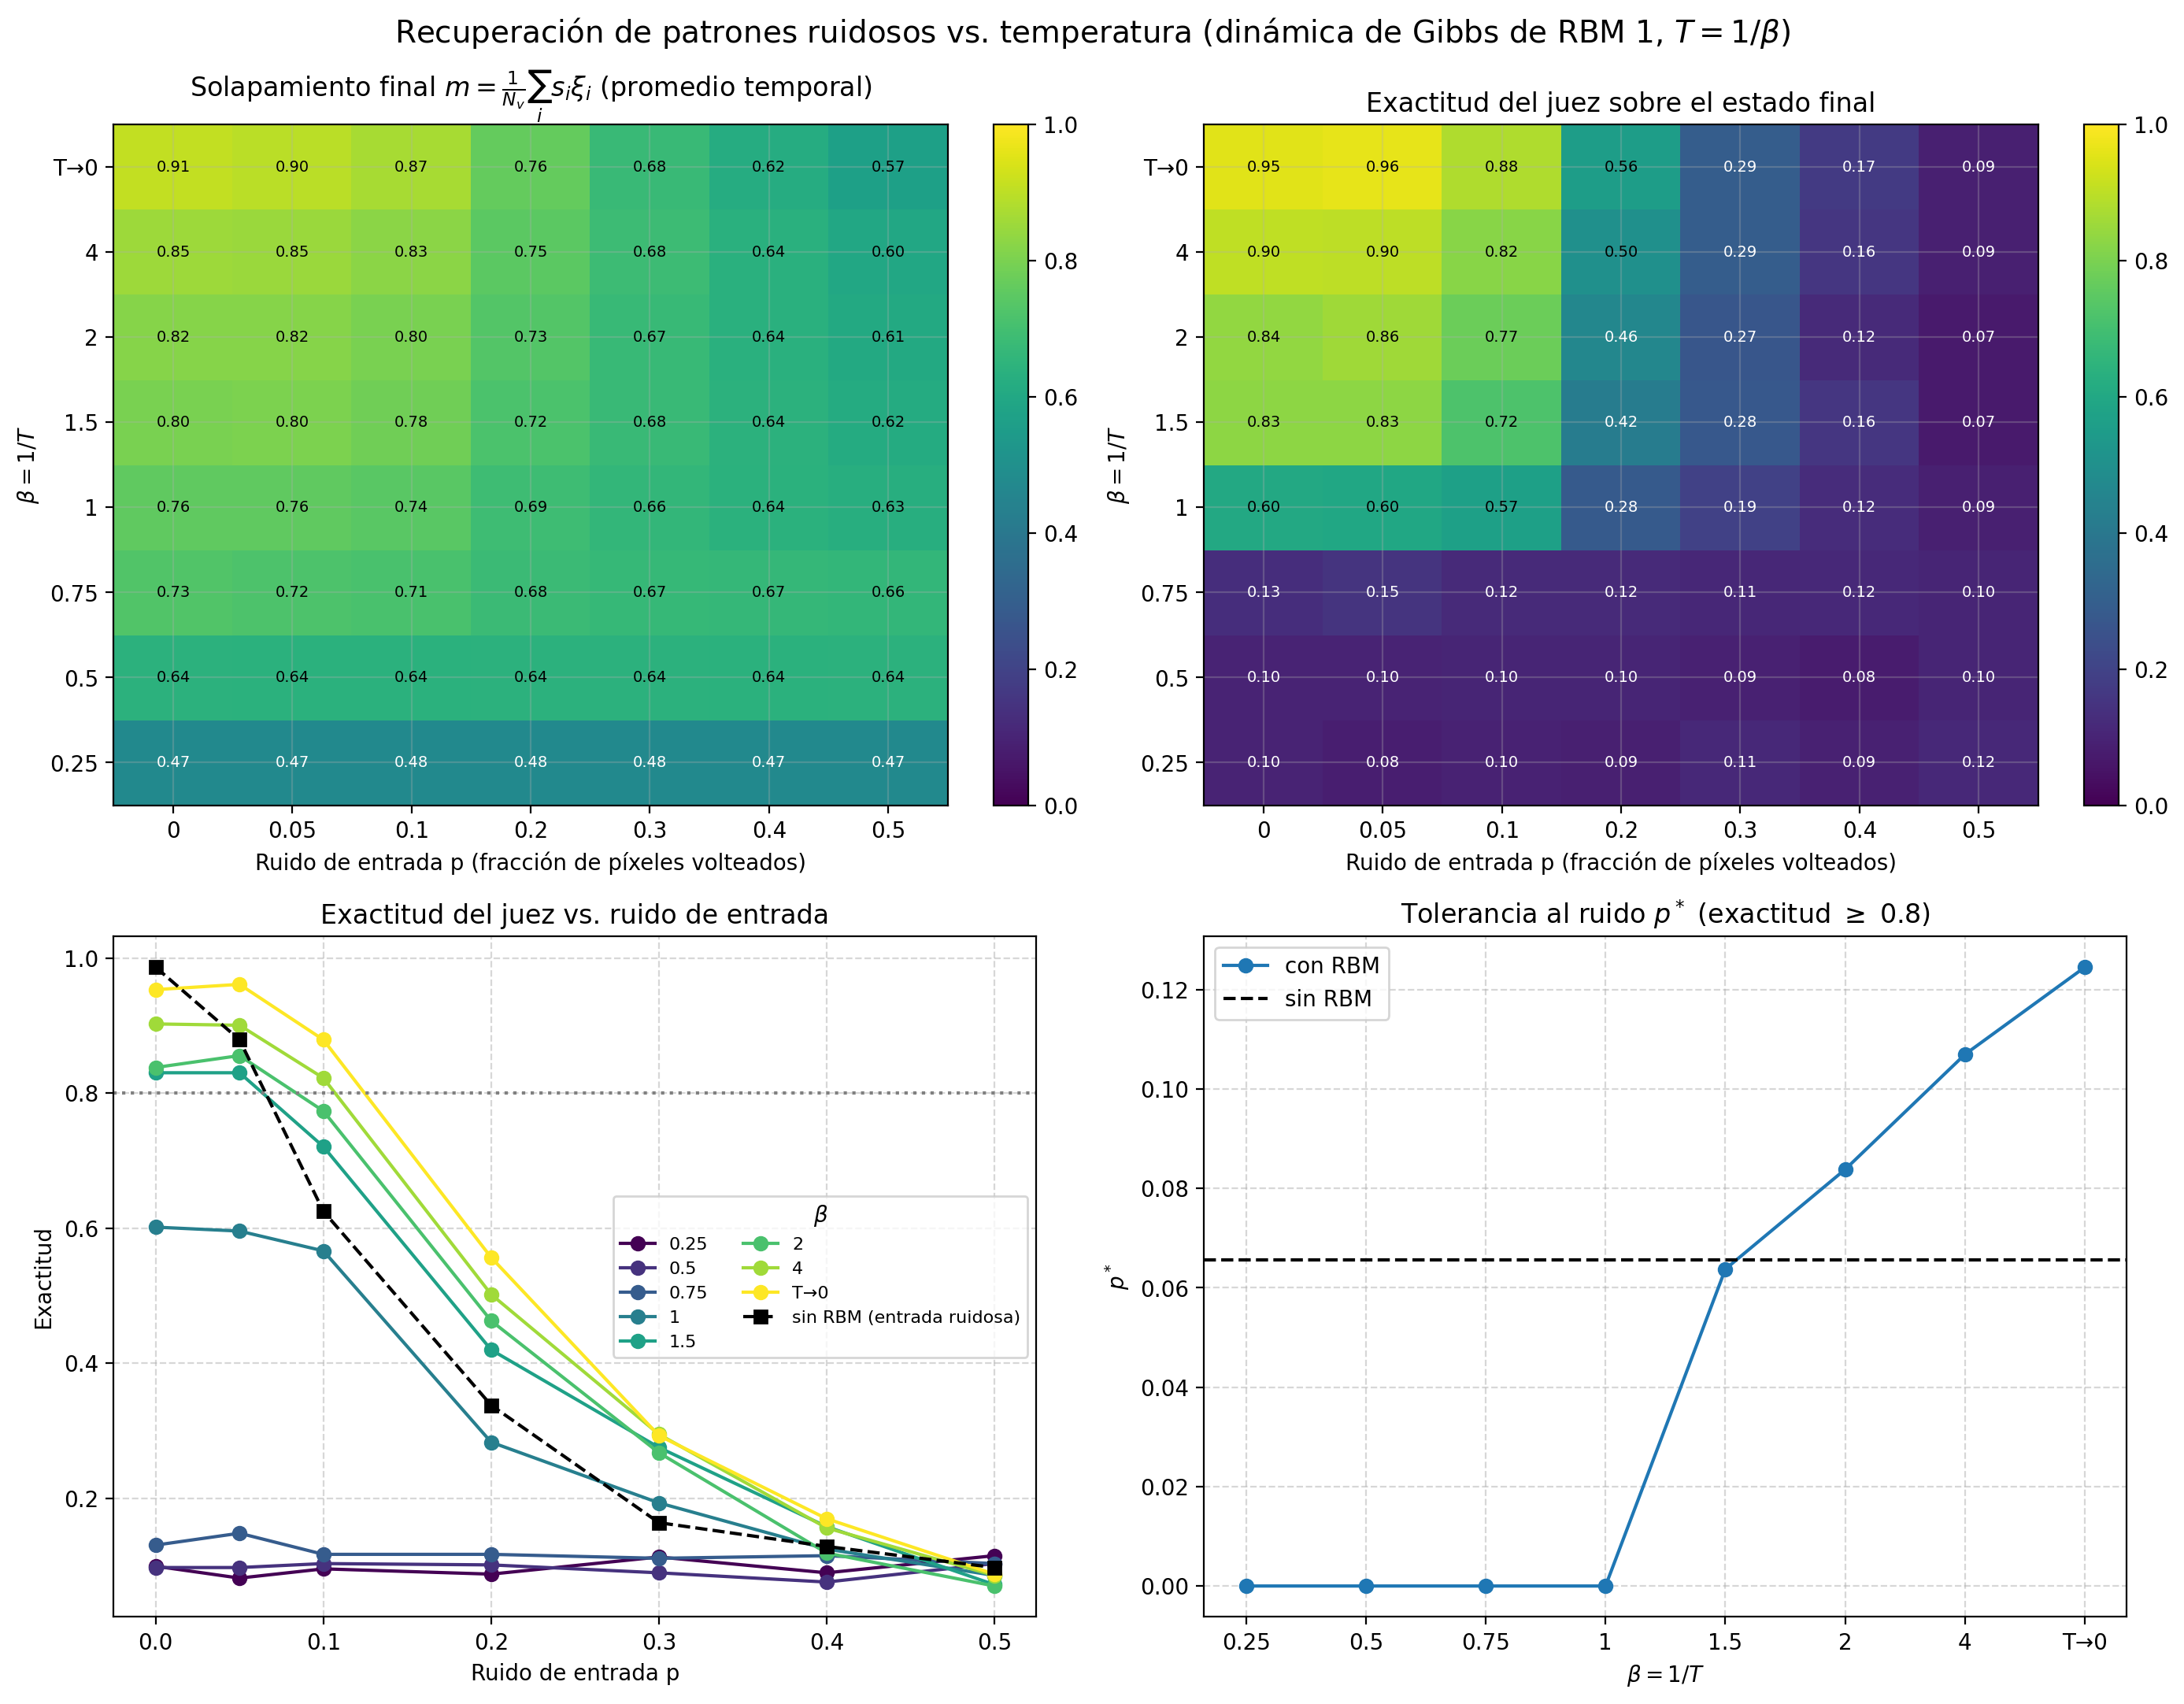

In [ ]:
from IPython.display import Image, display
display(Image(filename="resultados_dbn/obj4_recuperacion_vs_temperatura.png"))

**Qué se observa.** La exactitud del clasificador-juez tras 100 pasos de Gibbs depende fuertemente de la temperatura. A $\beta\le0.75$ es de azar (0.07–0.15). A $\beta=1$ (temperatura de entrenamiento) prácticamente no ayuda con ruido ($p=0.2$: 0.32 vs 0.33 sin RBM; $p=0.3$: 0.19 vs 0.16) y **empeora** la imagen limpia (0.61 vs 0.98) y el ruido leve ($p=0.1$: 0.54 vs 0.63). A $\beta\ge1.5$ la RBM ayuda: con $p=0.1$ pasa de 0.63 (sin RBM) a 0.77 ($\beta=1.5$), 0.79 ($\beta=2$), 0.81 ($\beta=4$) y 0.86 ($T=0$); con $p=0.2$, de 0.33 a 0.56 ($T=0$). El ruido máximo tolerado con exactitud $\ge0.8$ sube de ≈0.067 (sin RBM) a ≈0.077 ($\beta=1.5$), ≈0.093 ($\beta=2$), ≈0.103 ($\beta=4$) y ≈0.121 ($T=0$). Para $p\ge0.4$ ya no hay ganancia.

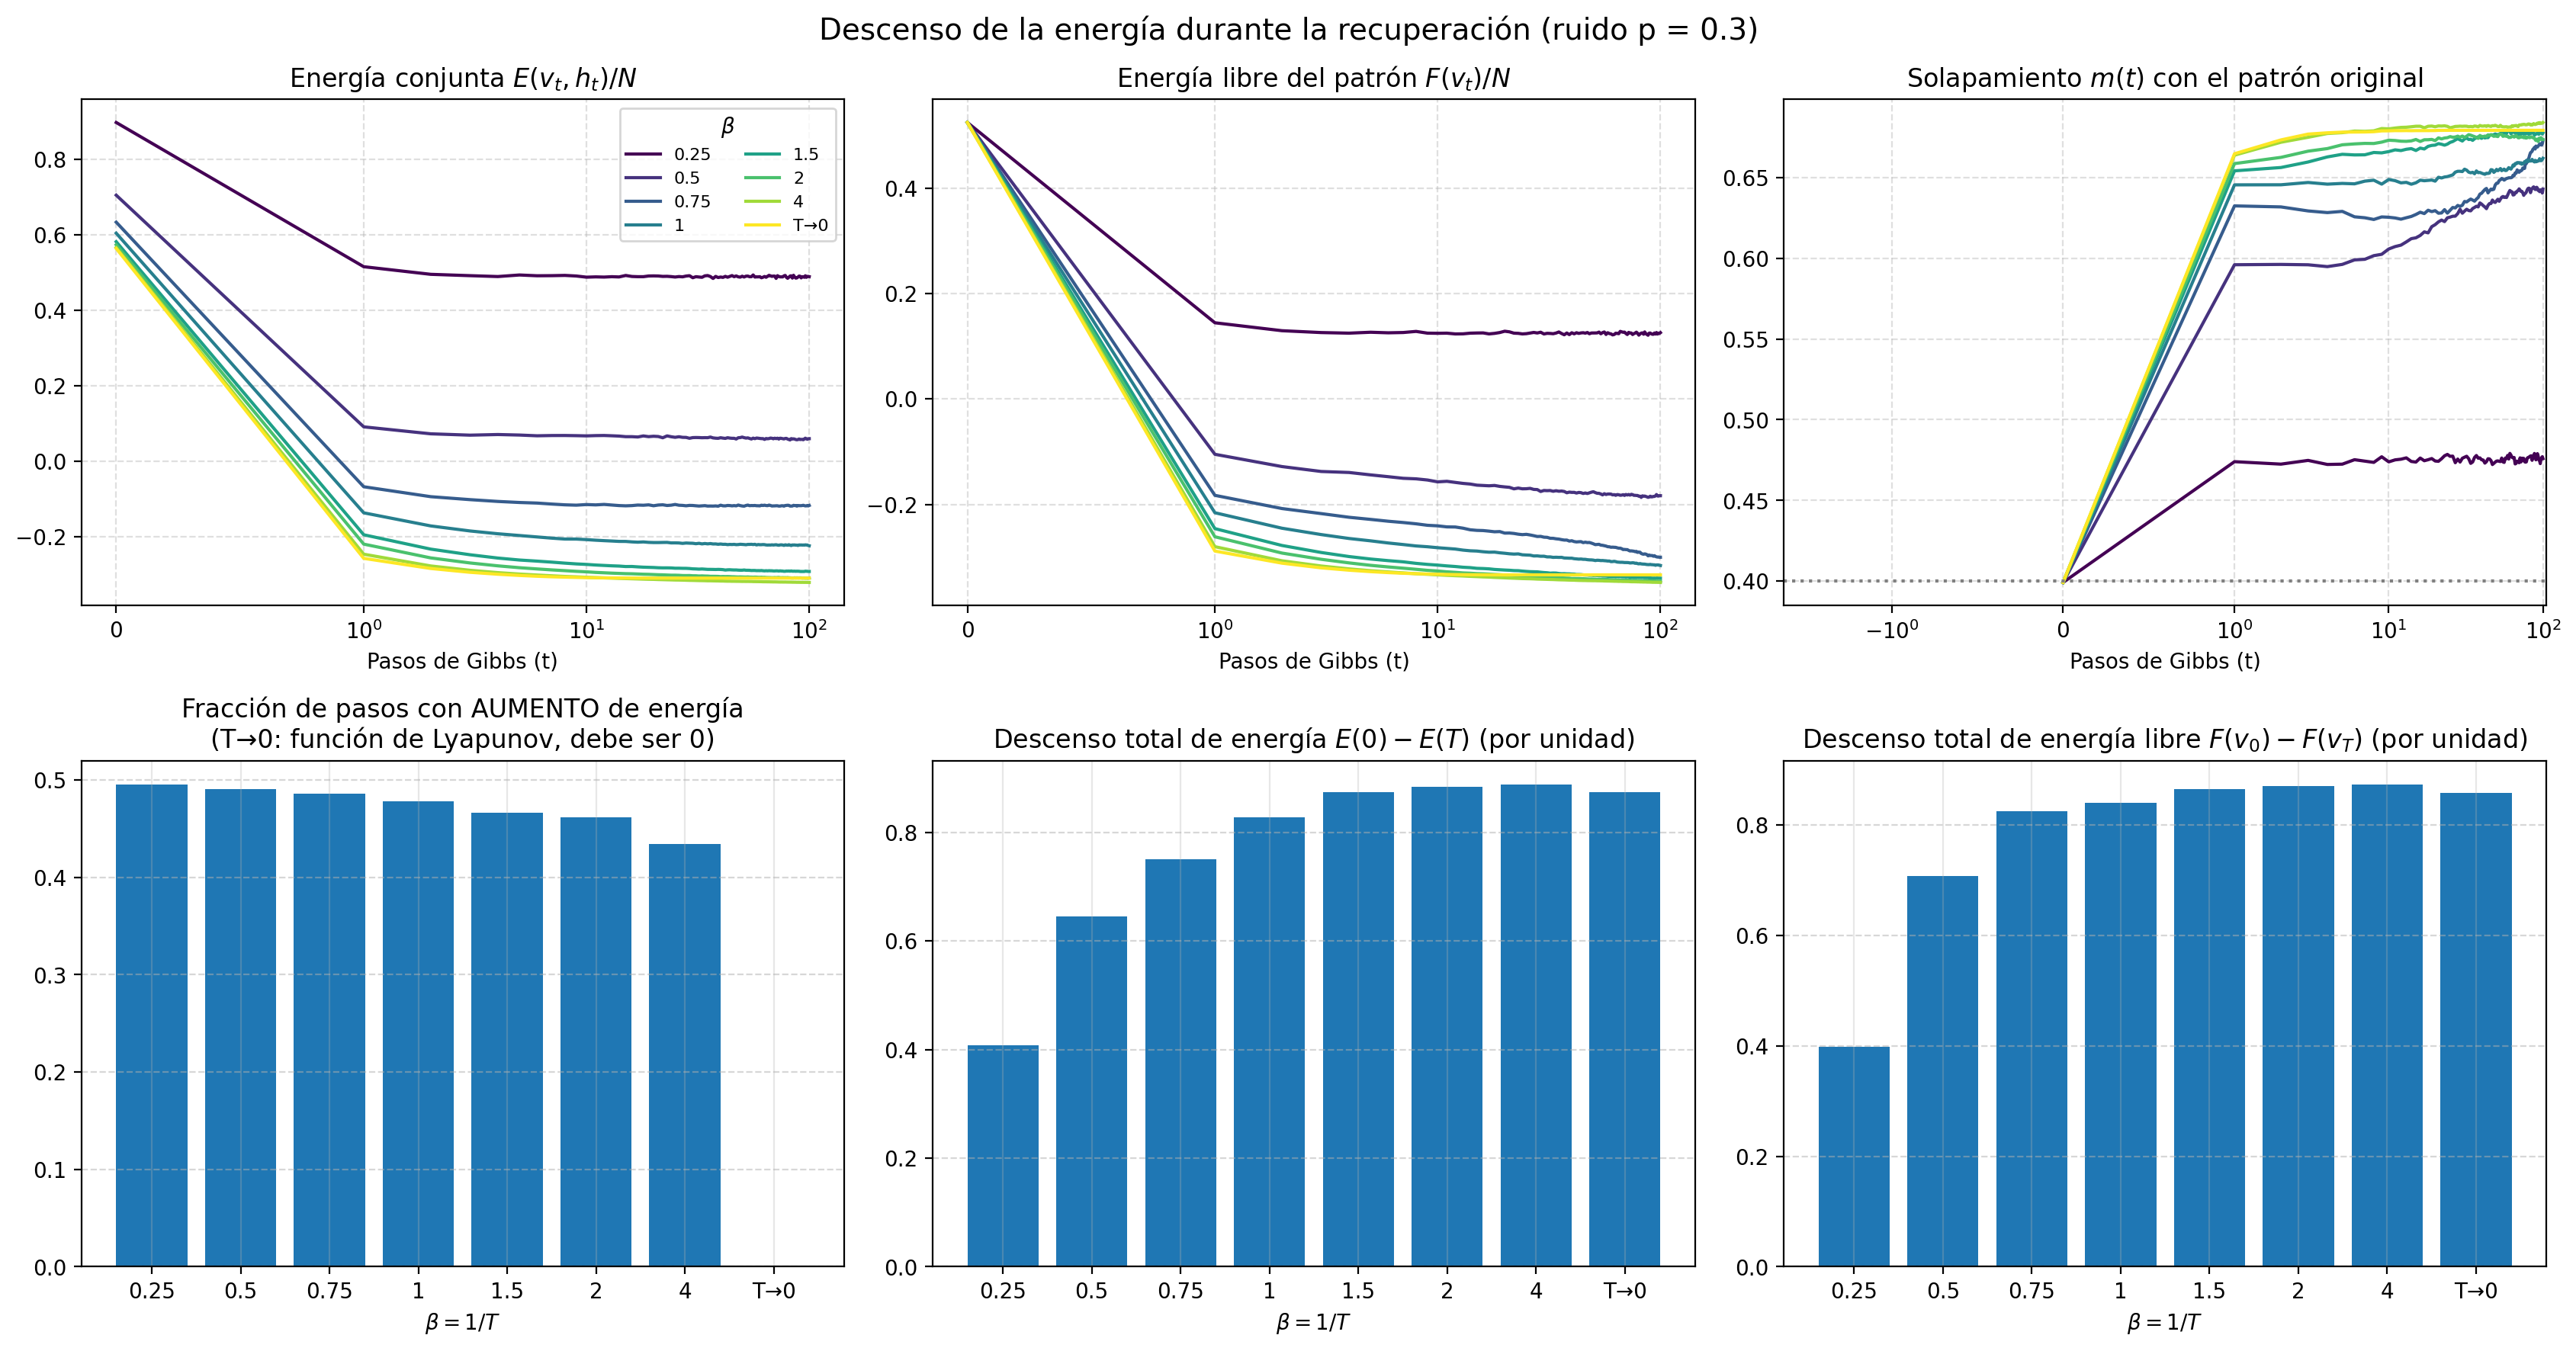

In [ ]:
display(Image(filename="resultados_dbn/obj4_descenso_energia.png"))

**Qué se observa.** En todas las temperaturas casi todo el descenso de energía ocurre en el **primer** paso de Gibbs y luego la energía se estaciona en un valor que baja al enfriar (el plato de $E/N$ pasa de ≈0.49 en $\beta=0.25$ a ≈$-0.33$ en $T=0$). A $T=0$ la fracción de pasos con aumento de energía es **exactamente 0** (función de Lyapunov verificada también en MNIST); a $\beta=4$ todavía es ≈0.43. El solapamiento con el dígito original sube de 0.40 (entrada con 30 % de ruido) a ≈0.65 en un paso y a ≈0.68 al final para $\beta\ge1.5$.

### 6.8 Resumen de métricas

In [ ]:
# ======================= Resumen =======================
with open("resultados_dbn/resumen_metricas.json", "w", encoding="utf-8") as f:
    json.dump(_py(summary), f, indent=2, ensure_ascii=False)
print("\n   [+] Resumen de métricas guardado en: resultados_dbn/resumen_metricas.json")


   [+] Resumen de métricas guardado en: resultados_dbn/resumen_metricas.json


---
**Nota sobre las figuras restantes de la sección 6.** El script guarda en `resultados_dbn/` las figuras `obj2_*`, `obj3_*` y `obj4_*` (relajación, espectro, termodinámica, filtros, ejemplos de reconstrucción y matrices de confusión); al volver a ejecutar la Parte II en Colab quedan impresas aquí.